In [81]:
import pandas as pd
lf = pd.read_parquet(r"data\train\lf_1s.parquet")
particles = pd.read_parquet(r"data\train\particles.parquet")
channels = pd.read_csv(r"data\channels.csv")
lf_test = pd.read_parquet(r"data\test\lf_1s.parquet")
lf_validate = pd.read_parquet(r"data\validation\lf_1s.parquet")


In [83]:
lf.head(5)

,experiment,run,run_num,file,session,file_seq,chunk,second,timestamp,test_hours,...,ci_rms,ci_rms_tsa,ci_rms_e_op,ci_skew_e_op,ci_v_peak_mmps,ctx_accel1_rms,ctx_accel2_rms,ctx_pau_speed,ctx_pau_torque,ctx_temperature
0,Exp-A,Run-1,1,Exp-A_Run-1_LF_Dyno_Gear233Run1_00000.hdf5,Gear233Run1,0,0,0,2024-09-16 14:19:14.205228,0.000278,...,0.033175,0.134464,0.004198,0.412097,0.003350,0.141917,0.135632,160.046112,15.593956,69.260002
1,Exp-A,Run-1,1,Exp-A_Run-1_LF_Dyno_Gear233Run1_00000.hdf5,Gear233Run1,0,0,1,2024-09-16 14:19:15.205228,0.000556,...,0.034503,0.133983,0.003321,0.757347,0.003556,0.140188,0.135196,167.362183,14.434410,69.440002
2,Exp-A,Run-1,1,Exp-A_Run-1_LF_Dyno_Gear233Run1_00000.hdf5,Gear233Run1,0,0,2,2024-09-16 14:19:16.205228,0.000833,...,0.037016,0.133838,0.003779,1.628763,0.003892,0.148295,0.137105,175.524719,14.531036,69.440002
3,Exp-A,Run-1,1,Exp-A_Run-1_LF_Dyno_Gear233Run1_00000.hdf5,Gear233Run1,0,0,3,2024-09-16 14:19:17.205228,0.001111,...,0.038748,0.133898,0.003898,1.249708,0.002762,0.150340,0.137990,181.206680,14.917549,69.440002
4,Exp-A,Run-1,1,Exp-A_Run-1_LF_Dyno_Gear233Run1_00000.hdf5,Gear233Run1,0,0,4,2024-09-16 14:19:18.205228,0.001389,...,0.043991,0.134743,0.004484,0.827841,0.004165,0.149622,0.136447,188.460968,14.917549,69.440002


In [85]:
# print(lf.columns, lf.head(5))
# print(particles.columns, particles.head(5))
# print(channels.columns, channels.head(5))

# **Start Supervised Learning Section**

Create a seperate Dataframe for each experiment.  I will use 3 of the experiments for training and 1 for testing / validation.  I also choose to drop na columns at this stage.  There are lots of datapoints and dropping the rows with NAN values seems to be the best option.


In [89]:

EXP_A_df= lf[lf['experiment']=='Exp-A'].dropna()
EXP_B_df= lf[lf['experiment']=='Exp-B'].dropna()
EXP_C_df= lf[lf['experiment']=='Exp-C'].dropna()
EXP_F_df= lf[lf['experiment']=='Exp-F'].dropna()
print(EXP_C_df.columns)
EXP_F_df.head()

Index(['experiment', 'run', 'run_num', 'file', 'session', 'file_seq', 'chunk',
       'second', 'timestamp', 'test_hours', 'ci_5_e_op', 'ci_6_e_op', 'ci_alr',
       'ci_fleet_wtmade', 'ci_fm0', 'ci_fm4', 'ci_fm4star', 'ci_m6a',
       'ci_m6astar', 'ci_m8a', 'ci_m8astar', 'ci_na4', 'ci_na4star',
       'ci_crest_tsa', 'ci_crest_e_op', 'ci_e_ratio', 'ci_kurtosis',
       'ci_kurtosis_tsa', 'ci_kurtosis_e_op', 'ci_ptp', 'ci_ptp_e_op',
       'ci_rms', 'ci_rms_tsa', 'ci_rms_e_op', 'ci_skew_e_op', 'ci_v_peak_mmps',
       'ctx_accel1_rms', 'ctx_accel2_rms', 'ctx_pau_speed', 'ctx_pau_torque',
       'ctx_temperature'],
      dtype='str')


,experiment,run,run_num,file,session,file_seq,chunk,second,timestamp,test_hours,...,ci_rms,ci_rms_tsa,ci_rms_e_op,ci_skew_e_op,ci_v_peak_mmps,ctx_accel1_rms,ctx_accel2_rms,ctx_pau_speed,ctx_pau_torque,ctx_temperature
519360,Exp-F,Run-1,1,Exp-F_Run-1_LF_Dyno_Gear309Run1_00000.hdf5,Gear309Run1,0,0,52,2025-02-28 14:33:56.580845,0.014722,...,0.032910,0.132413,0.004684,0.552073,0.003122,0.140707,0.132612,157.058548,15.400704,67.639999
519361,Exp-F,Run-1,1,Exp-F_Run-1_LF_Dyno_Gear309Run1_00000.hdf5,Gear309Run1,0,0,53,2025-02-28 14:33:57.580845,0.015000,...,0.034989,0.133016,0.003458,0.192395,0.002796,0.140652,0.134849,163.971771,15.690592,67.639999
519362,Exp-F,Run-1,1,Exp-F_Run-1_LF_Dyno_Gear309Run1_00000.hdf5,Gear309Run1,0,0,54,2025-02-28 14:33:58.580845,0.015278,...,0.035453,0.131645,0.003198,0.235828,0.003354,0.143138,0.132847,171.254929,14.434413,67.639999
519363,Exp-F,Run-1,1,Exp-F_Run-1_LF_Dyno_Gear309Run1_00000.hdf5,Gear309Run1,0,0,55,2025-02-28 14:33:59.580845,0.015556,...,0.038602,0.133111,0.003807,1.148549,0.003517,0.146403,0.134358,177.802124,14.820924,67.639999
519364,Exp-F,Run-1,1,Exp-F_Run-1_LF_Dyno_Gear309Run1_00000.hdf5,Gear309Run1,0,0,56,2025-02-28 14:34:00.580845,0.015833,...,0.039316,0.132024,0.004233,0.489381,0.003157,0.145992,0.135269,185.022644,14.337771,67.639999


# Bringing in the image labels/scoring values

In [100]:
#Load Label csv into a pandas df

label_df_A = pd.read_csv(r"data\labels\Condition Labels - Exp_A.csv")
label_df_B = pd.read_csv(r"data\labels\Condition Labels - Exp_B.csv")
label_df_C = pd.read_csv(r"data\labels\Condition Labels - Exp_C.csv")
label_df_F = pd.read_csv(r"data\labels\Condition Labels - Exp_F.csv")

label_df_A.head()

,Tooth,Run_1,Run_2,Run_3,Run_4,Run_5
0,1,1,1,1.0,1.1,1.2
1,2,1,1,1.0,1.1,1.1
2,3,1,1,1.0,1.0,1.1
3,4,1,1,1.0,1.1,1.1
4,5,1,1,1.0,1.5,1.5


# Assigning Scores for the entire Gear for each run.  
Here I will consider the condition given for each tooth and essentially take the mean of the top 90th percentile.  (I can change to 95th or 99th percentile if I see that the damage score assigned is not high enough)

In [103]:
import re
import numpy as np
import pandas as pd

def extract_run_gt_from_label_df(
    label_df,
    *,
    tooth_col="tooth_number",
    run_prefix="Run_",
    percentile=90
):
    """
    label_df: columns include tooth_col and run columns like Run_1, Run_2, ...
    Returns: DataFrame with columns ['run_num', 'gt_condition'] where
      gt_condition(run) = percentile of tooth values across teeth for that run.
    """
    if tooth_col not in label_df.columns:
        raise ValueError(f"Expected tooth column '{tooth_col}' not found in label_df columns.")

    run_cols = [c for c in label_df.columns if str(c).startswith(run_prefix)]
    if not run_cols:
        raise ValueError(f"No run columns found starting with '{run_prefix}'. Found: {label_df.columns.tolist()}")

    rows = []
    for c in run_cols:
        m = re.search(rf"{re.escape(run_prefix)}(\d+)", str(c))
        if not m:
            continue
        run_num = int(m.group(1))

        tooth_vals = pd.to_numeric(label_df[c], errors="coerce").to_numpy()
        scalar = np.nanpercentile(tooth_vals, percentile)

        rows.append({"run_num": run_num, "gt_condition": scalar})

    return pd.DataFrame(rows).sort_values("run_num").reset_index(drop=True)


def add_gt_to_experiment_df(
    exp_df,
    gt_run_df,
    *,
    exp_run_col="run_num",
    target_col="gt_condition"
):
    """
    Adds target_col to exp_df by merging gt_run_df on run number.
    """
    if exp_run_col not in exp_df.columns:
        raise ValueError(f"Expected '{exp_run_col}' in exp_df columns.")
    if exp_run_col not in gt_run_df.columns:
        raise ValueError(f"Expected '{exp_run_col}' in gt_run_df columns.")
    if "gt_condition" not in gt_run_df.columns:
        raise ValueError("gt_run_df must contain 'gt_condition'.")

    out = exp_df.merge(
        gt_run_df[[exp_run_col, "gt_condition"]],
        how="left",
        on=exp_run_col
    )
    return out



# inputs
TOOTH_COL = "Tooth"
RUN_COL = "run_num"
PERCENTILE = 99



# Exp A
gt_A = extract_run_gt_from_label_df(label_df_A, tooth_col=TOOTH_COL, percentile=PERCENTILE)
EXP_A_df = EXP_A_df.loc[EXP_A_df[RUN_COL] != 1].copy()  # required removal
EXP_A_df = add_gt_to_experiment_df(EXP_A_df, gt_A, exp_run_col=RUN_COL)

# EXP B
gt_B = extract_run_gt_from_label_df(label_df_B, tooth_col=TOOTH_COL, percentile=PERCENTILE)
EXP_B_df = add_gt_to_experiment_df(EXP_B_df, gt_B, exp_run_col=RUN_COL)

# EXP C
gt_C = extract_run_gt_from_label_df(label_df_C, tooth_col=TOOTH_COL, percentile=PERCENTILE)
EXP_C_df = add_gt_to_experiment_df(EXP_C_df, gt_C, exp_run_col=RUN_COL)

# EXP F
gt_F = extract_run_gt_from_label_df(label_df_F, tooth_col=TOOTH_COL, percentile=PERCENTILE)
EXP_F_df = add_gt_to_experiment_df(EXP_F_df, gt_F, exp_run_col=RUN_COL)

In [105]:
import numpy as np
import pandas as pd

# --- Remove run 1 from EXP_A (required)
#EXP_A_df = EXP_A_df.loc[EXP_A_df["run_num"] != 1].copy()

# Add an experiment label if not already present
EXP_A_df["experiment"] = "A"
EXP_B_df["experiment"] = "B"
EXP_C_df["experiment"] = "C"
EXP_F_df["experiment"] = "F"

# Combine
df_all = pd.concat([EXP_A_df, EXP_B_df, EXP_C_df, EXP_F_df], ignore_index=True)

# Target sanity
df_all["gt_condition"] = pd.to_numeric(df_all["gt_condition"], errors="coerce")
df_all = df_all.dropna(subset=["gt_condition", "run_num"])

df_all["run_num"] = pd.to_numeric(df_all["run_num"], errors="coerce")
df_all = df_all.dropna(subset=["run_num"])

print(df_all.shape)
df_all["experiment"].value_counts()

(627477, 42)


experiment
C    264942
B    141302
F    134569
A     86664
Name: count, dtype: int64

**Determine which columns should not be used as features**

In [108]:
#columns not to use as features
non_feature_cols = {
    "gt_condition", "experiment", "run","run_num", "file", "session", "file_seq",
    "chunk", "timestamp"
}

# candidate numeric features
candidate_cols = [
    c for c in df_all.columns
    if c not in non_feature_cols
]

# keep numeric only
numeric_feature_cols = []
for c in candidate_cols:
    if pd.api.types.is_numeric_dtype(df_all[c]):
        numeric_feature_cols.append(c)

print("Num numeric candidate features:", len(numeric_feature_cols))
numeric_feature_cols[:10]

Num numeric candidate features: 33


['second',
 'test_hours',
 'ci_5_e_op',
 'ci_6_e_op',
 'ci_alr',
 'ci_fleet_wtmade',
 'ci_fm0',
 'ci_fm4',
 'ci_fm4star',
 'ci_m6a']

**Plot distribution of gear conditions to see how many 1, 2, 3 there are.**  
Also Plot the condition level for each gear per run.

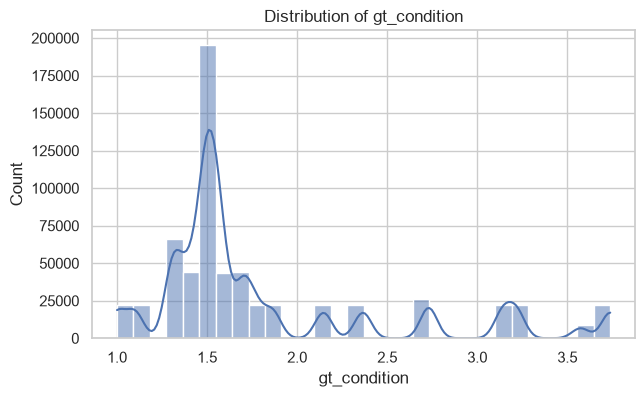

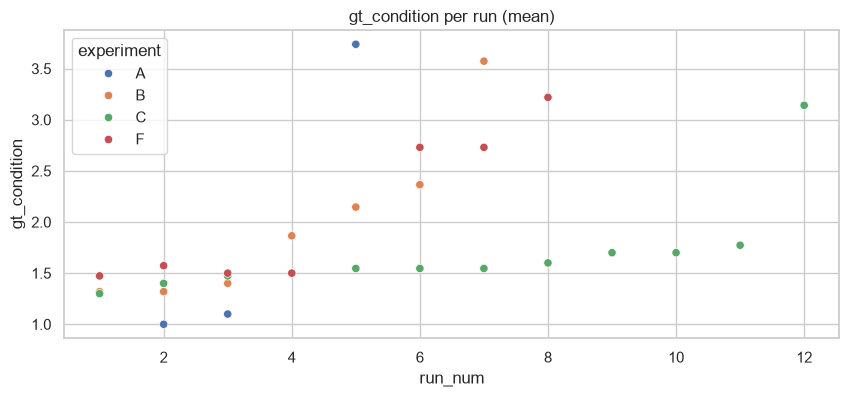

In [111]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")

plt.figure(figsize=(7,4))
sns.histplot(df_all["gt_condition"], bins=30, kde=True)
plt.title("Distribution of gt_condition")
plt.show()

# mean gt per run (should be constant per run)
plt.figure(figsize=(10,4))
run_gt = df_all.groupby(["experiment","run_num"])["gt_condition"].mean().reset_index()
sns.scatterplot(data=run_gt, x="run_num", y="gt_condition", hue="experiment")
plt.title("gt_condition per run (mean)")
plt.show()

**Perform a correlation analysis to see which Condition indicators could be good candidates to include in the model.**  

Looking for strong positive or negative correlation to the Gear condition ground truth labels.

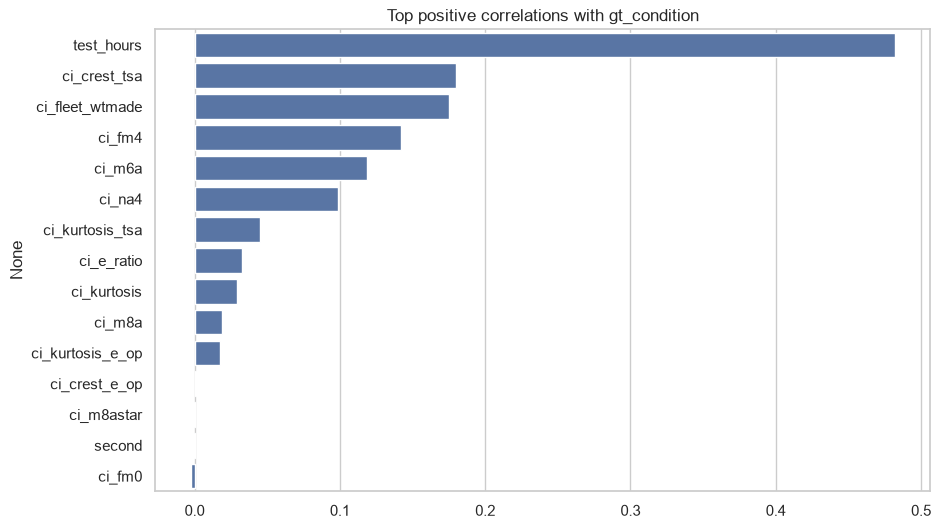

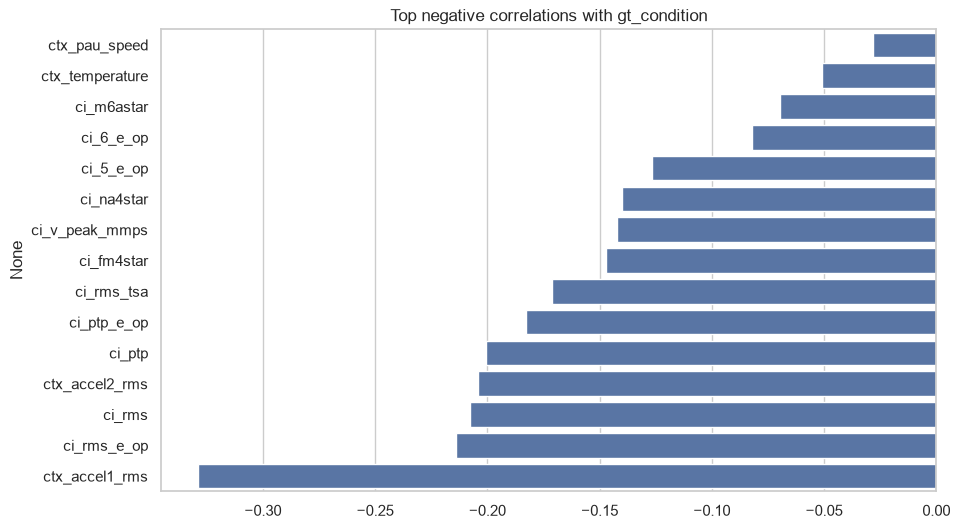

In [114]:
# correlation with target
corr = df_all[numeric_feature_cols].corrwith(df_all["gt_condition"])
corr = corr.dropna().sort_values(ascending=False)

top_pos = corr.head(15)
top_neg = corr.tail(15)

plt.figure(figsize=(10,6))
sns.barplot(x=top_pos.values, y=top_pos.index)
plt.title("Top positive correlations with gt_condition")
plt.show()

plt.figure(figsize=(10,6))
sns.barplot(x=top_neg.values, y=top_neg.index)
plt.title("Top negative correlations with gt_condition")
plt.show()

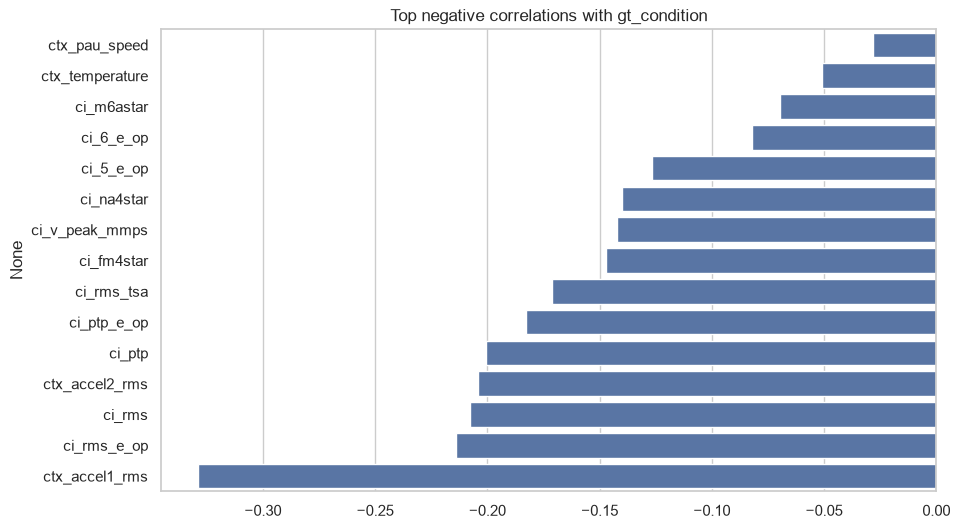

Kept after variance filter: 33


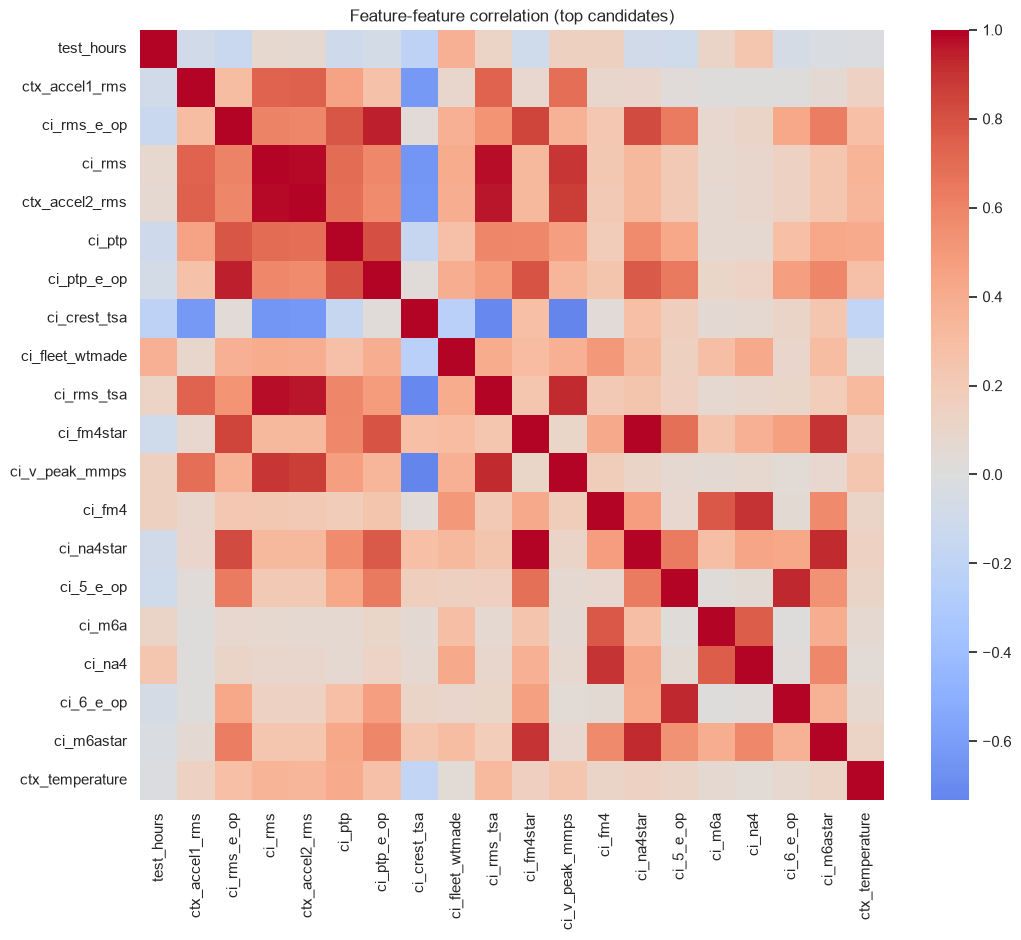

In [116]:
plt.figure(figsize=(10,6))
sns.barplot(x=top_neg.values, y=top_neg.index)
plt.title("Top negative correlations with gt_condition")
plt.show()
# Reduce noise: remove near-constant features

from sklearn.feature_selection import VarianceThreshold

X = df_all[numeric_feature_cols].copy()
X_num = X.apply(pd.to_numeric, errors="coerce")

vt = VarianceThreshold(threshold=1e-6)
vt.fit(X_num.fillna(X_num.mean(numeric_only=True)))

kept_cols = [numeric_feature_cols[i] for i in range(len(numeric_feature_cols)) if vt.get_support()[i]]
print("Kept after variance filter:", len(kept_cols))
kept_cols[:10]
# Correlation heatmap (optional, for multicollinearity awareness)

# pick a small subset for the heatmap (e.g., top 20 by abs correlation)
top_abs = corr.abs().sort_values(ascending=False).head(20).index.tolist()
plot_cols = [c for c in top_abs if c in kept_cols]

plt.figure(figsize=(12,10))
sns.heatmap(df_all[plot_cols].corr(), cmap="coolwarm", center=0)
plt.title("Feature-feature correlation (top candidates)")
plt.show()

In [117]:
def transform_experiment_df(df, ci_columns, baseline_cols,
                             groupby_col='run_num', baseline_rows=1600):
    """
    Filters, aggregates (p95), baseline-subtracts, and normalizes
    experiment data at the run level.
    """

    # Filter rows ---
    df_filtered = df[
        (df['ctx_temperature'] > 115) &
        (df['ctx_pau_speed'] > 1399)
    ].dropna()

    # Compute baseline values from first N filtered rows ---
    baseline_df = df_filtered.head(baseline_rows)
    baseline_values = baseline_df[baseline_cols].mean()

    # Baseline-subtract relevant columns (row-level)
    for col in baseline_cols:
        df_filtered[f'{col}_baseline_sub'] = df_filtered[col] - baseline_values[col]


    def p95(x):
        return x.quantile(0.95)

    # Build aggregation dict
    agg_dict = {col: p95 for col in ci_columns}
    agg_dict.update({col: p95 for col in baseline_cols})
    agg_dict.update({f'{col}_baseline_sub': p95 for col in baseline_cols})
    agg_dict['test_hours'] = 'max'
    agg_dict['gt_condition'] = 'max'

    # Group by run and aggregate
    df_trans = df_filtered.groupby(groupby_col).agg(agg_dict).reset_index()

    # Run-level min-max normalization of baseline-subtracted features
    for col in baseline_cols:
        sub_col = f'{col}_baseline_sub'
        min_val = df_trans[sub_col].min()
        max_val = df_trans[sub_col].max()
        denom = (max_val - min_val) if (max_val - min_val) != 0 else 1
        df_trans[f'{col}_norm'] = (df_trans[sub_col] - min_val) / denom

    return df_trans
ci_columns = [
'ci_5_e_op', 'ci_6_e_op', 'ci_alr', 'ci_fleet_wtmade', 'ci_fm0',
'ci_fm4', 'ci_fm4star', 'ci_m6a', 'ci_m6astar', 'ci_m8a', 'ci_m8astar',
'ci_na4', 'ci_na4star', 'ci_crest_tsa', 'ci_crest_e_op', 'ci_e_ratio',
'ci_kurtosis', 'ci_kurtosis_tsa', 'ci_kurtosis_e_op', 'ci_ptp',
'ci_ptp_e_op', 'ci_rms', 'ci_rms_tsa', 'ci_rms_e_op', 'ci_skew_e_op',
'ci_v_peak_mmps', 'ctx_accel1_rms', 'ctx_accel2_rms'
]

baseline_columns = [
'ci_5_e_op', 'ci_6_e_op', 'ci_alr', 'ci_fleet_wtmade', 'ci_fm0',
'ci_fm4', 'ci_fm4star', 'ci_m6a', 'ci_m6astar', 'ci_m8a', 'ci_m8astar',
'ci_na4', 'ci_na4star', 'ci_crest_tsa', 'ci_crest_e_op', 'ci_e_ratio',
'ci_kurtosis', 'ci_kurtosis_tsa', 'ci_kurtosis_e_op', 'ci_ptp',
'ci_ptp_e_op', 'ci_rms', 'ci_rms_tsa', 'ci_rms_e_op', 'ci_skew_e_op',
'ci_v_peak_mmps', 'ctx_accel1_rms', 'ctx_accel2_rms'
]


EXP_A_df_trans = transform_experiment_df(EXP_A_df,ci_columns=ci_columns, baseline_cols = baseline_columns)
EXP_B_df_trans = transform_experiment_df(EXP_B_df,ci_columns=ci_columns, baseline_cols = baseline_columns)
EXP_C_df_trans = transform_experiment_df(EXP_C_df,ci_columns=ci_columns, baseline_cols = baseline_columns)
EXP_F_df_trans = transform_experiment_df(EXP_F_df,ci_columns=ci_columns, baseline_cols = baseline_columns)

**Create a PCA feature from 3 columns.**

In [122]:
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

def create_pca_feature(df, columns, new_feature_name="PCA_Feature"):
    """
    Creates a PCA feature from specified columns in a DataFrame.

    Parameters:
        df (pd.DataFrame): Input DataFrame.
        columns (list): List of column names to use for PCA.
        new_feature_name (str): Name of the new PCA feature column.

    Returns:
        pd.DataFrame: DataFrame with the new PCA feature added.
    """
    # Validate columns
    for col in columns:
        if col not in df.columns:
            raise ValueError(f"Column '{col}' not found in DataFrame.")

    # Extract the specified columns
    data_subset = df[columns]

    # Ensure numeric data
    if not all(pd.api.types.is_numeric_dtype(data_subset[col]) for col in columns):
        raise ValueError("All specified columns must be numeric.")

    # Handle missing values
    if data_subset.isnull().any().any():
        raise ValueError("Specified columns contain NaN values. Please handle them before PCA.")

    # Standardize the data
    scaler = StandardScaler()
    scaled_data = scaler.fit_transform(data_subset)

    # Apply PCA to get the first principal component
    pca = PCA(n_components=1)
    pca_feature = pca.fit_transform(scaled_data)

    # Add the new PCA feature to the DataFrame
    df[new_feature_name] = pca_feature

    return df

CI_list=['ci_fleet_wtmade_norm', 'ci_fm4star_norm',
       'ci_m6astar_norm']
EXP_A_df_trans = create_pca_feature(EXP_A_df_trans, CI_list, new_feature_name="PCA")
EXP_B_df_trans = create_pca_feature(EXP_B_df_trans, CI_list, new_feature_name="PCA")
EXP_C_df_trans = create_pca_feature(EXP_C_df_trans, CI_list, new_feature_name="PCA")
EXP_F_df_trans = create_pca_feature(EXP_F_df_trans, CI_list, new_feature_name="PCA")

**Plot up to five features against the Gear Condition Labels**

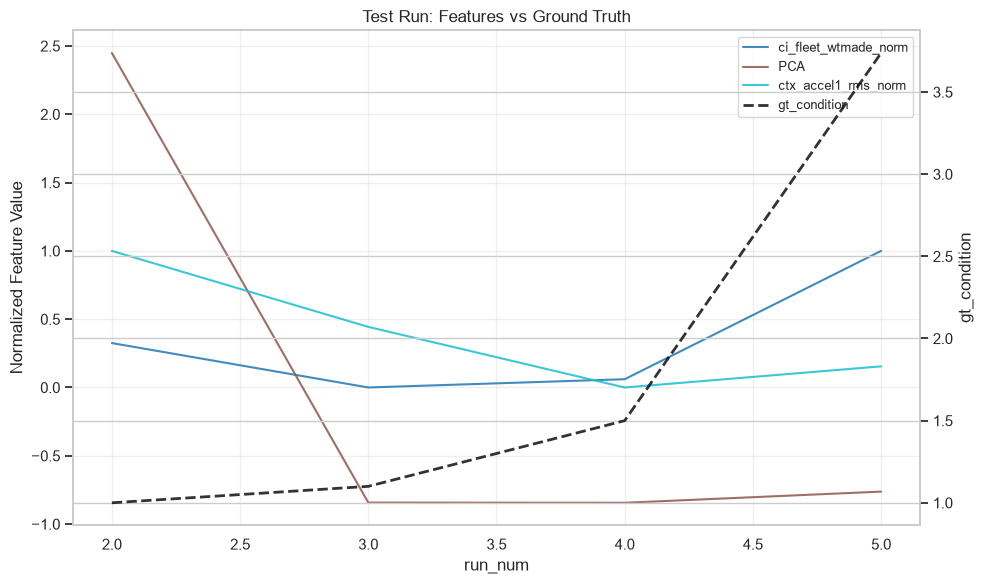

In [126]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def plot_features_lines_vs_gt_condition(
    df,
    feature_cols,
    target_col="gt_condition",
    x_axis="run_num",          # "index" or a column name (e.g., "time", "cycle")
    show_gt=True,
    gt_on_secondary_axis=True,
    figsize=(10, 6),
    title=None,
):
    """
    Plots up to 5 (normalized) features as overlaid line plots on a single
    chart, optionally with the ground truth target plotted alongside
    (on a secondary y-axis by default).
    """


    if len(feature_cols) > 5:
        print(f"Warning: {len(feature_cols)} features given, only first 5 will be used.")
        feature_cols = feature_cols[:5]

    # X-axis values
    if x_axis == "index":
        x = df.index.values
        x_label = "Index"
    else:
        x = df[x_axis].values
        x_label = x_axis

    fig, ax = plt.subplots(figsize=figsize)

    # Plot each feature as its own line
    colors = plt.cm.tab10(np.linspace(0, 1, len(feature_cols)))
    for feat, color in zip(feature_cols, colors):
        ax.plot(x, df[feat].values, label=feat, color=color, linewidth=1.5, alpha=0.85)

    ax.set_xlabel(x_label)
    ax.set_ylabel("Normalized Feature Value")
    ax.grid(alpha=0.3)

    # Ground truth line
    if show_gt:
        if gt_on_secondary_axis:
            ax2 = ax.twinx()
            ax2.plot(
                x, df[target_col].values,
                label=target_col, color="black", linestyle="--", linewidth=2, alpha=0.8
            )
            ax2.set_ylabel(target_col)
            # Combine legends from both axes
            lines1, labels1 = ax.get_legend_handles_labels()
            lines2, labels2 = ax2.get_legend_handles_labels()
            ax.legend(lines1 + lines2, labels1 + labels2, loc="best", fontsize=9)
        else:
            ax.plot(
                x, df[target_col].values,
                label=target_col, color="black", linestyle="--", linewidth=2, alpha=0.8
            )
            ax.legend(loc="best", fontsize=9)
    else:
        ax.legend(loc="best", fontsize=9)

    ax.set_title(title or f"Normalized Features vs {target_col}", fontsize=12)

    plt.tight_layout()
    plt.show()

    return fig, ax

# Choose which dataframe to plot from
df_to_plot = EXP_A_df_trans   # specify any DF

# Choose up to 5 normalized features
features = ["ci_fleet_wtmade_norm",'PCA', 'ctx_accel1_rms_norm']

fig, ax = plot_features_lines_vs_gt_condition(
    df_to_plot,
    feature_cols=features,
    target_col="gt_condition",
    x_axis="run_num",
    show_gt=True,
    gt_on_secondary_axis=True,   # keep gt_condition on its own scale
    title="Test Run: Features vs Ground Truth",
)

## Plot 1 feature against Ground truth condition label.

Can choose which experiment you want and which feature you want to see.  This allows visualizing what's going on through the run for each feature.

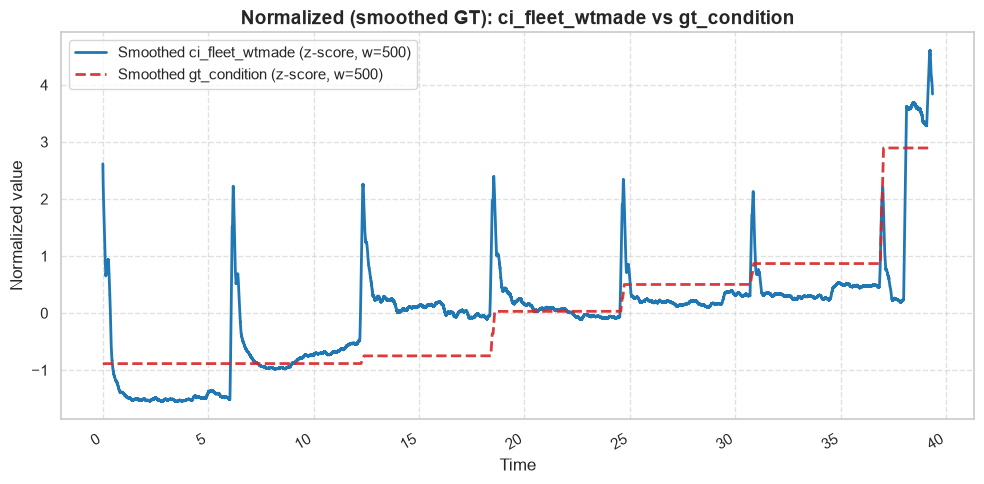

In [129]:
import numpy as np

def plot_feature_and_gt_normalized_smoothed_GT(
    df, feature,
    roll_window=6000,
    time_col="test_hours",
    gt_col="gt_condition",
    normalize="zscore"
):
    import matplotlib.pyplot as plt

    df = df.copy()
    df = df.sort_values(time_col)

    # Rolling mean across full timeline (B)
    df["smoothed_feature"] = (
        df[feature]
        .rolling(window=roll_window, center=True, min_periods=1)
        .mean()
    )

    # Smooth GT as well (so it won't look stepped)
    df["smoothed_gt"] = (
        df[gt_col]
        .rolling(window=roll_window, center=True, min_periods=1)
        .mean()
    )

    x = df["smoothed_feature"].astype(float)
    y = df["smoothed_gt"].astype(float)
    #z = df['ctx_pau_torque'].astype(float)

    if normalize == "zscore":
        x_mean, x_std = np.nanmean(x), np.nanstd(x)
        y_mean, y_std = np.nanmean(y), np.nanstd(y)
        #z_mean, z_std = np.nanmean(z), np.nanstd(z)

        df["x_norm"] = (x - x_mean) / (x_std if x_std != 0 else 1.0)
        df["y_norm"] = (y - y_mean) / (y_std if y_std != 0 else 1.0)
        #df["z_norm"] = (z - z_mean) / (z_std if z_std != 0 else 1.0)
        norm_label = "z-score"

    elif normalize == "minmax":
        x_min, x_max = np.nanmin(x), np.nanmax(x)
        y_min, y_max = np.nanmin(y), np.nanmax(y)
        #z_min, z_max = np.nanmin(z), np.nanmax(z)

        df["x_norm"] = (x - x_min) / (x_max - x_min if x_max != x_min else 1.0)
        df["y_norm"] = (y - y_min) / (y_max - y_min if y_max != y_min else 1.0)
        #df["z_norm"] = (z - z_min) / (z_max - z_min if z_max != z_min else 1.0)
        norm_label = "min-max"

    else:
        raise ValueError("normalize must be 'zscore' or 'minmax'.")

    fig, ax = plt.subplots(figsize=(10, 5))

    ax.plot(
        df[time_col], df["x_norm"],
        color="tab:blue", linewidth=2,
        label=f"Smoothed {feature} ({norm_label}, w={roll_window})"
    )

    ax.plot(
        df[time_col], df["y_norm"],
        color="tab:red", linewidth=2,
        linestyle="--", alpha=0.9,
        label=f"Smoothed {gt_col} ({norm_label}, w={roll_window})"
    )

    #ax.plot(
    #    df[time_col], df['z_norm'],
    #    color="tab:green", linewidth=2,
    #    label=f"Speed, w={roll_window})"
    #)

    ax.set_title(f"Normalized (smoothed GT): {feature} vs {gt_col}", fontsize=14, fontweight="bold")
    ax.set_xlabel("Time")
    ax.set_ylabel("Normalized value")

    ax.grid(True, linestyle="--", alpha=0.6)
    ax.legend()
    fig.autofmt_xdate()
    plt.tight_layout()
    plot = plt.show()
    return plot

#Change feature to be plotted here
plot_feature_and_gt_normalized_smoothed_GT(EXP_B_df, feature="ci_fleet_wtmade", roll_window=500, normalize="zscore")

## Add 2 new Engineered Features

dist_from__so_far and realtive_to_baseline

In [150]:
import numpy as np
import pandas as pd

def add_binary_target_and_features(df, ci_signal_cols=['ci_fleet_wtmade_norm','PCA','ctx_accel1_rms'], baseline_n_runs=2):
    """
    Adds:

      - dist_from_min_so_far: running distance from the best (min) value seen so far
      - relative_to_baseline: ratio of current value to median of first `baseline_n_runs` runs

    """
    df = df.copy()

    # Binary target
    df['gt_binary'] = (df['gt_condition'] > 2.75).astype(int)

    # Robust features per signal
    for col in ci_signal_cols:
        # Running min up to and including current run
        running_min = df[col].cummin()
        df[f'{col}_dist_from_min_so_far'] = df[col] - running_min

        # Baseline = median of first N runs (assumed early = normal)
        baseline_val = df[col].iloc[:baseline_n_runs].median()
        df[f'{col}_relative_to_baseline'] = df[col] / baseline_val if baseline_val != 0 else np.nan

    return df

# Apply to each experiment
EXP_A_df_trans = add_binary_target_and_features(EXP_A_df_trans)
EXP_B_df_trans = add_binary_target_and_features(EXP_B_df_trans)
EXP_C_df_trans = add_binary_target_and_features(EXP_C_df_trans)
EXP_F_df_trans = add_binary_target_and_features(EXP_F_df_trans)

## Test Classifier models

In [135]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
)


# Float gt_condition to class mapping

def map_gt_to_class(x):
    """Bins continuous gt_condition values into classes {1, 2, 3}."""
    x = np.asarray(x, dtype=float)
    cls = np.full(x.shape, np.nan, dtype=float)
    cls[(x >= 1) & (x <= 1.5)] = 1
    cls[(x > 1.5) & (x <= 2.5)] = 2
    cls[x >= 2.5] = 3
    return cls



def run_classification_experiment(
    train_dfs,
    test_df,
    feature_cols=None,
    target_col="gt_condition",
    classes=np.array([1, 2, 3]),
    models=None,
    time_col="test_hours",
    make_plots=True,
):
    """
    Trains & evaluates classifier(s) on concatenated training dataframes,
    tests on a held-out experiment dataframe, prints metrics, and plots
    predictions vs. true class, class probabilities over time, and a
    confusion matrix.

    Returns:

    results : dict
        {model_name: {"pipe": fitted_pipeline, "plot_df": df, "accuracy": float,
                       "confusion_matrix": np.ndarray}}
    """

    # Default parameters
    if feature_cols is None:
        feature_cols = ['ci_fleet_wtmade_norm_dist_from_min_so_far',
                        'PCA_dist_from_min_so_far',
                        'ctx_accel1_rms_dist_from_min_so_far']

    if models is None:
        models = {
            "LogReg_multinomial": LogisticRegression(
                solver="lbfgs",
                max_iter=2000,
                random_state=0
            ),
            "RandomForest": RandomForestClassifier(
                n_estimators=800,
                random_state=0,
                class_weight="balanced"
            ),
            "KNN": KNeighborsClassifier(
                n_neighbors=5,
                weights="distance"
            )
        }

    # Map target scalar values to class labels
    def add_mapped_target(df):
        df = df.copy()
        df["gt_condition_class"] = df[target_col].apply(map_gt_to_class).astype(float)
        return df

    train_df = pd.concat([add_mapped_target(d) for d in train_dfs], ignore_index=True)
    test_df = add_mapped_target(test_df)

    # Drop rows with missing target
    train_df = train_df.dropna(subset=["gt_condition_class"]).reset_index(drop=True)
    test_df = test_df.dropna(subset=["gt_condition_class"]).reset_index(drop=True)

    X_train = train_df[feature_cols]
    y_train = train_df["gt_condition_class"].astype(int)

    X_test = test_df[feature_cols]
    y_test = test_df["gt_condition_class"].astype(int)

    print("Train class counts:", y_train.value_counts().sort_index().to_dict())
    print("Test class counts:", y_test.value_counts().sort_index().to_dict())

    # Preprocessing pipeline (impute and scale)
    numeric_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    preprocess = ColumnTransformer(
        transformers=[("num", numeric_transformer, feature_cols)],
        remainder="drop"
    )

    # Train and evaluate each model
    results = {}

    for name, clf in models.items():
        pipe = Pipeline(steps=[
            ("preprocess", preprocess),
            ("clf", clf)
        ])

        pipe.fit(X_train, y_train)

        probas = pipe.predict_proba(X_test)
        proba_cols = [f"proba_class_{c}" for c in classes]

        y_pred = np.array(classes)[np.argmax(probas, axis=1)]

        acc = accuracy_score(y_test, y_pred)
        cm = confusion_matrix(y_test, y_pred, labels=classes)

        print(f"\n=== {name} ===")
        print("Accuracy:", acc)
        print("Confusion matrix (rows=true, cols=pred):\n", cm)
        print(classification_report(y_test, y_pred, labels=classes, zero_division=0))

        # Plot confusion matrix
        if make_plots:
            disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=classes)
            fig, ax = plt.subplots(figsize=(5, 5))
            disp.plot(ax=ax, cmap="Blues", colorbar=True)
            ax.set_title(f"{name} - Confusion Matrix")
            plt.tight_layout()
            plt.show()

        # Store results for plotting
        plot_df = test_df.copy()
        plot_df["y_true"] = y_test.values
        plot_df["y_pred"] = y_pred
        for j, col in enumerate(proba_cols):
            plot_df[col] = probas[:, j]

        results[name] = {
            "pipe": pipe,
            "plot_df": plot_df,
            "accuracy": acc,
            "confusion_matrix": cm,
        }

    # Plotting
    def plot_predictions(plot_df, model_name):
        plot_df = plot_df.sort_values(time_col).reset_index(drop=True)
        proba_cols = [f"proba_class_{c}" for c in classes]

        plt.figure(figsize=(14, 6))

        # Top panel: predicted vs true class
        ax1 = plt.subplot(2, 1, 1)
        ax1.plot(plot_df[time_col], plot_df["y_true"], 'o-', label="True", alpha=0.9)
        ax1.plot(plot_df[time_col], plot_df["y_pred"], 's--', label="Pred", alpha=0.9)
        ax1.set_ylabel("Class")
        ax1.set_title(f"{model_name} - Predicted vs True (run-level)")
        ax1.grid(True, alpha=0.3)
        ax1.legend()

        # Bottom panel: probabilities
        ax2 = plt.subplot(2, 1, 2, sharex=ax1)
        for c, pc in zip(classes, proba_cols):
            ax2.plot(plot_df[time_col], plot_df[pc], marker='.', label=f"Proba class {c}")
        ax2.set_xlabel(time_col)
        ax2.set_ylabel("Predicted probability")
        ax2.set_ylim(0, 1)
        ax2.grid(True, alpha=0.3)
        ax2.legend(ncol=3)

        plt.tight_layout()
        plt.show()

    if make_plots:
        for model_name, out in results.items():
            plot_predictions(out["plot_df"], model_name)

    return results

results = run_classification_experiment(
train_dfs=[EXP_F_df_trans, EXP_B_df_trans, EXP_A_df_trans],
test_df=EXP_C_df_trans,
feature_cols=['ci_fleet_wtmade_norm_dist_from_min_so_far','PCA_dist_from_min_so_far','ctx_accel1_rms_dist_from_min_so_far'],
make_plots=False  # skip plotting, just get metrics + fitted pipelines
)

# Access fitted model later
best_pipe = results["RandomForest"]["pipe"]


Train class counts: {1: 9, 2: 4, 3: 4}
Test class counts: {1: 4, 2: 7, 3: 1}

=== LogReg_multinomial ===
Accuracy: 0.5
Confusion matrix (rows=true, cols=pred):
 [[4 0 0]
 [6 1 0]
 [0 0 1]]
              precision    recall  f1-score   support

           1       0.40      1.00      0.57         4
           2       1.00      0.14      0.25         7
           3       1.00      1.00      1.00         1

    accuracy                           0.50        12
   macro avg       0.80      0.71      0.61        12
weighted avg       0.80      0.50      0.42        12


=== RandomForest ===
Accuracy: 0.5
Confusion matrix (rows=true, cols=pred):
 [[4 0 0]
 [6 1 0]
 [0 0 1]]
              precision    recall  f1-score   support

           1       0.40      1.00      0.57         4
           2       1.00      0.14      0.25         7
           3       1.00      1.00      1.00         1

    accuracy                           0.50        12
   macro avg       0.80      0.71      0.61        1

# Feature selection / Optimization
Be careful choosing too many features can cause this cell to run for an hour or more.

In [155]:
EXP_A_df_trans.columns.tolist()

['run_num',
 'ci_5_e_op',
 'ci_6_e_op',
 'ci_alr',
 'ci_fleet_wtmade',
 'ci_fm0',
 'ci_fm4',
 'ci_fm4star',
 'ci_m6a',
 'ci_m6astar',
 'ci_m8a',
 'ci_m8astar',
 'ci_na4',
 'ci_na4star',
 'ci_crest_tsa',
 'ci_crest_e_op',
 'ci_e_ratio',
 'ci_kurtosis',
 'ci_kurtosis_tsa',
 'ci_kurtosis_e_op',
 'ci_ptp',
 'ci_ptp_e_op',
 'ci_rms',
 'ci_rms_tsa',
 'ci_rms_e_op',
 'ci_skew_e_op',
 'ci_v_peak_mmps',
 'ctx_accel1_rms',
 'ctx_accel2_rms',
 'ci_5_e_op_baseline_sub',
 'ci_6_e_op_baseline_sub',
 'ci_alr_baseline_sub',
 'ci_fleet_wtmade_baseline_sub',
 'ci_fm0_baseline_sub',
 'ci_fm4_baseline_sub',
 'ci_fm4star_baseline_sub',
 'ci_m6a_baseline_sub',
 'ci_m6astar_baseline_sub',
 'ci_m8a_baseline_sub',
 'ci_m8astar_baseline_sub',
 'ci_na4_baseline_sub',
 'ci_na4star_baseline_sub',
 'ci_crest_tsa_baseline_sub',
 'ci_crest_e_op_baseline_sub',
 'ci_e_ratio_baseline_sub',
 'ci_kurtosis_baseline_sub',
 'ci_kurtosis_tsa_baseline_sub',
 'ci_kurtosis_e_op_baseline_sub',
 'ci_ptp_baseline_sub',
 'ci_ptp_e_o

Testing 55 feature combinations × 4 LOEO folds = 220 total model fits per classifier...
Skipped ['ci_m6a-slope'] on EXP_A: "None of [Index(['ci_m6a-slope'], dtype='str')] are in the [columns]"
Skipped ['ci_m6a-slope'] on EXP_B: "None of [Index(['ci_m6a-slope'], dtype='str')] are in the [columns]"
Skipped ['ci_m6a-slope'] on EXP_C: "None of [Index(['ci_m6a-slope'], dtype='str')] are in the [columns]"
Skipped ['ci_m6a-slope'] on EXP_F: "None of [Index(['ci_m6a-slope'], dtype='str')] are in the [columns]"
  Completed 5/55 combos (22.7s elapsed)
  Completed 10/55 combos (53.1s elapsed)
Skipped ['ctx_accel1_rms', 'ci_m6a-slope'] on EXP_A: "['ci_m6a-slope'] not in index"
Skipped ['ctx_accel1_rms', 'ci_m6a-slope'] on EXP_B: "['ci_m6a-slope'] not in index"
Skipped ['ctx_accel1_rms', 'ci_m6a-slope'] on EXP_C: "['ci_m6a-slope'] not in index"
Skipped ['ctx_accel1_rms', 'ci_m6a-slope'] on EXP_F: "['ci_m6a-slope'] not in index"
Skipped ['ctx_accel1_rms', 'ctx_accel1_rms'] on EXP_A: Expected unique 

,Features,N_Features,Model,Avg_Accuracy,Avg_Macro_F1,Avg_Weighted_F1,Std_Macro_F1
0,"ci_fleet_wtmade_norm, ctx_accel1_rms_dist_from...",2,RandomForest,0.782738,0.743081,0.769867,0.081390
1,"ci_m6astar, PCA",2,RandomForest,0.776786,0.724206,0.789654,0.257111
2,"PCA, ci_fm4star",2,RandomForest,0.755952,0.706746,0.768027,0.233419
3,"ci_fleet_wtmade_norm, ctx_accel1_rms_dist_from...",2,KNN,0.726190,0.693056,0.699072,0.102200
4,"ci_fleet_wtmade_norm, ctx_accel1_rms_dist_from...",2,LogReg_multinomial,0.720238,0.679563,0.700149,0.071235
5,"ci_m6astar, ci_fleet_wtmade_norm_dist_from_min...",2,RandomForest,0.729167,0.675000,0.700000,0.227958
6,"ci_m6astar, PCA_dist_from_min_so_far",2,RandomForest,0.750000,0.672222,0.730556,0.304898
7,"ci_fm4star, PCA_dist_from_min_so_far",2,RandomForest,0.750000,0.672222,0.730556,0.304898
8,"ci_fleet_wtmade_norm, PCA_dist_from_min_so_far",2,RandomForest,0.705357,0.669048,0.659439,0.135095
9,"PCA_dist_from_min_so_far, ci_fleet_wtmade_norm...",2,RandomForest,0.642857,0.652381,0.621939,0.139526



BEST COMBINATION PER MODEL


,Features,N_Features,Model,Avg_Accuracy,Avg_Macro_F1,Avg_Weighted_F1,Std_Macro_F1
3,"ci_fleet_wtmade_norm, ctx_accel1_rms_dist_from...",2,KNN,0.726190,0.693056,0.699072,0.102200
4,"ci_fleet_wtmade_norm, ctx_accel1_rms_dist_from...",2,LogReg_multinomial,0.720238,0.679563,0.700149,0.071235
0,"ci_fleet_wtmade_norm, ctx_accel1_rms_dist_from...",2,RandomForest,0.782738,0.743081,0.769867,0.081390



 MARGINAL VALUE OF EACH FEATURE


,Feature,Model,Avg_F1_With_Feature,Avg_F1_Without_Feature,Delta
26,ci_fleet_wtmade_norm_dist_from_min_so_far,LogReg_multinomial,0.499008,0.344384,0.154624
20,ci_fleet_wtmade_norm,LogReg_multinomial,0.479563,0.349384,0.130180
29,ctx_accel1_rms_dist_from_min_so_far,LogReg_multinomial,0.462307,0.353821,0.108486
25,ci_fleet_wtmade_norm_dist_from_min_so_far,KNN,0.521230,0.420915,0.100315
22,PCA_dist_from_min_so_far,KNN,0.520319,0.421149,0.099170
6,ci_m6astar,RandomForest,0.617596,0.527420,0.090176
19,ci_fleet_wtmade_norm,KNN,0.510251,0.423738,0.086513
15,ci_fm4star,RandomForest,0.593081,0.533724,0.059357
21,PCA_dist_from_min_so_far,RandomForest,0.592948,0.533758,0.059190
24,ci_fleet_wtmade_norm_dist_from_min_so_far,RandomForest,0.591030,0.534251,0.056779


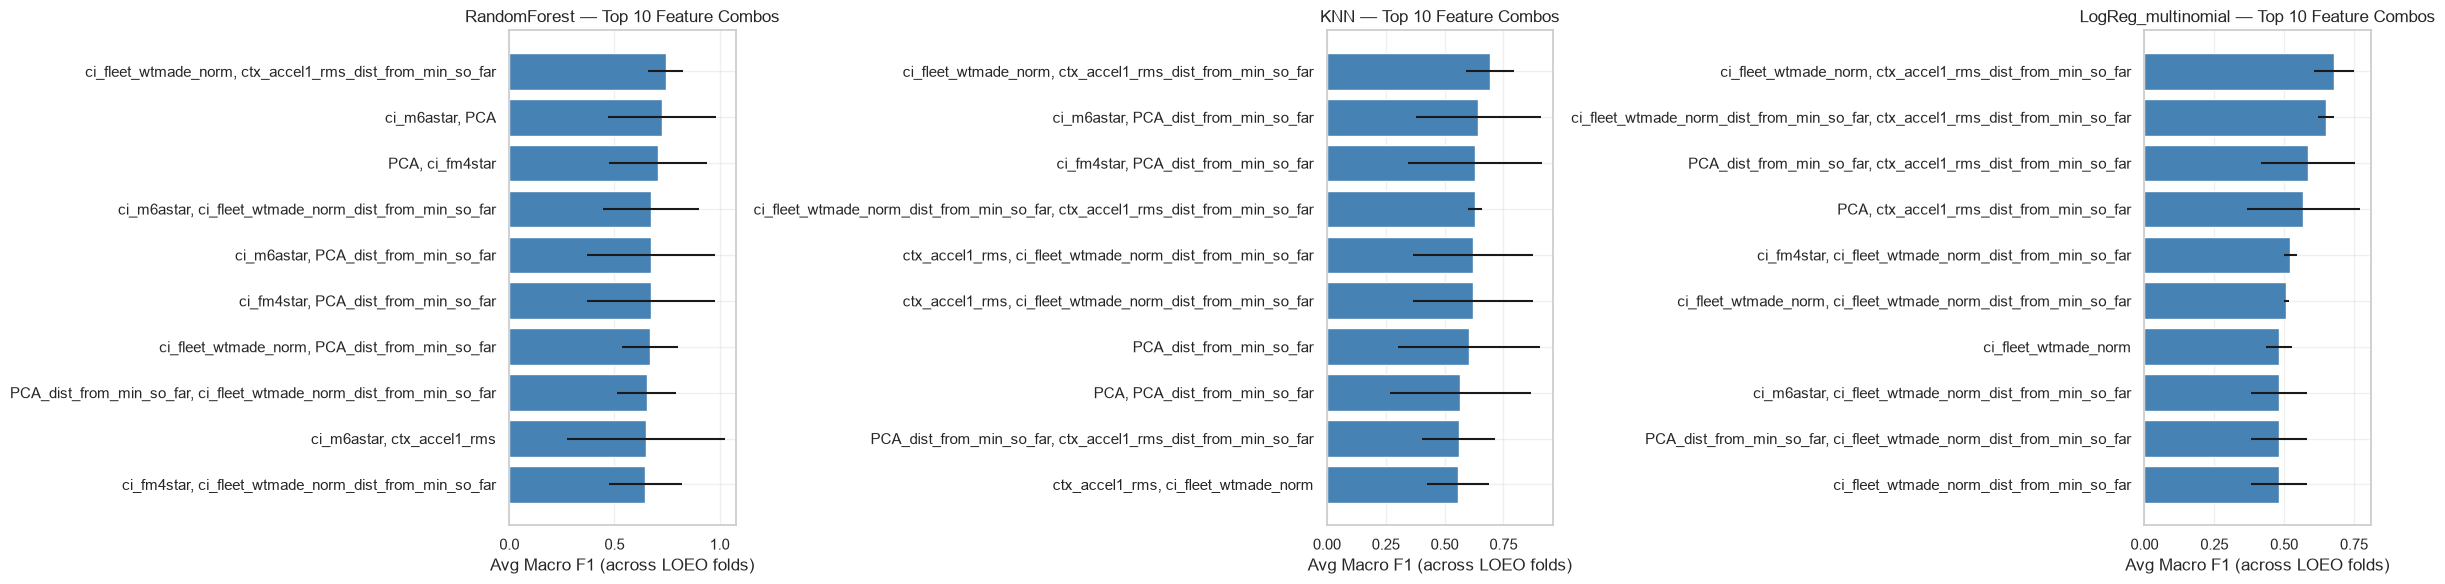


Best overall: ci_fleet_wtmade_norm, ctx_accel1_rms_dist_from_min_so_far with RandomForest (Avg Macro F1 = 0.743)
Train class counts: {1: 10, 2: 11, 3: 4}
Test class counts: {1: 3, 3: 1}

=== LogReg_multinomial ===
Accuracy: 1.0
Confusion matrix (rows=true, cols=pred):
 [[3 0 0]
 [0 0 0]
 [0 0 1]]
              precision    recall  f1-score   support

           1       1.00      1.00      1.00         3
           2       0.00      0.00      0.00         0
           3       1.00      1.00      1.00         1

    accuracy                           1.00         4
   macro avg       0.67      0.67      0.67         4
weighted avg       1.00      1.00      1.00         4


=== RandomForest ===
Accuracy: 1.0
Confusion matrix (rows=true, cols=pred):
 [[3 0 0]
 [0 0 0]
 [0 0 1]]
              precision    recall  f1-score   support

           1       1.00      1.00      1.00         3
           2       0.00      0.00      0.00         0
           3       1.00      1.00      1.00        

,class_1,class_2,class_3
ci_fleet_wtmade_norm,-0.401942,-0.901958,1.303901
ctx_accel1_rms_dist_from_min_so_far,-0.307097,0.743595,-0.436498



--- RandomForest on best feature set ---


,Feature,Importance
0,ci_fleet_wtmade_norm,0.738618
1,ctx_accel1_rms_dist_from_min_so_far,0.261382



--- KNN on best feature set ---


In [157]:
import itertools
import io
import contextlib
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report
import warnings

# Suppress all warnings globally
warnings.filterwarnings('ignore')

def quiet_run_classification_experiment(**kwargs):
    f = io.StringIO()
    with contextlib.redirect_stdout(f):
        results = run_classification_experiment(**kwargs)
    return results


# Define experiments and candidate features

experiments = {
    "EXP_A": EXP_A_df_trans,
    "EXP_B": EXP_B_df_trans,
    "EXP_C": EXP_C_df_trans,
    "EXP_F": EXP_F_df_trans,
}

# List every numeric feature to be tested, individually and combined
candidate_features = [
    'ctx_accel1_rms',
    'ci_m6a',
    'ci_m6astar',
    'PCA',
    'ctx_accel1_rms',
    'ci_fm4star',
    'ci_fleet_wtmade_norm',
    'PCA_dist_from_min_so_far',
    'ci_fleet_wtmade_norm_dist_from_min_so_far',
    'ctx_accel1_rms_dist_from_min_so_far'
]

classes = np.array([1, 2, 3])
max_combo_size = 2


# Generate all combinations to test

all_combos = []
for r in range(1, max_combo_size + 1):
    all_combos.extend(itertools.combinations(candidate_features, r))

print(f"Testing {len(all_combos)} feature combinations × {len(experiments)} LOEO folds "
      f"= {len(all_combos) * len(experiments)} total model fits per classifier...")


# Run LOEO for every feature combination

feature_search_rows = []
start = time.time()

for combo_idx, combo in enumerate(all_combos, start=1):
    combo_list = list(combo)
    fold_metrics = {}  # {model_name: [per-fold metric dicts]}

    for test_name, test_df in experiments.items():
        train_dfs = [df for name, df in experiments.items() if name != test_name]

        try:
            results = quiet_run_classification_experiment(
                train_dfs=train_dfs,
                test_df=test_df,
                feature_cols=combo_list,
                classes=classes,
                make_plots=False,
            )
        except Exception as e:
            print(f"Skipped {combo_list} on {test_name}: {e}")
            continue

        for model_name, res in results.items():
            y_true = res["plot_df"]["y_true"]
            y_pred = res["plot_df"]["y_pred"]
            report = classification_report(
                y_true, y_pred, labels=classes, zero_division=0, output_dict=True
            )
            fold_metrics.setdefault(model_name, []).append({
                "accuracy": res["accuracy"],
                "macro_f1": report["macro avg"]["f1-score"],
                "weighted_f1": report["weighted avg"]["f1-score"],
            })

    for model_name, fold_list in fold_metrics.items():
        fold_df = pd.DataFrame(fold_list)
        feature_search_rows.append({
            "Features": ", ".join(combo_list),
            "N_Features": len(combo_list),
            "Model": model_name,
            "Avg_Accuracy": fold_df["accuracy"].mean(),
            "Avg_Macro_F1": fold_df["macro_f1"].mean(),
            "Avg_Weighted_F1": fold_df["weighted_f1"].mean(),
            "Std_Macro_F1": fold_df["macro_f1"].std(),
        })

    if combo_idx % 5 == 0 or combo_idx == len(all_combos):
        print(f"  Completed {combo_idx}/{len(all_combos)} combos "
              f"({time.time() - start:.1f}s elapsed)")

feature_search_df = pd.DataFrame(feature_search_rows)
feature_search_df = feature_search_df.sort_values(
    "Avg_Macro_F1", ascending=False
).reset_index(drop=True)


# Summary tables

print("\nTOP 10 FEATURE COMBINATIONS (ranked by Avg Macro F1)")
display(feature_search_df.head(10))

print("\nBEST COMBINATION PER MODEL")
best_per_model = feature_search_df.loc[
    feature_search_df.groupby("Model")["Avg_Macro_F1"].idxmax()
]
display(best_per_model)


#  Marginal feature value

feature_impact_rows = []
for feat in candidate_features:
    for model_name in feature_search_df["Model"].unique():
        sub = feature_search_df[feature_search_df["Model"] == model_name]
        with_feat = sub[sub["Features"].str.contains(fr'\b{feat}\b', regex=True)]["Avg_Macro_F1"].mean()
        without_feat = sub[~sub["Features"].str.contains(fr'\b{feat}\b', regex=True)]["Avg_Macro_F1"].mean()
        feature_impact_rows.append({
            "Feature": feat,
            "Model": model_name,
            "Avg_F1_With_Feature": with_feat,
            "Avg_F1_Without_Feature": without_feat,
            "Delta": with_feat - without_feat,
        })

feature_impact_df = pd.DataFrame(feature_impact_rows).sort_values("Delta", ascending=False)
print("\n MARGINAL VALUE OF EACH FEATURE")
display(feature_impact_df)


# Plot: Top N combos per model

top_n = 10
models_list = feature_search_df["Model"].unique()
fig, axes = plt.subplots(1, len(models_list), figsize=(8 * len(models_list), 6))
if len(models_list) == 1:
    axes = [axes]

for ax, model_name in zip(axes, models_list):
    sub = feature_search_df[feature_search_df["Model"] == model_name] \
        .sort_values("Avg_Macro_F1", ascending=False).head(top_n)
    y_pos = np.arange(len(sub))
    ax.barh(y_pos, sub["Avg_Macro_F1"], xerr=sub["Std_Macro_F1"], color="steelblue")
    ax.set_yticks(y_pos)
    ax.set_yticklabels(sub["Features"])
    ax.invert_yaxis()
    ax.set_xlabel("Avg Macro F1 (across LOEO folds)")
    ax.set_title(f"{model_name} — Top {top_n} Feature Combos")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# Inspect the winning combination in detail

best_row = feature_search_df.iloc[0]
best_features = best_row["Features"].split(", ")
print(f"\nBest overall: {best_row['Features']} with {best_row['Model']} "
      f"(Avg Macro F1 = {best_row['Avg_Macro_F1']:.3f})")

# Re-run full LOEO with plots enabled for the winning feature set
final_results = {}
for test_name, test_df in experiments.items():
    train_dfs = [df for name, df in experiments.items() if name != test_name]
    final_results[test_name] = run_classification_experiment(
        train_dfs=train_dfs,
        test_df=test_df,
        feature_cols=best_features,
        classes=classes,
        make_plots=False,
    )

# Feature importance (RandomForest) or coefficients (LogisticRegression)
# using the last fold's fitted pipeline as a representative example
example_fold = list(final_results.values())[0]
for model_name, res in example_fold.items():
    clf = res["pipe"].named_steps["clf"]
    print(f"\n--- {model_name} on best feature set ---")
    if hasattr(clf, "feature_importances_"):
        imp_df = pd.DataFrame({
            "Feature": best_features,
            "Importance": clf.feature_importances_
        }).sort_values("Importance", ascending=False)
        display(imp_df)
    elif hasattr(clf, "coef_"):
        coef_df = pd.DataFrame(
            clf.coef_, columns=best_features, index=[f"class_{c}" for c in classes]
        ).T
        display(coef_df)

# LOEO for Classifiers
Logistic reg and Random Forest


HOLDOUT TEST SET: EXP_A
Train class counts: {1: 10, 2: 11, 3: 4}
Test class counts: {1: 3, 3: 1}

=== LogReg_multinomial ===
Accuracy: 1.0
Confusion matrix (rows=true, cols=pred):
 [[3 0 0]
 [0 0 0]
 [0 0 1]]
              precision    recall  f1-score   support

           1       1.00      1.00      1.00         3
           2       0.00      0.00      0.00         0
           3       1.00      1.00      1.00         1

    accuracy                           1.00         4
   macro avg       0.67      0.67      0.67         4
weighted avg       1.00      1.00      1.00         4


=== RandomForest ===
Accuracy: 0.75
Confusion matrix (rows=true, cols=pred):
 [[3 0 0]
 [0 0 0]
 [0 1 0]]
              precision    recall  f1-score   support

           1       1.00      1.00      1.00         3
           2       0.00      0.00      0.00         0
           3       0.00      0.00      0.00         1

    accuracy                           0.75         4
   macro avg       0.33      0

,Test_Set,Model,Accuracy,Macro_F1,Macro_Precision,Macro_Recall,Weighted_F1
0,EXP_A,KNN,0.500000,0.222222,0.222222,0.222222,0.500000
1,EXP_B,KNN,0.571429,0.657143,0.666667,0.666667,0.559184
2,EXP_C,KNN,0.500000,0.607143,0.800000,0.714286,0.419643
3,EXP_F,KNN,0.666667,0.655556,0.777778,0.722222,0.705556
4,EXP_A,LogReg_multinomial,1.000000,0.666667,0.666667,0.666667,1.000000
5,EXP_B,LogReg_multinomial,0.714286,0.777778,0.777778,0.777778,0.714286
6,EXP_C,LogReg_multinomial,0.500000,0.607143,0.800000,0.714286,0.419643
7,EXP_F,LogReg_multinomial,0.666667,0.666667,0.722222,0.722222,0.666667
8,EXP_A,RandomForest,0.750000,0.333333,0.333333,0.333333,0.750000
9,EXP_B,RandomForest,0.714286,0.777778,0.777778,0.777778,0.714286



AVERAGE ACROSS ALL TEST SETS 


,Model,Accuracy,Macro_F1,Macro_Precision,Macro_Recall,Weighted_F1
0,KNN,0.559524,0.535516,0.616667,0.581349,0.546096
1,LogReg_multinomial,0.720238,0.679563,0.741667,0.720238,0.700149
2,RandomForest,0.636905,0.569444,0.585859,0.625000,0.607738


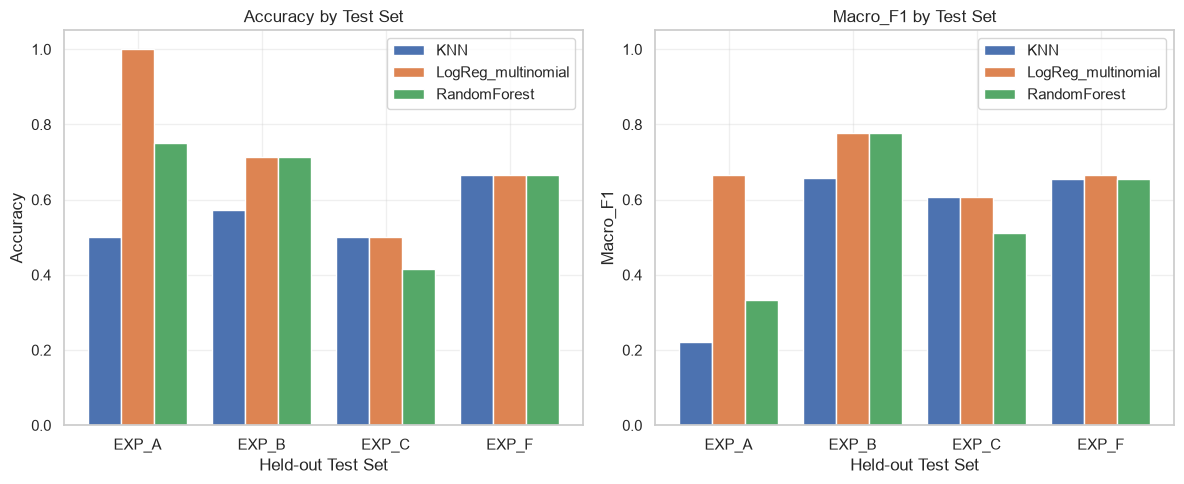

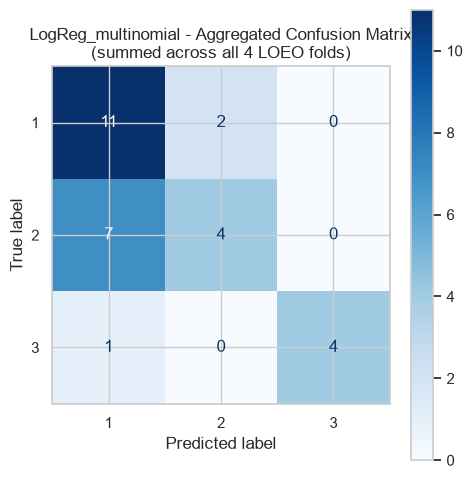

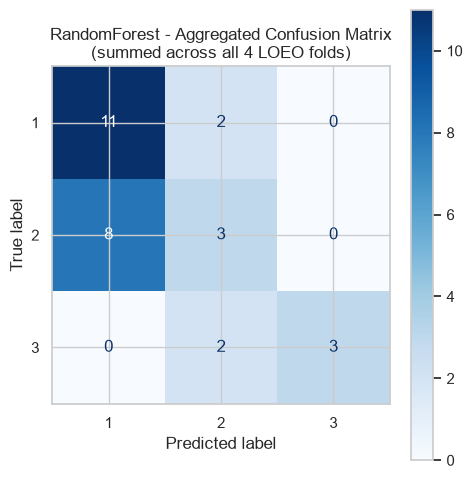

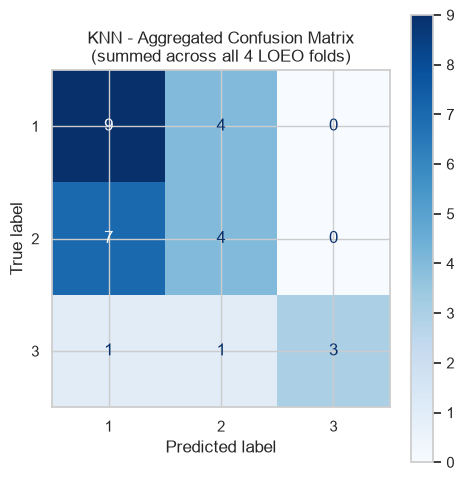

In [142]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, ConfusionMatrixDisplay


#Define your experiments in a dict (name -> dataframe)

experiments = {
    "EXP_A": EXP_A_df_trans,
    "EXP_B": EXP_B_df_trans,
    "EXP_C": EXP_C_df_trans,
    "EXP_F": EXP_F_df_trans,
}

feature_cols = ['ci_fleet_wtmade_norm_dist_from_min_so_far','PCA_dist_from_min_so_far','ctx_accel1_rms_dist_from_min_so_far']
target_col = "gt_condition"
classes = np.array([1, 2, 3])


#Run leave-one-experiment-out loop

all_results = {}          # {test_exp_name: results_dict_from_run_classification_experiment}
summary_rows = []         # flat list of dicts -> summary table
agg_confusion = {}        # {model_name: summed confusion matrix across folds}

for test_name, test_df in experiments.items():
    train_dfs = [df for name, df in experiments.items() if name != test_name]

    print(f"\n{'='*60}")
    print(f"HOLDOUT TEST SET: {test_name}")
    print(f"{'='*60}")

    results = run_classification_experiment(
        train_dfs=train_dfs,
        test_df=test_df,
        feature_cols=feature_cols,
        target_col=target_col,
        classes=classes,
        make_plots=False,  # suppress per-fold plots; aggregated summary below
    )

    all_results[test_name] = results

    for model_name, res in results.items():
        # Pull macro/weighted avg metrics from classification_report
        y_true = res["plot_df"]["y_true"]
        y_pred = res["plot_df"]["y_pred"]
        report = classification_report(
            y_true, y_pred, labels=classes, zero_division=0, output_dict=True
        )

        summary_rows.append({
            "Test_Set": test_name,
            "Model": model_name,
            "Accuracy": res["accuracy"],
            "Macro_F1": report["macro avg"]["f1-score"],
            "Macro_Precision": report["macro avg"]["precision"],
            "Macro_Recall": report["macro avg"]["recall"],
            "Weighted_F1": report["weighted avg"]["f1-score"],
        })

        # Aggregate confusion matrices across folds
        if model_name not in agg_confusion:
            agg_confusion[model_name] = res["confusion_matrix"].copy()
        else:
            agg_confusion[model_name] += res["confusion_matrix"]


#Build summary table

summary_df = pd.DataFrame(summary_rows)
summary_df = summary_df.sort_values(["Model", "Test_Set"]).reset_index(drop=True)

print("\n\nSUMMARY TABLE (per fold)")
display(summary_df)  # use print(summary_df) if not in a notebook

# Average performance per model across all folds
summary_avg = summary_df.groupby("Model")[
    ["Accuracy", "Macro_F1", "Macro_Precision", "Macro_Recall", "Weighted_F1"]
].mean().reset_index()

print("\nAVERAGE ACROSS ALL TEST SETS ")
display(summary_avg)


#Plot - grouped bar charts for Accuracy, Macro_F1

metrics = ["Accuracy", "Macro_F1"]
test_sets = list(experiments.keys())
models = summary_df["Model"].unique()

fig, axes = plt.subplots(1, len(metrics), figsize=(6 * len(metrics), 5))
if len(metrics) == 1:
    axes = [axes]

for ax, metric in zip(axes, metrics):
    pivot = summary_df.pivot(index="Test_Set", columns="Model", values=metric).reindex(test_sets)

    x = np.arange(len(test_sets))
    width = 0.8 / len(models)

    for i, model in enumerate(models):
        ax.bar(x + i * width, pivot[model], width=width, label=model)

    ax.set_xticks(x + width * (len(models) - 1) / 2)
    ax.set_xticklabels(test_sets)
    ax.set_ylim(0, 1.05)
    ax.set_title(f"{metric} by Test Set")
    ax.set_xlabel("Held-out Test Set")
    ax.set_ylabel(metric)
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()


# Aggregated confusion matrix per model
# sum of confusion matrices across all 4 folds

for model_name, cm_sum in agg_confusion.items():
    disp = ConfusionMatrixDisplay(confusion_matrix=cm_sum, display_labels=classes)
    fig, ax = plt.subplots(figsize=(5, 5))
    disp.plot(ax=ax, cmap="Blues", colorbar=True)
    ax.set_title(f"{model_name} - Aggregated Confusion Matrix\n(summed across all 4 LOEO folds)")
    plt.tight_layout()
    plt.show()

## Optimized LOEO

Add hypertuning for models

Feature set used in sweep + final run: ['ci_fleet_wtmade_norm', 'ctx_accel1_rms_dist_from_min_so_far']
Train class counts: {1: 10, 2: 11, 3: 4}
Test class counts: {1: 3, 3: 1}

=== LogReg_multinomial ===
Accuracy: 1.0
Confusion matrix (rows=true, cols=pred):
 [[3 0 0]
 [0 0 0]
 [0 0 1]]
              precision    recall  f1-score   support

           1       1.00      1.00      1.00         3
           2       0.00      0.00      0.00         0
           3       1.00      1.00      1.00         1

    accuracy                           1.00         4
   macro avg       0.67      0.67      0.67         4
weighted avg       1.00      1.00      1.00         4

Pipeline steps: [('preprocess', ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                

,Model,Params,Accuracy_mean,Accuracy_std,Macro_F1_mean,Macro_F1_std
0,KNN,n_neighbors=3,0.7470,0.2074,0.7129,0.0864
1,KNN,n_neighbors=5,0.7262,0.2321,0.6931,0.1022
2,KNN,n_neighbors=7,0.7619,0.2103,0.7232,0.1058
3,LogReg_multinomial,C=0.1,0.6994,0.2392,0.6556,0.1096
4,LogReg_multinomial,C=1.0,0.7202,0.2079,0.6796,0.0712
5,LogReg_multinomial,C=10.0,0.7202,0.2079,0.6796,0.0712
6,RandomForest,"n_estimators=300, max_depth=5",0.7470,0.2074,0.7129,0.0864
7,RandomForest,"n_estimators=300, max_depth=None",0.7470,0.2074,0.7129,0.0864
8,RandomForest,"n_estimators=800, max_depth=5",0.7827,0.1772,0.7431,0.0814
9,RandomForest,"n_estimators=800, max_depth=None",0.7827,0.1772,0.7431,0.0814



LogReg_multinomial: tied candidates at max Macro_F1_mean = 0.6796


,Params,Accuracy_mean,Macro_F1_mean
4,C=1.0,0.7202,0.6796
5,C=10.0,0.7202,0.6796



RandomForest: tied candidates at max Macro_F1_mean = 0.7431


,Params,Accuracy_mean,Macro_F1_mean
8,"n_estimators=800, max_depth=5",0.7827,0.7431
9,"n_estimators=800, max_depth=None",0.7827,0.7431



KNN: tied candidates at max Macro_F1_mean = 0.7232


,Params,Accuracy_mean,Macro_F1_mean
2,n_neighbors=7,0.7619,0.7232



BEST HYPERPARAMETERS PER MODEL (by Macro_F1 mean, non-nested sweep)


,Model,Params,Accuracy_mean,Accuracy_std,Macro_F1_mean,Macro_F1_std
0,KNN,n_neighbors=7,0.7619,0.2103,0.7232,0.1058
1,LogReg_multinomial,C=1.0,0.7202,0.2079,0.6796,0.0712
2,RandomForest,"n_estimators=800, max_depth=None",0.7827,0.1772,0.7431,0.0814


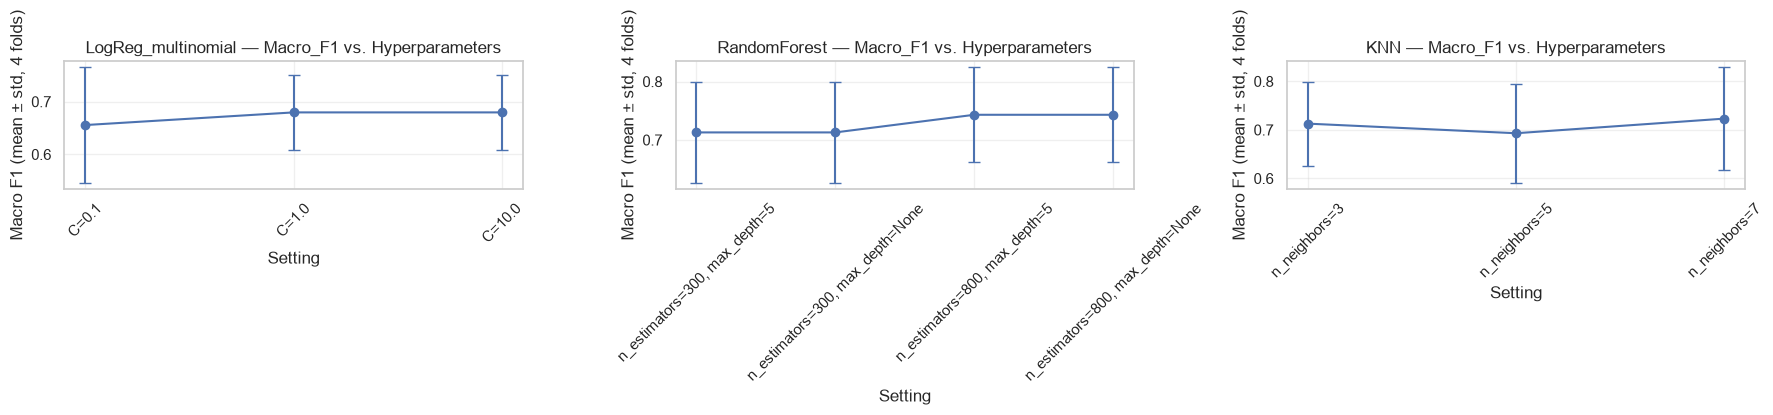


HOLDOUT TEST SET: EXP_A
Train class counts: {1: 10, 2: 11, 3: 4}
Test class counts: {1: 3, 3: 1}

=== KNN ===
Accuracy: 1.0
Confusion matrix (rows=true, cols=pred):
 [[3 0 0]
 [0 0 0]
 [0 0 1]]
              precision    recall  f1-score   support

           1       1.00      1.00      1.00         3
           2       0.00      0.00      0.00         0
           3       1.00      1.00      1.00         1

    accuracy                           1.00         4
   macro avg       0.67      0.67      0.67         4
weighted avg       1.00      1.00      1.00         4


=== LogReg_multinomial ===
Accuracy: 1.0
Confusion matrix (rows=true, cols=pred):
 [[3 0 0]
 [0 0 0]
 [0 0 1]]
              precision    recall  f1-score   support

           1       1.00      1.00      1.00         3
           2       0.00      0.00      0.00         0
           3       1.00      1.00      1.00         1

    accuracy                           1.00         4
   macro avg       0.67      0.67      0

,Test_Set,Model,Accuracy,Macro_F1,Macro_Precision,Macro_Recall,Weighted_F1
0,EXP_A,KNN,1.000000,0.666667,0.666667,0.666667,1.000000
1,EXP_B,KNN,0.714286,0.777778,0.777778,0.777778,0.714286
2,EXP_C,KNN,0.500000,0.607143,0.800000,0.714286,0.419643
3,EXP_F,KNN,0.833333,0.841270,0.916667,0.833333,0.817460
4,EXP_A,LogReg_multinomial,1.000000,0.666667,0.666667,0.666667,1.000000
5,EXP_B,LogReg_multinomial,0.714286,0.777778,0.777778,0.777778,0.714286
6,EXP_C,LogReg_multinomial,0.500000,0.607143,0.800000,0.714286,0.419643
7,EXP_F,LogReg_multinomial,0.666667,0.666667,0.722222,0.722222,0.666667
8,EXP_A,RandomForest,1.000000,0.666667,0.666667,0.666667,1.000000
9,EXP_B,RandomForest,0.714286,0.777778,0.777778,0.777778,0.714286



MEAN ± STD ACROSS ALL 4 TEST SETS (tuned models)


Accuracy         Macro_F1         Macro_Precision          \
                       mean     std     mean     std            mean     std   
Model                                                                          
KNN                  0.7619  0.2103   0.7232  0.1058          0.7903  0.1025   
LogReg_multinomial   0.7202  0.2079   0.6796  0.0712          0.7417  0.0597   
RandomForest         0.7827  0.1772   0.7431  0.0814          0.7940  0.1032   

                   Macro_Recall         Weighted_F1          
                           mean     std        mean     std  
Model                                                        
KNN                      0.7480  0.0728      0.7378  0.2428  
LogReg_multinomial       0.7202  0.0455      0.7001  0.2380  
RandomForest             0.7599  0.0693      0.7699  0.1894

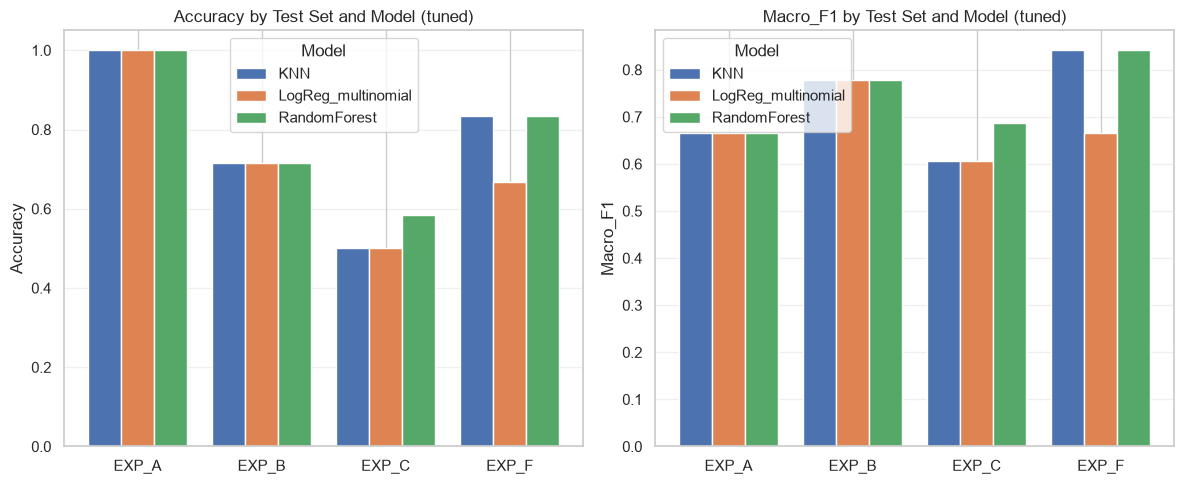

In [147]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from sklearn.model_selection import ParameterGrid
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

experiments = {
    "EXP_A": EXP_A_df_trans,
    "EXP_B": EXP_B_df_trans,
    "EXP_C": EXP_C_df_trans,
    "EXP_F": EXP_F_df_trans,
}

# --- Definitions moved up: must exist before probe/sweep use them ---
feature_cols = ['ci_fleet_wtmade_norm', 'ctx_accel1_rms_dist_from_min_so_far']
target_col = "gt_condition"
classes = np.array([1, 2, 3])

param_grids = {
    "LogReg_multinomial": [{"C": c} for c in [0.1, 1.0, 10.0]],
    "RandomForest": [
        {"n_estimators": n, "max_depth": d}
        for n in [300, 800] for d in [None, 5]
    ],
    "KNN": [{"n_neighbors": k} for k in [3, 5, 7]],
}

def build_model(model_name, params):
    """Builds a single estimator: fixed base settings + swept params."""
    if model_name == "LogReg_multinomial":
        return LogisticRegression(
            solver="lbfgs", max_iter=2000, random_state=0, **params
        )
    elif model_name == "RandomForest":
        return RandomForestClassifier(
            random_state=0, class_weight="balanced", **params
        )
    elif model_name == "KNN":
        return KNeighborsClassifier(weights="distance", **params)
    else:
        raise ValueError(f"Unknown model name: {model_name}")

# --- Probe: confirm feature set, pipeline structure, classes_ ordering, index alignment ---
print("Feature set used in sweep + final run:", feature_cols)

probe = run_classification_experiment(
    train_dfs=[df for name, df in experiments.items() if name != "EXP_A"],
    test_df=experiments["EXP_A"],
    feature_cols=feature_cols,
    target_col=target_col,
    classes=classes,
    models={"LogReg_multinomial": build_model("LogReg_multinomial", {"C": 1.0})},
    make_plots=False,
)
pipe = probe["LogReg_multinomial"]["pipe"]
print("Pipeline steps:", pipe.steps)
print("Fitted classes_:", pipe.classes_)
print("plot_df columns:", probe["LogReg_multinomial"]["plot_df"].columns.tolist())
print("plot_df index sample:", probe["LogReg_multinomial"]["plot_df"].index[:5])
print("test_df index sample:", experiments["EXP_A"].index[:5])
print("Index alignment check:",
      probe["LogReg_multinomial"]["plot_df"].index.equals(experiments["EXP_A"].index))

# --- Hyperparameter sweep loop ---
sweep_rows = []
param_lookup = {}

for model_name, param_list in param_grids.items():
    for params in param_list:
        param_str = ", ".join(f"{k}={v}" for k, v in params.items())
        param_lookup[(model_name, param_str)] = params
        estimator = build_model(model_name, params)

        for test_name, test_df in experiments.items():
            train_dfs = [df for name, df in experiments.items() if name != test_name]

            results = run_classification_experiment(
                train_dfs=train_dfs,
                test_df=test_df,
                feature_cols=feature_cols,
                target_col=target_col,
                classes=classes,
                models={model_name: estimator},
                make_plots=False,
            )

            res = results[model_name]
            y_true = res["plot_df"]["y_true"]
            y_pred = res["plot_df"]["y_pred"]
            report = classification_report(
                y_true, y_pred, labels=classes, zero_division=0, output_dict=True
            )

            sweep_rows.append({
                "Model": model_name,
                "Params": param_str,
                "Test_Set": test_name,
                "Accuracy": res["accuracy"],
                "Macro_F1": report["macro avg"]["f1-score"],
            })

sweep_df = pd.DataFrame(sweep_rows)

# --- Mean/std per model and setting across the 4 LOEO folds ---
sweep_summary = (
    sweep_df.groupby(["Model", "Params"])[["Accuracy", "Macro_F1"]]
    .agg(["mean", "std"])
    .round(4)
)
sweep_summary.columns = ["_".join(c).strip("_") for c in sweep_summary.columns]
sweep_summary = sweep_summary.reset_index()

print("\nHYPERPARAMETER SWEEP SUMMARY (mean ± std across 4 LOEO folds)")
display(sweep_summary)

# --- Tie inspection ---
for model_name in param_grids:
    sub = sweep_summary[sweep_summary["Model"] == model_name]
    max_f1 = sub["Macro_F1_mean"].max()
    ties = sub[sub["Macro_F1_mean"] == max_f1]
    print(f"\n{model_name}: tied candidates at max Macro_F1_mean = {max_f1}")
    display(ties[["Params", "Accuracy_mean", "Macro_F1_mean"]])

# --- Pick best setting per model ---
best_per_model = (
    sweep_summary.sort_values("Macro_F1_mean", ascending=False)
    .groupby("Model")
    .first()
    .reset_index()
)

print("\nBEST HYPERPARAMETERS PER MODEL (by Macro_F1 mean, non-nested sweep)")
display(best_per_model[["Model", "Params", "Accuracy_mean", "Accuracy_std",
                         "Macro_F1_mean", "Macro_F1_std"]])

# --- Rebuild fitted-ready estimators for the "best" setting of each model ---
best_models = {
    row["Model"]: build_model(row["Model"], param_lookup[(row["Model"], row["Params"])])
    for _, row in best_per_model.iterrows()
}

# --- Save sweep-related artifacts NOW that best_per_model exists ---
sweep_df.to_csv("sweep_df_raw.csv", index=False)
sweep_summary.to_csv("sweep_summary.csv", index=False)
best_per_model.to_csv("best_per_model.csv", index=False)

# --- Sensitivity plot across hyperparameter settings ---
fig, axes = plt.subplots(1, len(param_grids), figsize=(6 * len(param_grids), 4))
for ax, model_name in zip(axes, param_grids.keys()):
    sub = sweep_summary[sweep_summary["Model"] == model_name].sort_values("Params")
    ax.errorbar(sub["Params"], sub["Macro_F1_mean"], yerr=sub["Macro_F1_std"],
                marker="o", capsize=4)
    ax.set_title(f"{model_name} — Macro_F1 vs. Hyperparameters")
    ax.set_xlabel("Setting")
    ax.set_ylabel("Macro F1 (mean ± std, 4 folds)")
    ax.tick_params(axis="x", rotation=45)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# --- Final LOEO evaluation using tuned models ---
all_results = {}
summary_rows = []
agg_confusion = {}
misclassified_rows = []   # moved here: filled correctly inside the loop below

for test_name, test_df in experiments.items():
    train_dfs = [df for name, df in experiments.items() if name != test_name]

    print(f"\n{'='*60}")
    print(f"HOLDOUT TEST SET: {test_name}")
    print(f"{'='*60}")

    results = run_classification_experiment(
        train_dfs=train_dfs,
        test_df=test_df,
        feature_cols=feature_cols,
        target_col=target_col,
        classes=classes,
        models=best_models,
        make_plots=False,
    )

    all_results[test_name] = results

    for model_name, res in results.items():
        y_true = res["plot_df"]["y_true"]
        y_pred = res["plot_df"]["y_pred"]
        report = classification_report(
            y_true, y_pred, labels=classes, zero_division=0, output_dict=True
        )

        summary_rows.append({
            "Test_Set": test_name,
            "Model": model_name,
            "Accuracy": res["accuracy"],
            "Macro_F1": report["macro avg"]["f1-score"],
            "Macro_Precision": report["macro avg"]["precision"],
            "Macro_Recall": report["macro avg"]["recall"],
            "Weighted_F1": report["weighted avg"]["f1-score"],
        })

        if model_name not in agg_confusion:
            agg_confusion[model_name] = res["confusion_matrix"].copy()
        else:
            agg_confusion[model_name] += res["confusion_matrix"]

        # --- Misclassified-row extraction: now correctly scoped to THIS fold/model ---
        plot_df = res["plot_df"]
        fold_pipe = res["pipe"]

        probas = fold_pipe.predict_proba(test_df[feature_cols])
        proba_cols = {f"proba_class_{c}": probas[:, j] for j, c in enumerate(fold_pipe.classes_)}

        mis_mask = (y_true.values != y_pred.values)

        for i in np.where(mis_mask)[0]:
            row_id = plot_df.index[i]  # relies on index alignment confirmed in probe step
            row_data = {
                "fold": test_name,
                "model": model_name,
                "row_id": row_id,
                "true_class": y_true.iloc[i],
                "pred_class": y_pred.iloc[i],
            }
            if row_id in test_df.index:
                for c in feature_cols:
                    row_data[f"feat_{c}"] = test_df.loc[row_id, c]
            for k, v in proba_cols.items():
                row_data[k] = v[i]
            misclassified_rows.append(row_data)

misclassified_df = pd.DataFrame(misclassified_rows)

summary_df = pd.DataFrame(summary_rows).sort_values(["Model", "Test_Set"]).reset_index(drop=True)
print("\n\nSUMMARY TABLE (per fold, tuned models)")
display(summary_df)

summary_avg = summary_df.groupby("Model")[
    ["Accuracy", "Macro_F1", "Macro_Precision", "Macro_Recall", "Weighted_F1"]
].agg(["mean", "std"]).round(4)
print("\nMEAN ± STD ACROSS ALL 4 TEST SETS (tuned models)")
display(summary_avg)

# --- Save final-evaluation artifacts ---
summary_df.to_csv("summary_df_per_fold.csv", index=False)
summary_avg.to_csv("summary_avg_mean_std.csv")
misclassified_df.to_csv("misclassified_rows.csv", index=False)

for model_name, cm in agg_confusion.items():
    pd.DataFrame(cm, index=[f"true_{c}" for c in classes],
                 columns=[f"pred_{c}" for c in classes]).to_csv(
        f"agg_confusion_{model_name}.csv")

# --- Bar charts: Accuracy and Macro_F1 by Test_Set, grouped by Model ---
metrics = ["Accuracy", "Macro_F1"]
test_sets = list(experiments.keys())
models_list = summary_df["Model"].unique()

fig, axes = plt.subplots(1, len(metrics), figsize=(6 * len(metrics), 5))
if len(metrics) == 1:
    axes = [axes]
for ax, metric in zip(axes, metrics):
    pivot = summary_df.pivot(index="Test_Set", columns="Model", values=metric).reindex(test_sets)
    x = np.arange(len(test_sets))
    width = 0.8 / len(models_list)
    for i, model in enumerate(models_list):
        ax.bar(x + i * width, pivot[model], width=width, label=model)
    # --- Reconstructed ending (not from your original code — please verify) ---
    ax.set_xticks(x + width * (len(models_list) - 1) / 2)
    ax.set_xticklabels(test_sets, rotation=0)
    ax.set_ylabel(metric)
    ax.set_title(f"{metric} by Test Set and Model (tuned)")
    ax.legend(title="Model")
    ax.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.show()

In [145]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from sklearn.model_selection import ParameterGrid
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier


experiments = {
    "EXP_A": EXP_A_df_trans,
    "EXP_B": EXP_B_df_trans,
    "EXP_C": EXP_C_df_trans,
    "EXP_F": EXP_F_df_trans,
}


# Confirm feature set and pipeline composition
print("Feature set used in sweep + final run:", feature_cols)

# Quick one-off fit to inspect pipeline structure and classes_ ordering
probe = run_classification_experiment(
    train_dfs=[df for name, df in experiments.items() if name != "EXP_A"],
    test_df=experiments["EXP_A"],
    feature_cols=feature_cols,
    target_col=target_col,
    classes=classes,
    models={"LogReg_multinomial": build_model("LogReg_multinomial", {"C": 1.0})},
    make_plots=False,
)
pipe = probe["LogReg_multinomial"]["pipe"]
print("Pipeline steps:", pipe.steps)
print("Fitted classes_:", pipe.classes_)
print("plot_df columns:", probe["LogReg_multinomial"]["plot_df"].columns.tolist())
print("plot_df index sample:", probe["LogReg_multinomial"]["plot_df"].index[:5])
print("test_df index sample:", experiments["EXP_A"].index[:5])
print("Index alignment check:",
      probe["LogReg_multinomial"]["plot_df"].index.equals(experiments["EXP_A"].index))


feature_cols = ['ci_fleet_wtmade_norm', 'ctx_accel1_rms_dist_from_min_so_far']
target_col = "gt_condition"
classes = np.array([1, 2, 3])


# Hyperparameter grids
param_grids = {
    "LogReg_multinomial": [{"C": c} for c in [0.1, 1.0, 10.0]],
    "RandomForest": [
        {"n_estimators": n, "max_depth": d}
        for n in [300, 800] for d in [None, 5]
    ],
    "KNN": [{"n_neighbors": k} for k in [3, 5, 7]],
}


def build_model(model_name, params):
    """Builds a single estimator: fixed base settings + swept params."""
    if model_name == "LogReg_multinomial":
        return LogisticRegression(solver="lbfgs", max_iter=2000,
            random_state=0, **params
        )
    elif model_name == "RandomForest":
        return RandomForestClassifier(
            random_state=0, class_weight="balanced", **params
        )
    elif model_name == "KNN":

        return KNeighborsClassifier(weights="distance", **params)
    else:
        raise ValueError(f"Unknown model name: {model_name}")


# loop using run_classification_experiment
sweep_rows = []
param_lookup = {} 

for model_name, param_list in param_grids.items():
    for params in param_list:
        param_str = ", ".join(f"{k}={v}" for k, v in params.items())
        param_lookup[(model_name, param_str)] = params
        estimator = build_model(model_name, params)

        for test_name, test_df in experiments.items():
            train_dfs = [df for name, df in experiments.items() if name != test_name]

            results = run_classification_experiment(
                train_dfs=train_dfs,
                test_df=test_df,
                feature_cols=feature_cols,
                target_col=target_col,
                classes=classes,
                models={model_name: estimator},  # only this one model/setting
                make_plots=False,
            )

            res = results[model_name]
            y_true = res["plot_df"]["y_true"]
            y_pred = res["plot_df"]["y_pred"]
            report = classification_report(
                y_true, y_pred, labels=classes, zero_division=0, output_dict=True
            )

            sweep_rows.append({
                "Model": model_name,
                "Params": param_str,
                "Test_Set": test_name,
                "Accuracy": res["accuracy"],
                "Macro_F1": report["macro avg"]["f1-score"],
            })

sweep_df = pd.DataFrame(sweep_rows)


misclassified_rows = []

for model_name, res in results.items():
    plot_df = res["plot_df"]
    pipe = res["pipe"]

    y_true = plot_df["y_true"]
    y_pred = plot_df["y_pred"]

    # Get probabilities directly from the fitted pipeline
    probas = pipe.predict_proba(test_df[feature_cols])
    proba_cols = {f"proba_class_{c}": probas[:, j] for j, c in enumerate(pipe.classes_)}

    mis_mask = (y_true.values != y_pred.values)

    for i in np.where(mis_mask)[0]:
        row_id = plot_df.index[i]  # relies on index alignment confirmed in Step 1 above
        row_data = {
            "fold": test_name,
            "model": model_name,
            "row_id": row_id,
            "true_class": y_true.iloc[i],
            "pred_class": y_pred.iloc[i],
        }
        # Pull actual feature values from test_df by matching index
        if row_id in test_df.index:
            for c in feature_cols:
                row_data[f"feat_{c}"] = test_df.loc[row_id, c]
        for k, v in proba_cols.items():
            row_data[k] = v[i]
        misclassified_rows.append(row_data)

misclassified_df = pd.DataFrame(misclassified_rows)


# Mean/std per model,and setting across the 4 LOEO folds
sweep_summary = (
    sweep_df.groupby(["Model", "Params"])[["Accuracy", "Macro_F1"]]
    .agg(["mean", "std"])
    .round(4)
)
sweep_summary.columns = ["_".join(c).strip("_") for c in sweep_summary.columns]
sweep_summary = sweep_summary.reset_index()

print("\nHYPERPARAMETER SWEEP SUMMARY (mean ± std across 4 LOEO folds)")
display(sweep_summary)

sweep_df.to_csv("sweep_df_raw.csv", index=False)
sweep_summary.to_csv("sweep_summary.csv", index=False)
best_per_model.to_csv("best_per_model.csv", index=False)


for model_name in param_grids:
    sub = sweep_summary[sweep_summary["Model"] == model_name]
    max_f1 = sub["Macro_F1_mean"].max()
    ties = sub[sub["Macro_F1_mean"] == max_f1]
    print(f"\n{model_name}: tied candidates at max Macro_F1_mean = {max_f1}")
    display(ties[["Params", "Accuracy_mean", "Macro_F1_mean"]])

# Pick best setting per model

best_per_model = (
    sweep_summary.sort_values("Macro_F1_mean", ascending=False)
    .groupby("Model")
    .first()
    .reset_index()
)

print("\nBEST HYPERPARAMETERS PER MODEL (by Macro_F1 mean, non-nested sweep)")
display(best_per_model[["Model", "Params", "Accuracy_mean", "Accuracy_std",
                         "Macro_F1_mean", "Macro_F1_std"]])

# Rebuild fitted-ready estimators for the "best" setting of each model
best_models = {
    row["Model"]: build_model(row["Model"], param_lookup[(row["Model"], row["Params"])])
    for _, row in best_per_model.iterrows()
}


# Sensitivity plot across hyperparameter settings
fig, axes = plt.subplots(1, len(param_grids), figsize=(6 * len(param_grids), 4))
for ax, model_name in zip(axes, param_grids.keys()):
    sub = sweep_summary[sweep_summary["Model"] == model_name].sort_values("Params")
    ax.errorbar(sub["Params"], sub["Macro_F1_mean"], yerr=sub["Macro_F1_std"],
                marker="o", capsize=4)
    ax.set_title(f"{model_name} — Macro_F1 vs. Hyperparameters")
    ax.set_xlabel("Setting")
    ax.set_ylabel("Macro F1 (mean ± std, 4 folds)")
    ax.tick_params(axis="x", rotation=45)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# Final LOEO evaluation using tuned models
all_results = {}
summary_rows = []
agg_confusion = {}




for test_name, test_df in experiments.items():
    train_dfs = [df for name, df in experiments.items() if name != test_name]

    print(f"\n{'='*60}")
    print(f"HOLDOUT TEST SET: {test_name}")
    print(f"{'='*60}")

    results = run_classification_experiment(
        train_dfs=train_dfs,
        test_df=test_df,
        feature_cols=feature_cols,
        target_col=target_col,
        classes=classes,
        models=best_models,     
        make_plots=False,
    )

    all_results[test_name] = results

    for model_name, res in results.items():
        y_true = res["plot_df"]["y_true"]
        y_pred = res["plot_df"]["y_pred"]
        report = classification_report(
            y_true, y_pred, labels=classes, zero_division=0, output_dict=True
        )

        summary_rows.append({
            "Test_Set": test_name,
            "Model": model_name,
            "Accuracy": res["accuracy"],
            "Macro_F1": report["macro avg"]["f1-score"],
            "Macro_Precision": report["macro avg"]["precision"],
            "Macro_Recall": report["macro avg"]["recall"],
            "Weighted_F1": report["weighted avg"]["f1-score"],
        })

        if model_name not in agg_confusion:
            agg_confusion[model_name] = res["confusion_matrix"].copy()
        else:
            agg_confusion[model_name] += res["confusion_matrix"]

summary_df = pd.DataFrame(summary_rows).sort_values(["Model", "Test_Set"]).reset_index(drop=True)
print("\n\nSUMMARY TABLE (per fold, tuned models)")
display(summary_df)

summary_avg = summary_df.groupby("Model")[
    ["Accuracy", "Macro_F1", "Macro_Precision", "Macro_Recall", "Weighted_F1"]
].agg(["mean", "std"]).round(4)
print("\nMEAN ± STD ACROSS ALL 4 TEST SETS (tuned models)")
display(summary_avg)

# Bar charts and aggregated confusion matrices
metrics = ["Accuracy", "Macro_F1"]
test_sets = list(experiments.keys())
models_list = summary_df["Model"].unique()


summary_df.to_csv("summary_df_per_fold.csv", index=False)
summary_avg.to_csv("summary_avg_mean_std.csv")

for model_name, cm in agg_confusion.items():
    pd.DataFrame(cm, index=[f"true_{c}" for c in classes],
                 columns=[f"pred_{c}" for c in classes]).to_csv(
        f"agg_confusion_{model_name}.csv")

fig, axes = plt.subplots(1, len(metrics), figsize=(6 * len(metrics), 5))
if len(metrics) == 1:
    axes = [axes]
for ax, metric in zip(axes, metrics):
    pivot = summary_df.pivot(index="Test_Set", columns="Model", values=metric).reindex(test_sets)
    x = np.arange(len(test_sets))
    width = 0.8 / len(models_list)
    for i, model in enumerate(models_list):
        ax.bar(x + i * width, pivot[model], width=width, label=model)
    ax.set_xticks(x + width * (len(models_list) - 1) / 2)
    ax.set_xticklabels(test_sets)
    ax.set_ylim(0, 1.05)
    ax.set_title(f"{metric} by Test Set (tuned models)")
    ax.set_xlabel("Held-out Test Set")
    ax.set_ylabel(metric)
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

for model_name, cm_sum in agg_confusion.items():
    disp = ConfusionMatrixDisplay(confusion_matrix=cm_sum, display_labels=classes)
    fig, ax = plt.subplots(figsize=(5, 5))
    disp.plot(ax=ax, cmap="Blues", colorbar=True)
    ax.set_title(f"{model_name} - Aggregated Confusion Matrix (tuned)\n(summed across 4 LOEO folds)")
    plt.tight_layout()
    plt.show()

Feature set used in sweep + final run: ['ci_fleet_wtmade_norm_dist_from_min_so_far', 'PCA_dist_from_min_so_far', 'ctx_accel1_rms_dist_from_min_so_far']


NameError: name 'build_model' is not defined

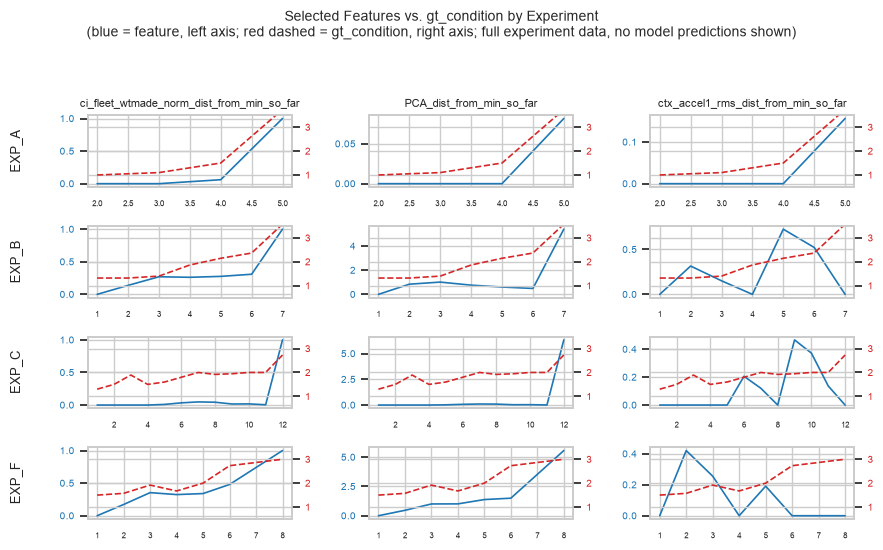

In [122]:
import matplotlib.pyplot as plt

# --- Configuration ---

experiments = {
    "EXP_A": EXP_A_df_trans,
    "EXP_B": EXP_B_df_trans,
    "EXP_C": EXP_C_df_trans,
    "EXP_F": EXP_F_df_trans,
}

features = [
    "ci_fleet_wtmade_norm_dist_from_min_so_far",
    "PCA_dist_from_min_so_far",
    "ctx_accel1_rms_dist_from_min_so_far",
]

target_col = "gt_condition"

x_col = 'run_num'

# --- Plot ---

n_rows = len(experiments)
n_cols = len(features)

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(3 * n_cols, 1.4 * n_rows),
    squeeze=False,
)

for row_idx, (exp_name, df) in enumerate(experiments.items()):

    # sort by ordering column if available; otherwise sort by index
    plot_df = df.sort_values(x_col) if x_col is not None else df.sort_index()
    x_vals = plot_df[x_col] if x_col is not None else plot_df.index

    for col_idx, feat in enumerate(features):
        ax = axes[row_idx][col_idx]
        ax2 = ax.twinx()

        # feature on primary (left) axis
        ax.plot(x_vals, plot_df[feat], color="tab:blue",
                 linewidth=1.2)
        ax.tick_params(axis="y", labelcolor="tab:blue", labelsize=7)
        ax.tick_params(axis="x", labelsize=6)

        # GT label on secondary (right) axis
        ax2.plot(x_vals, plot_df[target_col], color="tab:red",
                  linewidth=1.2, linestyle="--")
        ax2.tick_params(axis="y", labelcolor="tab:red", labelsize=7)
        ax2.set_ylim(0.5, 3.5)  # fixed to the 1-3 class range, with margin

        # column titles on top row only
        if row_idx == 0:
            ax.set_title(feat, fontsize=8)

        # row labels on leftmost column only
        if col_idx == 0:
            ax.annotate(
                exp_name,
                xy=(-0.35, 0.5), xycoords="axes fraction",
                fontsize=9, rotation=90, va="center", ha="center",
            )

fig.suptitle(
    "Selected Features vs. gt_condition by Experiment\n"
    "(blue = feature, left axis; red dashed = gt_condition, right axis; "
    "full experiment data, no model predictions shown)",
    fontsize=10,
)
fig.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

# Test regressors

In [128]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, ElasticNet
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
)


# Float gt_condition -> class mapping (module-level, reusable)
def map_gt_condition_to_class(x):
    """Bins continuous gt_condition values into classes {1, 2, 3}."""
    x = np.asarray(x, dtype=float)
    cls = np.full(x.shape, np.nan, dtype=float)
    cls[(x >= 1) & (x <= 1.5)] = 1
    cls[(x > 1.5) & (x <= 2.5)] = 2
    cls[x >= 2.5] = 3
    return cls


def run_regression_experiment(
    train_dfs,
    test_df,
    feature_cols=None,
    target_col="gt_condition",
    regressors=None,
    make_plots=True,
    add_predicted_class=False,
    class_labels=(1, 2, 3),
):
    """
    Trains & evaluates regressor(s) on concatenated training dataframes,
    tests on a held-out experiment dataframe, prints metrics, and plots
    true vs. predicted scatter. Optionally also bins predictions into
    classes and plots a confusion matrix.
    """

    # Defaults
    if feature_cols is None:
        feature_cols = ['ci_fleet_wtmade_norm_dist_from_min_so_far','PCA_dist_from_min_so_far','ctx_accel1_rms_dist_from_min_so_far']

    if regressors is None:
        regressors = {
            "Ridge": Ridge(alpha=1.0, random_state=0),
            "ElasticNet": ElasticNet(alpha=0.1, l1_ratio=0.5, random_state=0),
            "RandomForest": RandomForestRegressor(
                n_estimators=500, random_state=0, min_samples_leaf=2
            )
        }

    # Allow a single df to be passed instead of a list
    if isinstance(train_dfs, pd.DataFrame):
        train_dfs = [train_dfs]

    # Build train/test sets
    train_df = pd.concat(train_dfs, ignore_index=True)
    test_df = test_df.copy()

    X_train = train_df[feature_cols]
    y_train = train_df[target_col].astype(float)

    X_test = test_df[feature_cols]
    y_test = test_df[target_col].astype(float)

    # Preprocessing pipeline (impute + scale)
    numeric_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    preprocess = ColumnTransformer(
        transformers=[("num", numeric_transformer, feature_cols)],
        remainder="drop"
    )

    # Train and evaluate each model
    results = {}

    for name, reg in regressors.items():
        pipe = Pipeline(steps=[
            ("preprocess", preprocess),
            ("reg", reg)
        ])
        pipe.fit(X_train, y_train)

        y_pred = pipe.predict(X_test)

        mae = mean_absolute_error(y_test, y_pred)
        rmse = np.sqrt(mean_squared_error(y_test, y_pred))
        r2 = r2_score(y_test, y_pred)

        print(f"\n=== {name} ===")
        print(f"MAE:  {mae:.4f}")
        print(f"RMSE: {rmse:.4f}")
        print(f"R²:   {r2:.4f}")

        # build a prediction dataframe with binned class
        pred_df = test_df.copy()
        pred_df["gt_condition_pred"] = y_pred

        result_entry = {
            "pipe": pipe,
            "y_pred": y_pred,
            "mae": mae,
            "rmse": rmse,
            "r2": r2,
            "pred_df": pred_df
        }

        if add_predicted_class:
            pred_df["gt_condition_class_pred"] = map_gt_condition_to_class(y_pred)
            pred_df["gt_condition_class_true"] = map_gt_condition_to_class(y_test.values)

            # confusion matrix (drop rows with NaN classes)
            valid = pred_df[["gt_condition_class_true", "gt_condition_class_pred"]].dropna()
            cm = confusion_matrix(
                valid["gt_condition_class_true"],
                valid["gt_condition_class_pred"],
                labels=class_labels,
            )
            print(f"Confusion matrix (binned classes, rows=true, cols=pred):\n{cm}")

            result_entry["confusion_matrix"] = cm

            # Plot confusion matrix
            if make_plots:
                disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_labels)
                fig, ax = plt.subplots(figsize=(5, 5))
                disp.plot(ax=ax, cmap="Blues", colorbar=True)
                ax.set_title(f"{name} - Confusion Matrix (binned classes)")
                plt.tight_layout()
                plt.show()

        results[name] = result_entry

    # Plotting: true vs predicted scatter
    if make_plots:
        plt.figure(figsize=(6, 6))
        for name, out in results.items():
            plt.scatter(y_test, out["y_pred"], alpha=0.7, label=name)

        minv = min(y_test.min(), *(o["y_pred"].min() for o in results.values()))
        maxv = max(y_test.max(), *(o["y_pred"].max() for o in results.values()))
        plt.plot([minv, maxv], [minv, maxv], "k--", linewidth=1)

        plt.xlabel(f"True {target_col}")
        plt.ylabel(f"Predicted {target_col}")
        plt.title("Regression: True vs Predicted")
        plt.legend()
        plt.grid(alpha=0.3)
        plt.show()

    return results

results = run_regression_experiment(
train_dfs=[EXP_C_df_trans, EXP_F_df_trans, EXP_B_df_trans],
test_df=EXP_A_df_trans,
feature_cols=['ci_fleet_wtmade_norm_dist_from_min_so_far','PCA_dist_from_min_so_far','ctx_accel1_rms_dist_from_min_so_far'],
target_col="gt_condition",
add_predicted_class=True,
make_plots=False
)

best_pipe = results["Ridge"]["pipe"]


=== Ridge ===
MAE:  0.5435
RMSE: 0.6119
R²:   0.6988
Confusion matrix (binned classes, rows=true, cols=pred):
[[0 3 0]
 [0 0 0]
 [0 0 1]]

=== ElasticNet ===
MAE:  0.6073
RMSE: 0.6625
R²:   0.6468
Confusion matrix (binned classes, rows=true, cols=pred):
[[0 3 0]
 [0 0 0]
 [0 0 1]]

=== RandomForest ===
MAE:  0.5917
RMSE: 0.7189
R²:   0.5842
Confusion matrix (binned classes, rows=true, cols=pred):
[[0 3 0]
 [0 0 0]
 [0 1 0]]


Test on all Experiment combinations.  Using Leave one out validation.  


HOLDOUT TEST SET: EXP_A

=== Ridge ===
MAE:  0.5435
RMSE: 0.6119
R²:   0.6988
Confusion matrix (binned classes, rows=true, cols=pred):
[[0 3 0]
 [0 0 0]
 [0 0 1]]

=== ElasticNet ===
MAE:  0.6073
RMSE: 0.6625
R²:   0.6468
Confusion matrix (binned classes, rows=true, cols=pred):
[[0 3 0]
 [0 0 0]
 [0 0 1]]

=== RandomForest ===
MAE:  0.5797
RMSE: 0.7071
R²:   0.5977
Confusion matrix (binned classes, rows=true, cols=pred):
[[0 3 0]
 [0 0 0]
 [0 1 0]]

HOLDOUT TEST SET: EXP_B

=== Ridge ===
MAE:  0.3429
RMSE: 0.4233
R²:   0.6812
Confusion matrix (binned classes, rows=true, cols=pred):
[[0 3 0]
 [0 3 0]
 [0 0 1]]

=== ElasticNet ===
MAE:  0.3389
RMSE: 0.4116
R²:   0.6986
Confusion matrix (binned classes, rows=true, cols=pred):
[[0 3 0]
 [0 3 0]
 [0 0 1]]

=== RandomForest ===
MAE:  0.3871
RMSE: 0.4365
R²:   0.6611
Confusion matrix (binned classes, rows=true, cols=pred):
[[1 2 0]
 [0 3 0]
 [0 0 1]]

HOLDOUT TEST SET: EXP_C

=== Ridge ===
MAE:  0.4745
RMSE: 0.5109
R²:   -1.1309
Confusion ma

,Test_Set,Model,MAE,RMSE,R2
0,EXP_A,ElasticNet,0.607268,0.662519,0.646812
1,EXP_B,ElasticNet,0.338893,0.411578,0.698629
2,EXP_C,ElasticNet,0.433531,0.479930,-0.880104
3,EXP_F,ElasticNet,0.243422,0.283602,0.726219
4,EXP_A,RandomForest,0.579655,0.707089,0.597693
5,EXP_B,RandomForest,0.387109,0.436462,0.661085
6,EXP_C,RandomForest,0.452794,0.496772,-1.014379
7,EXP_F,RandomForest,0.264519,0.330845,0.627407
8,EXP_A,Ridge,0.543527,0.611852,0.698767
9,EXP_B,Ridge,0.342945,0.423323,0.681183



--AVERAGE ACROSS ALL TEST SETS


,Model,MAE_avg,RMSE_avg,R2_avg
0,ElasticNet,0.405779,0.459407,0.297889
1,RandomForest,0.421019,0.492792,0.217951
2,Ridge,0.402392,0.460582,0.237598


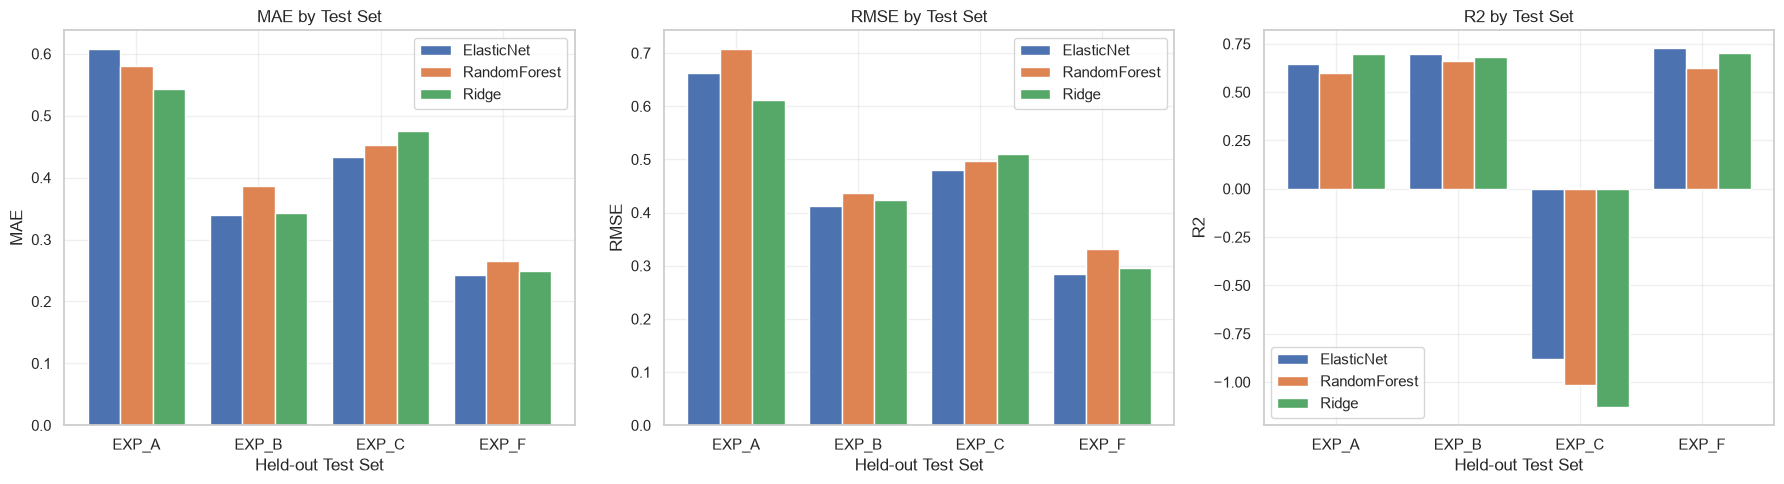

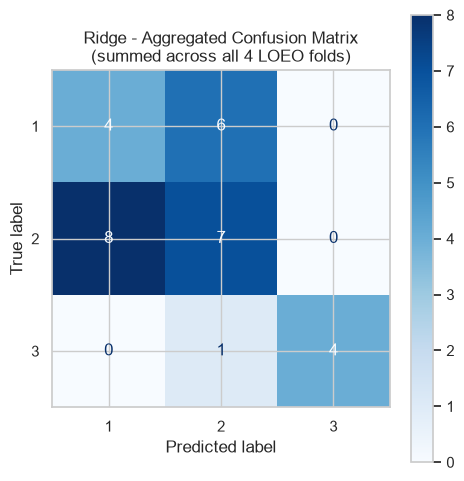

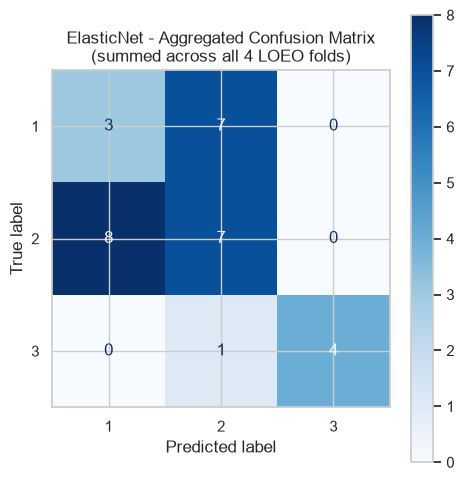

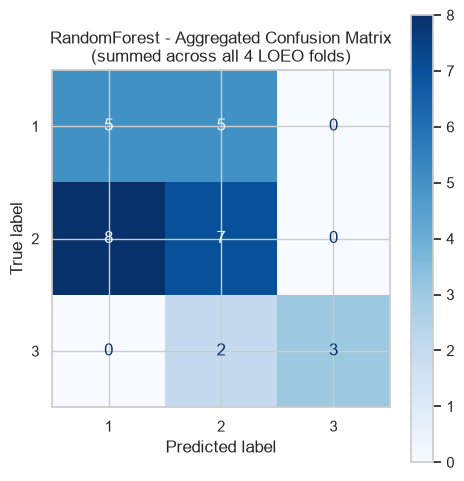

In [131]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


# Define experiments

experiments = {
    "EXP_A": EXP_A_df_trans,
    "EXP_B": EXP_B_df_trans,
    "EXP_C": EXP_C_df_trans,
    "EXP_F": EXP_F_df_trans,
}

feature_cols = ['ci_fleet_wtmade_norm_dist_from_min_so_far','PCA_dist_from_min_so_far','ctx_accel1_rms_dist_from_min_so_far']
target_col = "gt_condition"


# Run leave one experiment out loop

all_results = {}
summary_rows = []
agg_confusion = {}

for test_name, test_df in experiments.items():
    train_dfs = [df for name, df in experiments.items() if name != test_name]

    print(f"\n{'='*60}")
    print(f"HOLDOUT TEST SET: {test_name}")
    print(f"{'='*60}")

    results = run_regression_experiment(
        train_dfs=train_dfs,
        test_df=test_df,
        feature_cols=feature_cols,
        target_col=target_col,
        add_predicted_class=True,
        make_plots=False,  # suppress per-fold plots to avoid clutter; summarized below
    )

    all_results[test_name] = results

    for model_name, res in results.items():
        summary_rows.append({
            "Test_Set": test_name,
            "Model": model_name,
            "MAE": res["mae"],
            "RMSE": res["rmse"],
            "R2": res["r2"],
        })

        # Aggregate confusion matrices across folds (same class_labels order assumed)
        if "confusion_matrix" in res:
            if model_name not in agg_confusion:
                agg_confusion[model_name] = res["confusion_matrix"].copy()
            else:
                agg_confusion[model_name] += res["confusion_matrix"]


#Build summary table

summary_df = pd.DataFrame(summary_rows)
summary_df = summary_df.sort_values(["Model", "Test_Set"]).reset_index(drop=True)

print("\n\nSUMMARY TABLE (per fold)")
display(summary_df)  # use print(summary_df) if not in a notebook

# Average performance per model across all folds
summary_avg = summary_df.groupby("Model")[["MAE", "RMSE", "R2"]].mean().reset_index()
summary_avg = summary_avg.rename(columns={"MAE": "MAE_avg", "RMSE": "RMSE_avg", "R2": "R2_avg"})

print("\n--AVERAGE ACROSS ALL TEST SETS")
display(summary_avg)


#Plot: grouped bar charts for MAE, RMSE, R2

metrics = ["MAE", "RMSE", "R2"]
test_sets = list(experiments.keys())
models = summary_df["Model"].unique()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, metric in zip(axes, metrics):
    pivot = summary_df.pivot(index="Test_Set", columns="Model", values=metric).reindex(test_sets)

    x = np.arange(len(test_sets))
    width = 0.8 / len(models)

    for i, model in enumerate(models):
        ax.bar(x + i * width, pivot[model], width=width, label=model)

    ax.set_xticks(x + width * (len(models) - 1) / 2)
    ax.set_xticklabels(test_sets)
    ax.set_title(f"{metric} by Test Set")
    ax.set_xlabel("Held-out Test Set")
    ax.set_ylabel(metric)
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()


#Optional: plot aggregated confusion matrix per model
#    (sum of confusion matrices across all 4 folds)

from sklearn.metrics import ConfusionMatrixDisplay

class_labels = (1, 2, 3)

for model_name, cm_sum in agg_confusion.items():
    disp = ConfusionMatrixDisplay(confusion_matrix=cm_sum, display_labels=class_labels)
    fig, ax = plt.subplots(figsize=(5, 5))
    disp.plot(ax=ax, cmap="Blues", colorbar=True)
    ax.set_title(f"{model_name} - Aggregated Confusion Matrix\n(summed across all 4 LOEO folds)")
    plt.tight_layout()
    plt.show()

## Plot 1 feature against Ground truth condition label.

Can choose which experiment you want and which feature you want to see.  This allows visualizing what's going on through the run for each feature.

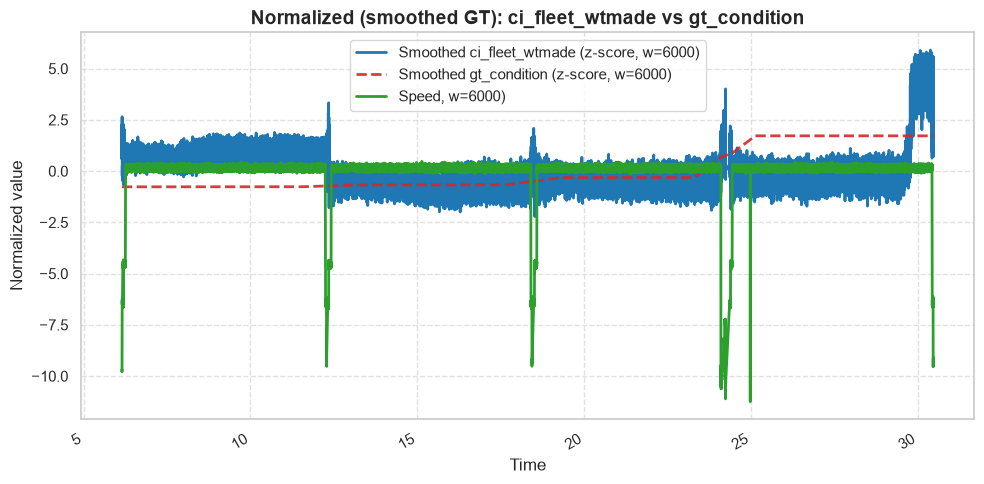

In [134]:
import numpy as np

def plot_feature_and_gt_normalized_smoothed_GT(
    df, feature,
    roll_window=6000,
    time_col="test_hours",
    gt_col="gt_condition",
    normalize="zscore"
):
    import matplotlib.pyplot as plt

    df = df.copy()
    df = df.sort_values(time_col)

    # Rolling mean across full timeline (B)
    df["smoothed_feature"] = (
        df[feature]
        .rolling(window=roll_window, center=True, min_periods=1)
        .mean()
    )

    # Smooth GT as well (so it won't look stepped)
    df["smoothed_gt"] = (
        df[gt_col]
        .rolling(window=roll_window, center=True, min_periods=1)
        .mean()
    )

    x = df[feature].astype(float)
    y = df["smoothed_gt"].astype(float)
    z = df['ctx_pau_torque'].astype(float)

    if normalize == "zscore":
        x_mean, x_std = np.nanmean(x), np.nanstd(x)
        y_mean, y_std = np.nanmean(y), np.nanstd(y)
        z_mean, z_std = np.nanmean(z), np.nanstd(z)

        df["x_norm"] = (x - x_mean) / (x_std if x_std != 0 else 1.0)
        df["y_norm"] = (y - y_mean) / (y_std if y_std != 0 else 1.0)
        df["z_norm"] = (z - z_mean) / (z_std if z_std != 0 else 1.0)
        norm_label = "z-score"

    elif normalize == "minmax":
        x_min, x_max = np.nanmin(x), np.nanmax(x)
        y_min, y_max = np.nanmin(y), np.nanmax(y)
        z_min, z_max = np.nanmin(z), np.nanmax(z)

        df["x_norm"] = (x - x_min) / (x_max - x_min if x_max != x_min else 1.0)
        df["y_norm"] = (y - y_min) / (y_max - y_min if y_max != y_min else 1.0)
        df["z_norm"] = (z - z_min) / (z_max - z_min if z_max != z_min else 1.0)
        norm_label = "min-max"

    else:
        raise ValueError("normalize must be 'zscore' or 'minmax'.")

    fig, ax = plt.subplots(figsize=(10, 5))

    ax.plot(
        df[time_col], df["x_norm"],
        color="tab:blue", linewidth=2,
        label=f"Smoothed {feature} ({norm_label}, w={roll_window})"
    )

    ax.plot(
        df[time_col], df["y_norm"],
        color="tab:red", linewidth=2,
        linestyle="--", alpha=0.9,
        label=f"Smoothed {gt_col} ({norm_label}, w={roll_window})"
    )

    ax.plot(
        df[time_col], df['z_norm'],
        color="tab:green", linewidth=2,
        label=f"Speed, w={roll_window})"
    )

    ax.set_title(f"Normalized (smoothed GT): {feature} vs {gt_col}", fontsize=14, fontweight="bold")
    ax.set_xlabel("Time")
    ax.set_ylabel("Normalized value")

    ax.grid(True, linestyle="--", alpha=0.6)
    ax.legend()
    fig.autofmt_xdate()
    plt.tight_layout()
    plot = plt.show()
    return plot

#Change feature to be plotted here
plot_feature_and_gt_normalized_smoothed_GT(EXP_A_df, feature="ci_fleet_wtmade", roll_window=6000, normalize="zscore")

# Preprocessing steps - Trying a few changes:
Add a binary target

In [137]:
import numpy as np
import pandas as pd

def add_binary_target_and_features(df, ci_signal_cols=['ci_fleet_wtmade_norm','PCA'], baseline_n_runs=2):
    """
    Adds:
      - gt_binary: 0 = normal (levels 1,2), 1 = abnormal (level 3)


    """
    df = df.copy()

    # Binary target
    df['gt_binary'] = (df['gt_condition'] > 2.75).astype(int)


    return df

# Apply to each experiment
EXP_A_df_trans = add_binary_target_and_features(EXP_A_df_trans)
EXP_B_df_trans = add_binary_target_and_features(EXP_B_df_trans)
EXP_C_df_trans = add_binary_target_and_features(EXP_C_df_trans)
EXP_F_df_trans = add_binary_target_and_features(EXP_F_df_trans)

# Threshold Baseline Classifier

In [142]:
class ThresholdBaselineClassifier:
    """
    Simple, interpretable baseline: fits threshold using only normal (y=0)
    training samples on a single feature, flags abnormal if feature exceeds threshold.
    """
    def __init__(self, feature, n_std=3):
        self.feature = feature
        self.n_std = n_std
        self.threshold_ = None
        self.mu_ = None
        self.sigma_ = None

    def fit(self, X, y):
        normal_vals = X.loc[y == 0, self.feature]
        self.mu_ = normal_vals.mean()
        self.sigma_ = normal_vals.std() if normal_vals.std() > 0 else 1e-6
        self.threshold_ = self.mu_ + self.n_std * self.sigma_
        return self

    def predict(self, X):
        return (X[self.feature] > self.threshold_).astype(int).values

    def predict_proba(self, X):
        # Pseudo-probability via sigmoid of standardized distance from threshold
        z = (X[self.feature] - self.threshold_) / self.sigma_
        proba_abnormal = 1 / (1 + np.exp(-z))
        return proba_abnormal.values

In [145]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix
)

experiments = {
    'EXP_A': EXP_A_df_trans,
    'EXP_B': EXP_B_df_trans,
    'EXP_C': EXP_C_df_trans,
    'EXP_F': EXP_F_df_trans,
}

# Features for RF (richer feature set)
rf_feature_cols = [
    'ci_fleet_wtmade_norm_dist_from_min_so_far'
]

# Feature for simple threshold baseline (single, most robust feature)
threshold_feature = 'ci_fleet_wtmade_norm_dist_from_min_so_far'

results = []
confusion_rf_sum = np.zeros((2, 2), dtype=int)
confusion_tb_sum = np.zeros((2, 2), dtype=int)

for test_name, test_df in experiments.items():
    train_dfs = [df for name, df in experiments.items() if name != test_name]
    train_combined = pd.concat(train_dfs, ignore_index=True)

    X_train, y_train = train_combined[rf_feature_cols], train_combined['gt_binary']
    X_test, y_test = test_df[rf_feature_cols], test_df['gt_binary']

    # Random Forest (binary, balanced)
    rf = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42)
    rf.fit(X_train, y_train)
    y_pred_rf = rf.predict(X_test)
    y_proba_rf = rf.predict_proba(X_test)[:, 1]

    # Threshold Baseline (single feature)
    tb = ThresholdBaselineClassifier(feature=threshold_feature, n_std=3)
    tb.fit(train_combined[[threshold_feature]], y_train)
    y_pred_tb = tb.predict(test_df[[threshold_feature]])
    y_proba_tb = tb.predict_proba(test_df[[threshold_feature]])


    def safe_auc(y_true, y_proba):
        try:
            return roc_auc_score(y_true, y_proba)
        except ValueError:
            return np.nan  # only one class present in fold

    for model_name, y_pred, y_proba in [
        ('RandomForest', y_pred_rf, y_proba_rf),
        ('ThresholdBaseline', y_pred_tb, y_proba_tb),
    ]:
        results.append({
            'test_set': test_name,
            'model': model_name,
            'accuracy': accuracy_score(y_test, y_pred),
            'precision_abnormal': precision_score(y_test, y_pred, pos_label=1, zero_division=0),
            'recall_abnormal': recall_score(y_test, y_pred, pos_label=1, zero_division=0),
            'f1_abnormal': f1_score(y_test, y_pred, pos_label=1, zero_division=0),
            'roc_auc': safe_auc(y_test, y_proba),
            'pr_auc': average_precision_score(y_test, y_proba) if y_test.nunique() > 1 else np.nan,
        })

    confusion_rf_sum += confusion_matrix(y_test, y_pred_rf, labels=[0, 1])
    confusion_tb_sum += confusion_matrix(y_test, y_pred_tb, labels=[0, 1])

results_df = pd.DataFrame(results)

C:\Users\Owner\anaconda3\envs\MADS-UMICH\Lib\site-packages\sklearn\metrics\_ranking.py:469: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(
C:\Users\Owner\anaconda3\envs\MADS-UMICH\Lib\site-packages\sklearn\metrics\_ranking.py:469: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(


# Summary Table

In [147]:
summary_table = results_df.pivot_table(
    index='test_set', columns='model',
    values=['accuracy', 'recall_abnormal', 'precision_abnormal', 'f1_abnormal', 'roc_auc', 'pr_auc']
).round(3)

print("Per Test Set Metrics (RF vs. Threshold Baseline)")
display(summary_table)

overall_avg = results_df.groupby('model')[
    ['accuracy', 'recall_abnormal', 'precision_abnormal', 'f1_abnormal', 'roc_auc', 'pr_auc']
].mean().round(3)

print("\nOverall Average Across All Test Sets (LOEO)")
display(overall_avg)

Per Test Set Metrics (RF vs. Threshold Baseline)


accuracy                    f1_abnormal                    \
model    RandomForest ThresholdBaseline RandomForest ThresholdBaseline   
test_set                                                                 
EXP_A           1.000             1.000          1.0               1.0   
EXP_B           1.000             1.000          1.0               1.0   
EXP_C           0.917             0.917          0.0               0.0   
EXP_F           1.000             1.000          1.0               1.0   

               pr_auc                   precision_abnormal                    \
model    RandomForest ThresholdBaseline       RandomForest ThresholdBaseline   
test_set                                                                       
EXP_A             1.0               1.0                1.0               1.0   
EXP_B             1.0               1.0                1.0               1.0   
EXP_C             NaN               NaN                0.0               0.0   
EXP_F             1.0               1.0                1.0               1.0   

         recall_abnormal                        roc_auc                    
model       RandomForest ThresholdBaseline RandomForest ThresholdBaseline  
test_set                                                                   
EXP_A                1.0               1.0          1.0               1.0  
EXP_B                1.0               1.0          1.0               1.0  
EXP_C                0.0               0.0          NaN               NaN  
EXP_F                1.0               1.0          1.0               1.0


Overall Average Across All Test Sets (LOEO)


,accuracy,recall_abnormal,precision_abnormal,f1_abnormal,roc_auc,pr_auc
model,,,,,,
RandomForest,0.979,0.75,0.75,0.75,1.0,1.0
ThresholdBaseline,0.979,0.75,0.75,0.75,1.0,1.0


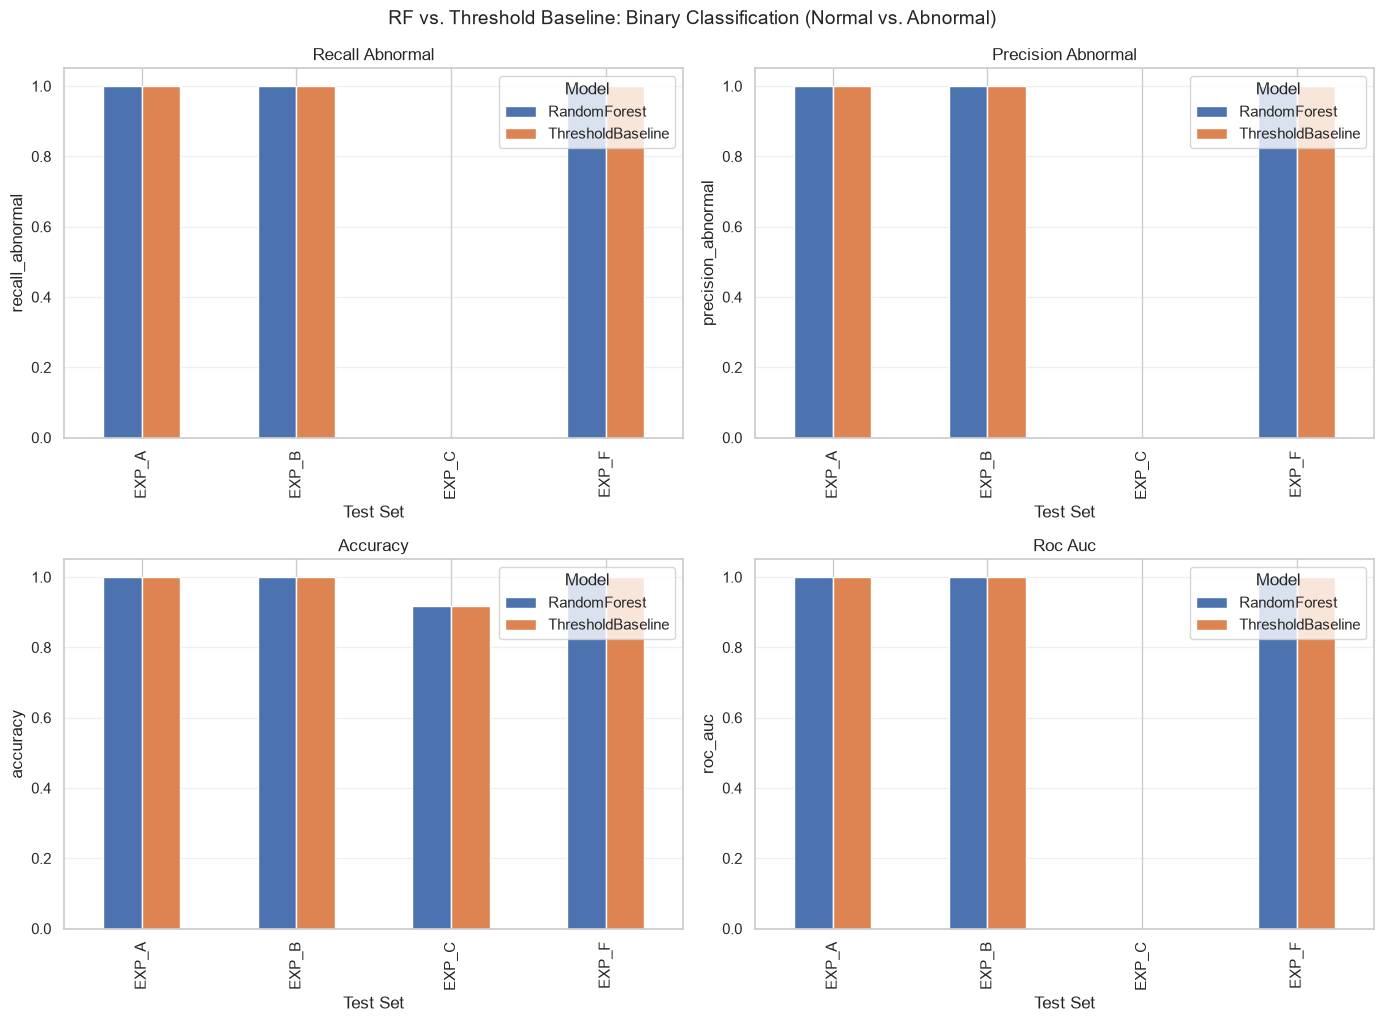

In [149]:
import matplotlib.pyplot as plt

metrics_to_plot = ['recall_abnormal', 'precision_abnormal', 'accuracy', 'roc_auc']
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, metric in zip(axes.flat, metrics_to_plot):
    pivot = results_df.pivot(index='test_set', columns='model', values=metric)
    pivot.plot(kind='bar', ax=ax)
    ax.set_title(metric.replace('_', ' ').title())
    ax.set_ylabel(metric)
    ax.set_xlabel('Test Set')
    ax.legend(title='Model')
    ax.set_ylim(0, 1.05)
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.suptitle('RF vs. Threshold Baseline: Binary Classification (Normal vs. Abnormal)', y=1.02, fontsize=14)
plt.show()

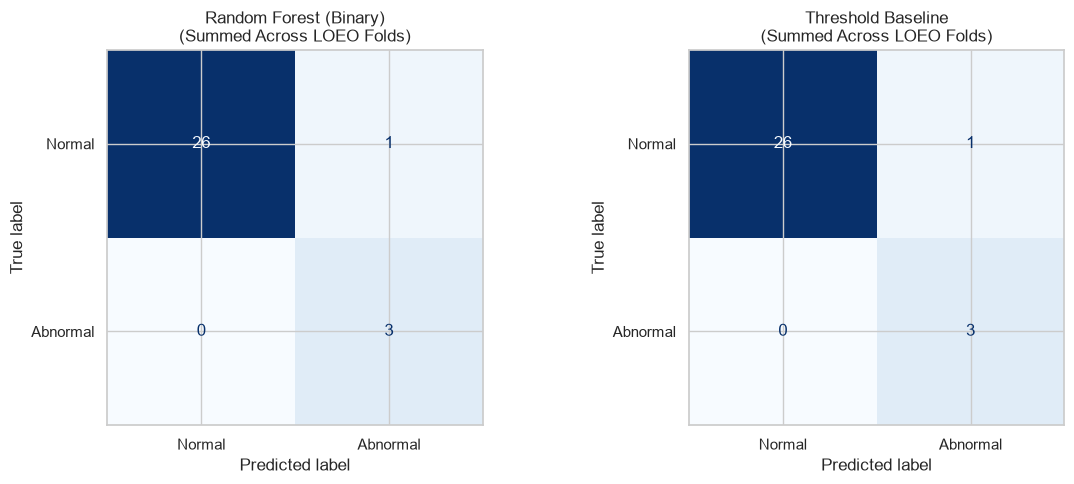

In [151]:

from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, cm, title in zip(
    axes,
    [confusion_rf_sum, confusion_tb_sum],
    ['Random Forest (Binary)', 'Threshold Baseline']
):
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Normal', 'Abnormal'])
    disp.plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(f'{title}\n(Summed Across LOEO Folds)')

plt.tight_layout()
plt.show()

XGBoost Model using Engineered Features - "Can vibration sensor features identified through previous feature engineering accurately predict the severity of gear tooth spall damage on an unseen gear?"

Training runs: 17
Testing runs: 12

=== XGBoost Regression Results ===
MAE:  0.2096
RMSE: 0.3051
R²:   0.5535

Predictions:


,run_num,test_hours,gt_condition,predicted_damage,absolute_error
0,1,6.121,1.300,1.913,0.613
1,2,12.276,1.400,1.913,0.513
2,3,18.424,1.473,1.618,0.145
3,4,24.588,1.500,1.566,0.066
4,5,30.759,1.546,1.566,0.020
5,6,36.913,1.546,1.566,0.020
6,7,43.068,1.546,1.566,0.020
7,8,49.228,1.600,1.566,0.034
8,9,55.394,1.700,1.566,0.134
9,10,61.551,1.700,1.566,0.134


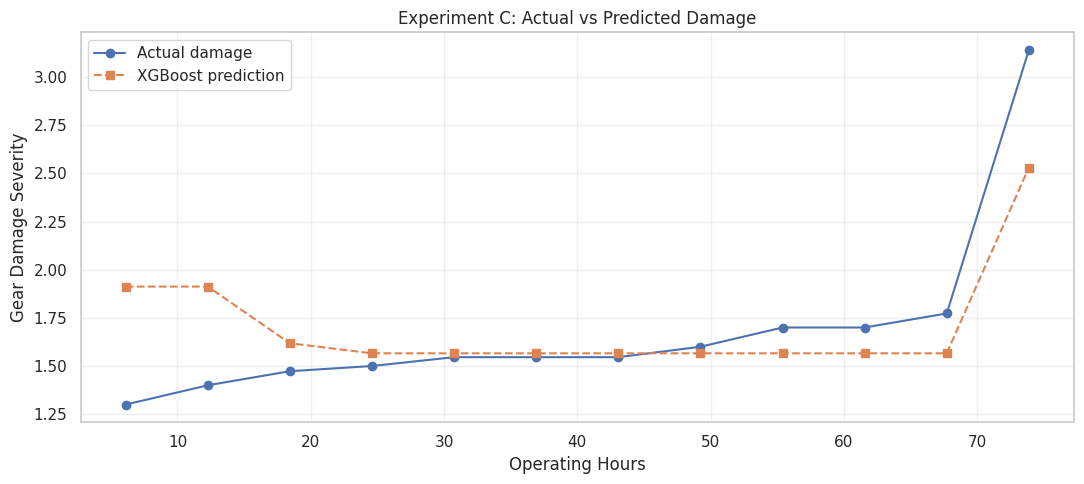

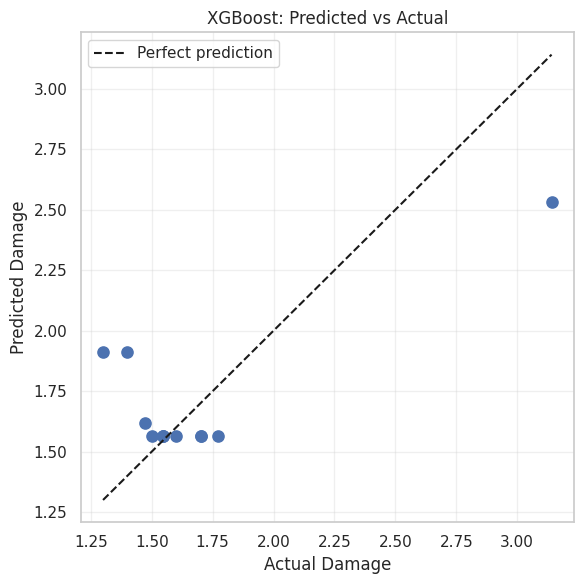

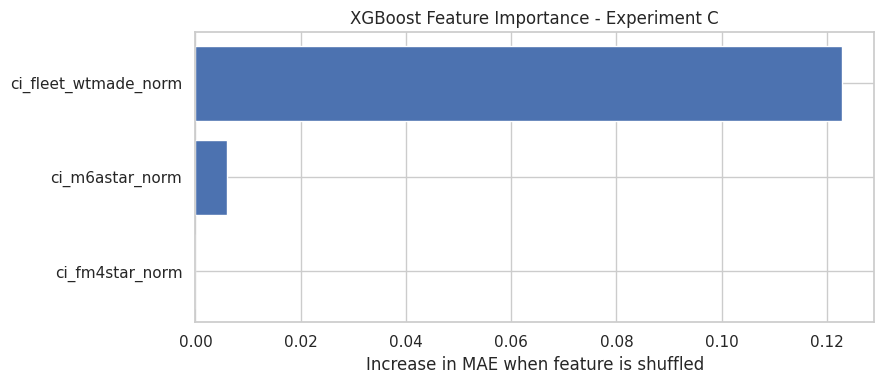

In [ ]:

# XGBoost model to predict gear damage

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

# Use the three features picked from our earlier PCA work
FEATURES = [
    "ci_fleet_wtmade_norm",
    "ci_fm4star_norm",
    "ci_m6astar_norm"
]

# This is the damage score we want to predict
TARGET = "gt_condition"

# Combine experiments A, B, and F for training
# Experiment C will be used to test the model
train_df = pd.concat(
    [EXP_A_df_trans, EXP_B_df_trans, EXP_F_df_trans],
    ignore_index=True
).copy()

test_df = EXP_C_df_trans.copy()

# Remove rows that are missing needed values
train_df = train_df.dropna(subset=FEATURES + [TARGET])
test_df = test_df.dropna(subset=FEATURES + [TARGET])

# Separate the sensor features from the damage scores
X_train = train_df[FEATURES]
y_train = train_df[TARGET].astype(float)

X_test = test_df[FEATURES]
y_test = test_df[TARGET].astype(float)

print("Training runs:", len(X_train))
print("Testing runs:", len(X_test))

# Build the XGBoost model
# Keep the trees small to help prevent overfitting
model = XGBRegressor(
    objective="reg:squarederror",
    n_estimators=100,
    max_depth=2,
    learning_rate=0.03,
    min_child_weight=2,
    subsample=1.0,
    colsample_bytree=1.0,
    reg_alpha=0.1,
    reg_lambda=5.0,
    random_state=42,
    n_jobs=2
)

# Train the model using the three experiments
model.fit(X_train, y_train)

# Predict damage scores for experiment C
predictions = model.predict(X_test)

# Check how close our predictions are to the real scores
mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print("\n=== XGBoost Regression Results ===")
print(f"MAE:  {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R²:   {r2:.4f}")

# Make a table showing the real and predicted damage
results_df = test_df[["run_num", "test_hours", TARGET]].copy()
results_df["predicted_damage"] = predictions

# Find how far each prediction is from the real score
results_df["absolute_error"] = np.abs(
    y_test.to_numpy() - predictions
)

print("\nPredictions:")
display(results_df.round(3))

# Graph 1: Compare real and predicted damage over time
results_df = results_df.sort_values("test_hours")

plt.figure(figsize=(11, 5))
plt.plot(
    results_df["test_hours"],
    results_df[TARGET],
    "o-", label="Actual damage"
)
plt.plot(
    results_df["test_hours"],
    results_df["predicted_damage"],
    "s--", label="XGBoost prediction"
)

plt.xlabel("Operating Hours")
plt.ylabel("Gear Damage Severity")
plt.title("Experiment C: Actual vs Predicted Damage")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Graph 2: See how close predictions are to actual scores
plt.figure(figsize=(6, 6))
plt.scatter(y_test, predictions, s=65)

# Add a line showing where perfect predictions would be
lo = min(y_test.min(), predictions.min())
hi = max(y_test.max(), predictions.max())

plt.plot(
    [lo, hi], [lo, hi],
    "k--", label="Perfect prediction"
)

plt.xlabel("Actual Damage")
plt.ylabel("Predicted Damage")
plt.title("XGBoost: Predicted vs Actual")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Graph 3: Find which sensor features help the model most
# Shuffle each feature to see how much prediction error changes
importance = permutation_importance(
    model, X_test, y_test,
    scoring="neg_mean_absolute_error",
    n_repeats=30,
    random_state=42
)

# Put the feature importance results into a table
importance_df = pd.DataFrame({
    "Feature": FEATURES,
    "Importance": importance.importances_mean
}).sort_values("Importance")

# Plot the feature importance scores
plt.figure(figsize=(9, 4))
plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)

plt.xlabel("Increase in MAE when feature is shuffled")
plt.title("XGBoost Feature Importance - Experiment C")
plt.tight_layout()
plt.show()


The XGBoost model had an MAE of 0.2096, RMSE of 0.3051, and R² of 0.5535. This means the model was able to explain about 55% of the differences in gear damage scores, with an average error of 0.21. The model did a good job predicting moderate damage but was less accurate when damage was very low or very high. Additional tests will be run to improve the MAE and the R².

=== XGBoost Feature Ablation Results ===
                                              Features  Number of Features    MAE   RMSE      R2
                                       ci_m6astar_norm                   1 0.1898 0.2847  0.6113
                 ci_fleet_wtmade_norm, ci_m6astar_norm                   2 0.2096 0.3051  0.5535
ci_fleet_wtmade_norm, ci_fm4star_norm, ci_m6astar_norm                   3 0.2096 0.3051  0.5535
                 ci_fleet_wtmade_norm, ci_fm4star_norm                   2 0.2192 0.3062  0.5502
                                  ci_fleet_wtmade_norm                   1 0.2206 0.3053  0.5531
                      ci_fm4star_norm, ci_m6astar_norm                   2 0.4071 0.5386 -0.3916
                                       ci_fm4star_norm                   1 0.4134 0.5484 -0.4424


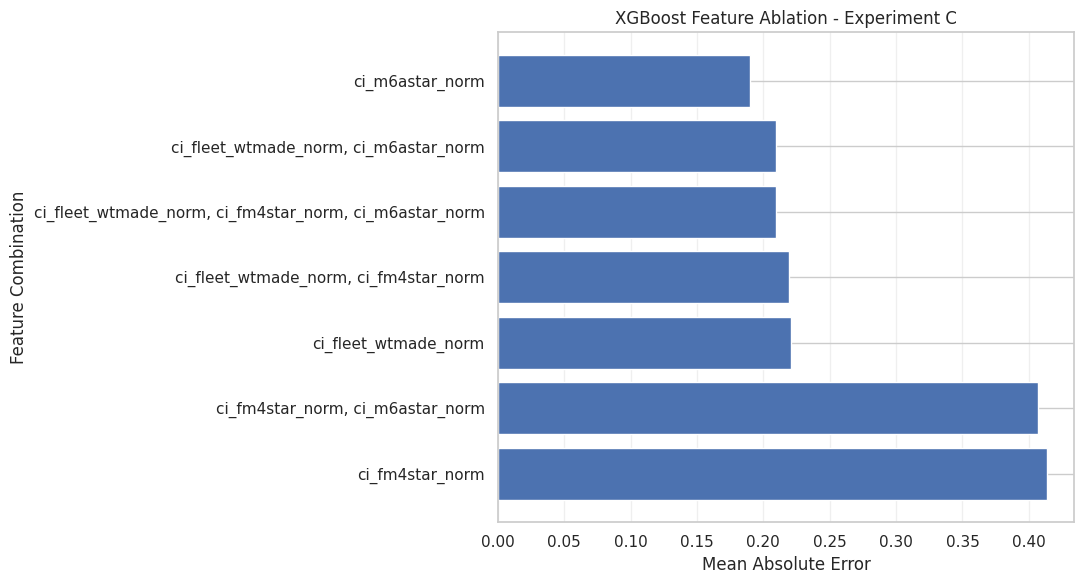


Lowest Test MAE:
Features: ci_m6astar_norm
MAE: 0.1898


In [ ]:
# Test 1 - isolate features to improve MAE
# We want to see which features help predict gear damage

from itertools import combinations
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Use the features selected from our earlier PCA work
features = [
    "ci_fleet_wtmade_norm",
    "ci_fm4star_norm",
    "ci_m6astar_norm"
]

# Try every possible combination of these features
feature_groups = []

for size in range(1, len(features) + 1):
    feature_groups.extend(combinations(features, size))

# Save the results from each model
ablation_results = []

# Train a new model for each feature combination
for group in feature_groups:

    selected_features = list(group)

    # Use the same XGBoost settings for a fair comparison
    ablation_model = XGBRegressor(
        objective="reg:squarederror",
        n_estimators=100,
        max_depth=2,
        learning_rate=0.03,
        min_child_weight=2,
        subsample=1.0,
        colsample_bytree=1.0,
        reg_alpha=0.1,
        reg_lambda=5.0,
        random_state=42,
        n_jobs=2
    )

    # Train using only the selected features
    ablation_model.fit(
        train_df[selected_features],
        y_train
    )

    # Predict damage on Experiment C
    predicted = ablation_model.predict(
        test_df[selected_features]
    )

    # Calculate how accurate the predictions are
    mae = mean_absolute_error(y_test, predicted)
    rmse = np.sqrt(mean_squared_error(y_test, predicted))
    r2 = r2_score(y_test, predicted)

    # Save the results for comparison
    ablation_results.append({
        "Features": ", ".join(selected_features),
        "Number of Features": len(selected_features),
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

# Put all the results into one table
ablation_df = pd.DataFrame(ablation_results)

# Sort from lowest error to highest error
ablation_df = ablation_df.sort_values("MAE")

print("=== XGBoost Feature Ablation Results ===")
print(ablation_df.round(4).to_string(index=False))

# Graph the prediction error for each feature combination
plt.figure(figsize=(11, 6))

plt.barh(
    ablation_df["Features"],
    ablation_df["MAE"]
)

plt.xlabel("Mean Absolute Error")
plt.ylabel("Feature Combination")
plt.title("XGBoost Feature Ablation - Experiment C")
plt.gca().invert_yaxis()
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

# Show the best combination based on test MAE
best_features = ablation_df.iloc[0]

print("\nLowest Test MAE:")
print("Features:", best_features["Features"])
print("MAE:", round(best_features["MAE"], 4))


Test 1 compared seven different combinations of the three vibration features to see which worked best with XGBoost. The results showed that using only ci_m6astar_norm gave the best predictions, with an MAE of 0.1898 and an R² of 0.6113. This was better than using all three features, which had an MAE of 0.2096 and an R² of 0.5535. These results suggest that adding more features does not always improve the model's accuracy and that some vibration measurements may be more useful than others when predicting gear damage.

=== Leave-One-Gear-Out Results ===
Test Gear  Features  Training Runs  Testing Runs    MAE   RMSE      R2
        A  M6A Only             25             4 1.1603 1.4042 -0.5865
        A All Three             25             4 1.0946 1.3869 -0.5478
        B  M6A Only             22             7 0.5474 0.6835  0.1688
        B All Three             22             7 0.6017 0.6927  0.1464
        C  M6A Only             17            12 0.4113 0.4721 -0.0688
        C All Three             17            12 0.4218 0.5606 -0.5074
        F  M6A Only             23             6 0.7821 0.8917 -0.6014
        F All Three             23             6 0.4903 0.5095  0.4771

=== Average Results Across Gears ===
              MAE    RMSE
Features                 
All Three  0.6521  0.7874
M6A Only   0.7253  0.8629


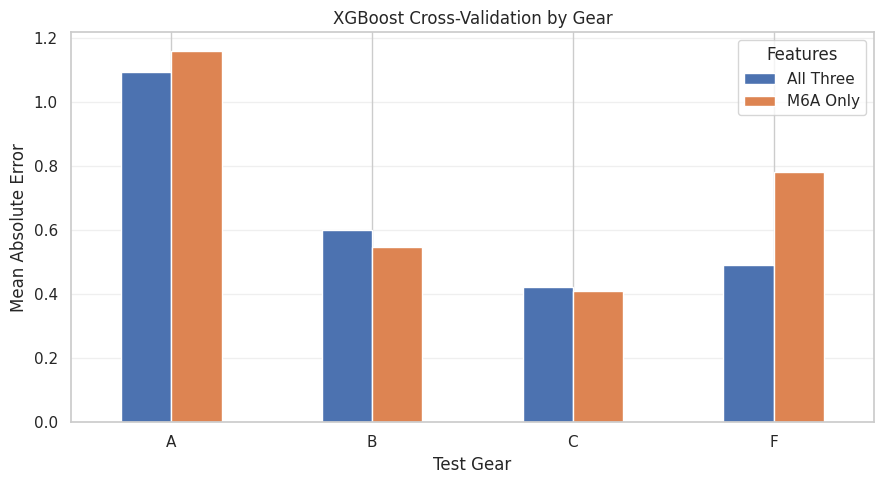

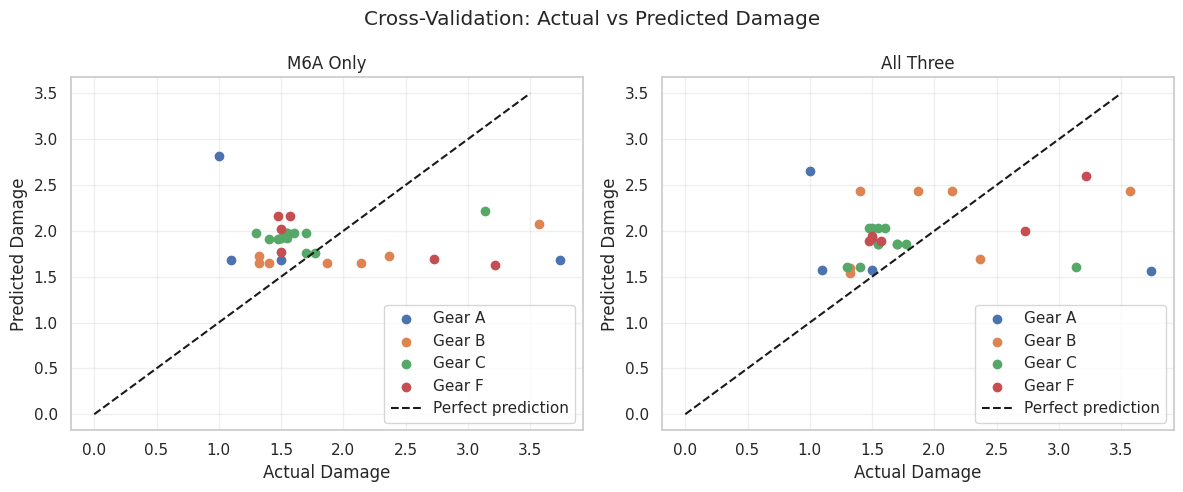

In [ ]:

# Test 2 - validation of using selected features on individual gears
# Test whether one feature or all three work better

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from xgboost import XGBRegressor
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Use the baseline-subtracted versions of our PCA features
# We will normalize them using training data only
all_features = [
    "ci_fleet_wtmade_new",
    "ci_fm4star_new",
    "ci_m6astar_new"
]

# Compare the single best feature against all three
feature_sets = {
    "M6A Only": ["ci_m6astar_new"],
    "All Three": all_features
}

# Store the run-level data for each gear
gear_data = {
    "A": EXP_A_df_trans.copy(),
    "B": EXP_B_df_trans.copy(),
    "C": EXP_C_df_trans.copy(),
    "F": EXP_F_df_trans.copy()
}

# Save the results from each test
cv_results = []
cv_predictions = []

# Test each gear separately
for test_gear in gear_data:

    # Use the other three gears for training
    train_gears = [
        gear for gear in gear_data
        if gear != test_gear
    ]

    train_df_cv = pd.concat(
        [gear_data[gear] for gear in train_gears],
        ignore_index=True
    )

    test_df_cv = gear_data[test_gear].copy()

    # Train a model using each feature combination
    for feature_name, selected_features in feature_sets.items():

        # Remove rows with missing damage scores or features
        train_clean = train_df_cv.dropna(
            subset=selected_features + ["gt_condition"]
        ).copy()

        test_clean = test_df_cv.dropna(
            subset=selected_features + ["gt_condition"]
        ).copy()

        X_train_cv = train_clean[selected_features]
        y_train_cv = train_clean["gt_condition"].astype(float)

        X_test_cv = test_clean[selected_features]
        y_test_cv = test_clean["gt_condition"].astype(float)

        # Normalize using the training gears only
        scaler = MinMaxScaler()

        X_train_scaled = scaler.fit_transform(X_train_cv)
        X_test_scaled = scaler.transform(X_test_cv)

        # Build the same XGBoost model used earlier
        cv_model = XGBRegressor(
            objective="reg:squarederror",
            n_estimators=100,
            max_depth=2,
            learning_rate=0.03,
            min_child_weight=2,
            subsample=1.0,
            colsample_bytree=1.0,
            reg_alpha=0.1,
            reg_lambda=5.0,
            random_state=42,
            n_jobs=2
        )

        # Train on three gears
        cv_model.fit(X_train_scaled, y_train_cv)

        # Predict damage on the gear left out
        predictions_cv = cv_model.predict(X_test_scaled)

        # Calculate the prediction errors
        mae = mean_absolute_error(y_test_cv, predictions_cv)
        rmse = np.sqrt(
            mean_squared_error(y_test_cv, predictions_cv)
        )

        # R2 needs at least two different target values
        if len(y_test_cv) > 1 and y_test_cv.nunique() > 1:
            r2 = r2_score(y_test_cv, predictions_cv)
        else:
            r2 = np.nan

        # Save the results for this gear
        cv_results.append({
            "Test Gear": test_gear,
            "Features": feature_name,
            "Training Runs": len(X_train_cv),
            "Testing Runs": len(X_test_cv),
            "MAE": mae,
            "RMSE": rmse,
            "R2": r2
        })

        # Save each prediction for later graphs
        for actual, predicted in zip(
            y_test_cv.to_numpy(),
            predictions_cv
        ):
            cv_predictions.append({
                "Test Gear": test_gear,
                "Features": feature_name,
                "Actual": actual,
                "Predicted": predicted
            })

# Turn the results into tables
cv_results_df = pd.DataFrame(cv_results)
cv_predictions_df = pd.DataFrame(cv_predictions)

print("=== Leave-One-Gear-Out Results ===")
print(
    cv_results_df.round(4).to_string(index=False)
)

# Compare the average error for each feature set
summary_df = (
    cv_results_df
    .groupby("Features")[["MAE", "RMSE"]]
    .mean()
    .sort_values("MAE")
)

print("\n=== Average Results Across Gears ===")
print(summary_df.round(4).to_string())

# Graph the MAE for each gear
mae_comparison = cv_results_df.pivot(
    index="Test Gear",
    columns="Features",
    values="MAE"
)

mae_comparison.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("XGBoost Cross-Validation by Gear")
plt.xlabel("Test Gear")
plt.ylabel("Mean Absolute Error")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Compare predictions against actual damage
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, feature_name in zip(axes, feature_sets):

    subset = cv_predictions_df[
        cv_predictions_df["Features"] == feature_name
    ]

    for gear in gear_data:
        gear_subset = subset[
            subset["Test Gear"] == gear
        ]

        ax.scatter(
            gear_subset["Actual"],
            gear_subset["Predicted"],
            label=f"Gear {gear}"
        )

    ax.plot(
        [0, 3.5], [0, 3.5],
        "k--",
        label="Perfect prediction"
    )

    ax.set_title(feature_name)
    ax.set_xlabel("Actual Damage")
    ax.set_ylabel("Predicted Damage")
    ax.grid(alpha=0.3)
    ax.legend()

plt.suptitle("Cross-Validation: Actual vs Predicted Damage")
plt.tight_layout()
plt.show()


For Test 2, I wanted to see how well XGBoost could predict damage on gears it had never seen before. I tested the model using just the M6A feature and then using all three features. Using all three gave better results, with an average error of 0.6521 compared to 0.7253 for M6A alone. However, the model did better on some gears than others. This showed that the model still had trouble predicting damage accurately when working with different gears.

=== Error by Damage Level ===
 Features Damage Level  Runs    MAE  Mean_Error   RMSE
All Three          Low     9 0.5716      0.5716 0.7280
All Three     Moderate    15 0.3502      0.2607 0.3918
All Three         High     5 1.2392     -1.2392 1.3645
 M6A Only          Low     9 0.6325      0.6325 0.7717
 M6A Only     Moderate    15 0.3542      0.1708 0.3953
 M6A Only         High     5 1.4193     -1.4193 1.4763


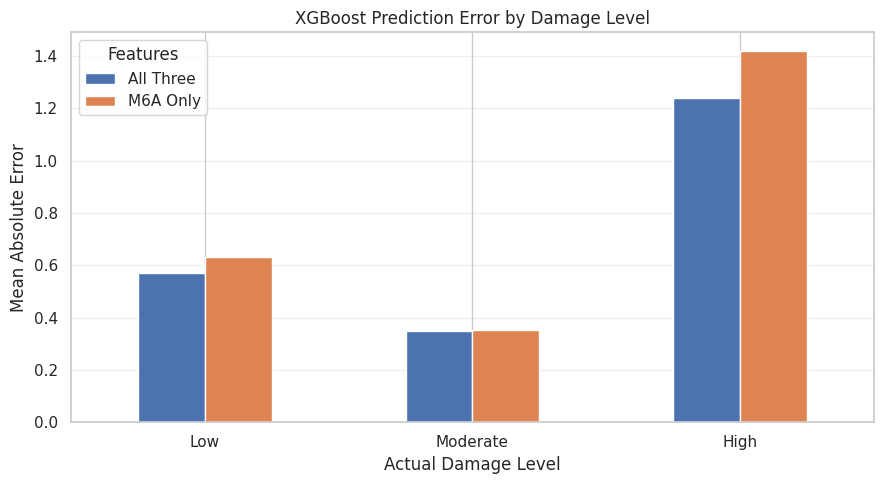

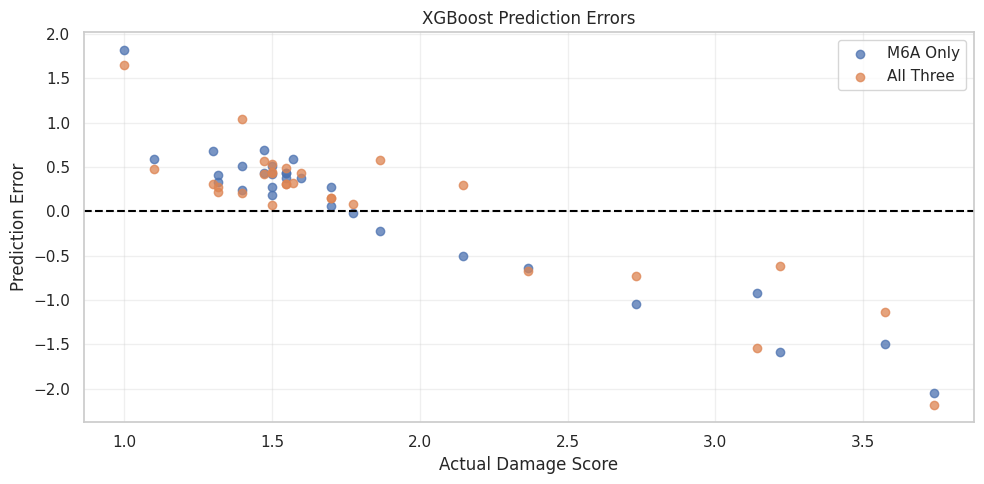

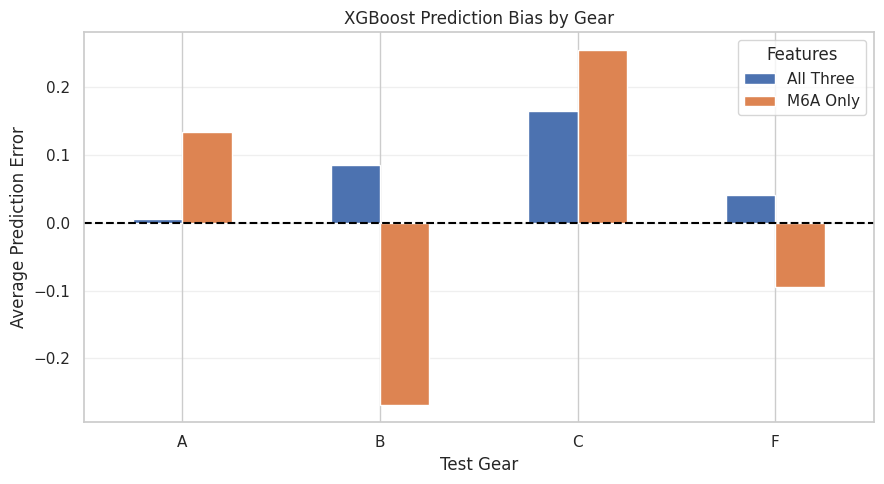


=== Underestimated Damage ===
 Features Damage Level  Runs  Underestimated  Underestimated %
All Three          Low     9               0              0.00
All Three     Moderate    15               1              6.67
All Three         High     5               5            100.00
 M6A Only          Low     9               0              0.00
 M6A Only     Moderate    15               4             26.67
 M6A Only         High     5               5            100.00

=== XGBoost vs Simple Baseline ===
Test Gear  Features    MAE  Baseline MAE  MAE Improvement
        A  M6A Only 1.1603        0.9586          -0.2017
        A All Three 1.0946        0.9586          -0.1360
        B  M6A Only 0.5474        0.5876           0.0402
        B All Three 0.6017        0.5876          -0.0141
        C  M6A Only 0.4113        0.4714           0.0601
        C All Three 0.4218        0.4714           0.0496
        F  M6A Only 0.7821        0.5860          -0.1961
        F All Three 0.4903  

In [ ]:

# test 3 - Look at where our XGBoost models make mistakes
# Compare prediction errors at different damage levels

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Use the predictions saved during cross-validation
error_df = cv_predictions_df.copy()

# Find the difference between predicted and actual damage
# A negative value means the model predicted too little damage
# A positive value means the model predicted too much damage
error_df["Error"] = (
    error_df["Predicted"] - error_df["Actual"]
)

# Find how large each prediction error is
error_df["Absolute Error"] = error_df["Error"].abs()

# Split the actual damage scores into three groups
# These are groups for analysis, not official damage classes
error_df["Damage Level"] = pd.cut(
    error_df["Actual"],
    bins=[-np.inf, 1.5, 2.5, np.inf],
    labels=["Low", "Moderate", "High"],
    right=False
)

# Calculate the average errors for each damage level
severity_results = (
    error_df
    .groupby(
        ["Features", "Damage Level"],
        observed=True
    )
    .agg(
        Runs=("Error", "count"),
        MAE=("Absolute Error", "mean"),
        Mean_Error=("Error", "mean"),
        RMSE=("Error", lambda x: np.sqrt(np.mean(x**2)))
    )
    .reset_index()
)

print("=== Error by Damage Level ===")
print(severity_results.round(4).to_string(index=False))

# Graph 1: Compare prediction errors by damage level
severity_plot = severity_results.pivot(
    index="Damage Level",
    columns="Features",
    values="MAE"
)

severity_plot = severity_plot.reindex(
    ["Low", "Moderate", "High"]
)

severity_plot.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("XGBoost Prediction Error by Damage Level")
plt.xlabel("Actual Damage Level")
plt.ylabel("Mean Absolute Error")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Graph 2: Check if the models predict too high or too low
plt.figure(figsize=(10, 5))

for feature_name in error_df["Features"].unique():

    subset = error_df[
        error_df["Features"] == feature_name
    ]

    plt.scatter(
        subset["Actual"],
        subset["Error"],
        label=feature_name,
        alpha=0.75
    )

# The zero line shows where predictions are correct
plt.axhline(0, color="black", linestyle="--")

plt.title("XGBoost Prediction Errors")
plt.xlabel("Actual Damage Score")
plt.ylabel("Prediction Error")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Graph 3: Compare the average error for each gear
gear_error_results = (
    error_df
    .groupby(["Test Gear", "Features"])
    .agg(
        MAE=("Absolute Error", "mean"),
        Mean_Error=("Error", "mean")
    )
    .reset_index()
)

gear_error_plot = gear_error_results.pivot(
    index="Test Gear",
    columns="Features",
    values="Mean_Error"
)

gear_error_plot.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.axhline(0, color="black", linestyle="--")
plt.title("XGBoost Prediction Bias by Gear")
plt.xlabel("Test Gear")
plt.ylabel("Average Prediction Error")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Find how often each model underestimates damage
underestimate_results = (
    error_df
    .assign(
        Underestimated=lambda df: df["Error"] < 0
    )
    .groupby(["Features", "Damage Level"], observed=True)
    .agg(
        Runs=("Underestimated", "count"),
        Underestimated=("Underestimated", "sum")
    )
    .reset_index()
)

# Turn the counts into percentages
underestimate_results["Underestimated %"] = (
    underestimate_results["Underestimated"]
    / underestimate_results["Runs"] * 100
)

print("\n=== Underestimated Damage ===")
print(
    underestimate_results.round(2).to_string(index=False)
)

# Check whether a simple model would do better
# Use the average training damage score for each held-out gear
gear_data = {
    "A": EXP_A_df_trans,
    "B": EXP_B_df_trans,
    "C": EXP_C_df_trans,
    "F": EXP_F_df_trans
}

baseline_results = []

for test_gear in gear_data:

    # Combine the other three gears for training
    train_parts = [
        df for gear, df in gear_data.items()
        if gear != test_gear
    ]

    train_baseline = pd.concat(
        train_parts,
        ignore_index=True
    )

    # Use the average training damage as our prediction
    average_damage = train_baseline["gt_condition"].mean()

    test_actual = gear_data[test_gear][
        "gt_condition"
    ].dropna()

    baseline_mae = np.mean(
        np.abs(test_actual - average_damage)
    )

    baseline_results.append({
        "Test Gear": test_gear,
        "Baseline MAE": baseline_mae
    })

baseline_df = pd.DataFrame(baseline_results)

# Compare the baseline with our XGBoost results
comparison_df = cv_results_df.merge(
    baseline_df,
    on="Test Gear"
)

comparison_df["MAE Improvement"] = (
    comparison_df["Baseline MAE"]
    - comparison_df["MAE"]
)

print("\n=== XGBoost vs Simple Baseline ===")
print(
    comparison_df[
        [
            "Test Gear",
            "Features",
            "MAE",
            "Baseline MAE",
            "MAE Improvement"
        ]
    ].round(4).to_string(index=False)
)


For Test 3, I wanted to see how well XGBoost predicted different levels of gear damage. The results showed that the model did best with moderate damage, with an average error of 0.3502 when using all three features. It had more trouble with low damage, with an error of 0.5716, and high damage, with an error of 1.2392. The model also predicted every high-damage case lower than its actual score. This showed that XGBoost was better at predicting normal damage levels but struggled when the damage became more severe.

RUNS AVAILABLE BY GEAR
Gear A: 4 runs
Gear B: 7 runs
Gear C: 12 runs
Gear F: 6 runs

RESULTS BY GEAR
           Model Gear  Runs    MAE   RMSE      R2  High Damage MAE
Original XGBoost    A     4 1.0946 1.3869 -0.5478           2.1784
   Final XGBoost    A     4 1.1600 1.4405 -0.6697           2.1162
Original XGBoost    B     7 0.6017 0.6927  0.1464           1.1337
   Final XGBoost    B     7 0.2611 0.3171  0.8211           0.3394
Original XGBoost    C    12 0.4218 0.5606 -0.5074           1.5389
   Final XGBoost    C    12 0.2054 0.4390  0.0758           1.4707
Original XGBoost    F     6 0.4903 0.5095  0.4771           0.6725
   Final XGBoost    F     6 0.4113 0.4977  0.5010           0.4902

AVERAGE RESULTS ACROSS FOUR GEARS
           Model  Average_MAE  Average_RMSE  Average_R2  Average_High_MAE
   Final XGBoost       0.5095        0.6736      0.1821            1.1041
Original XGBoost       0.6521        0.7874     -0.1079            1.3809

Original XGBoost MAE: 0.6521
Final XGB

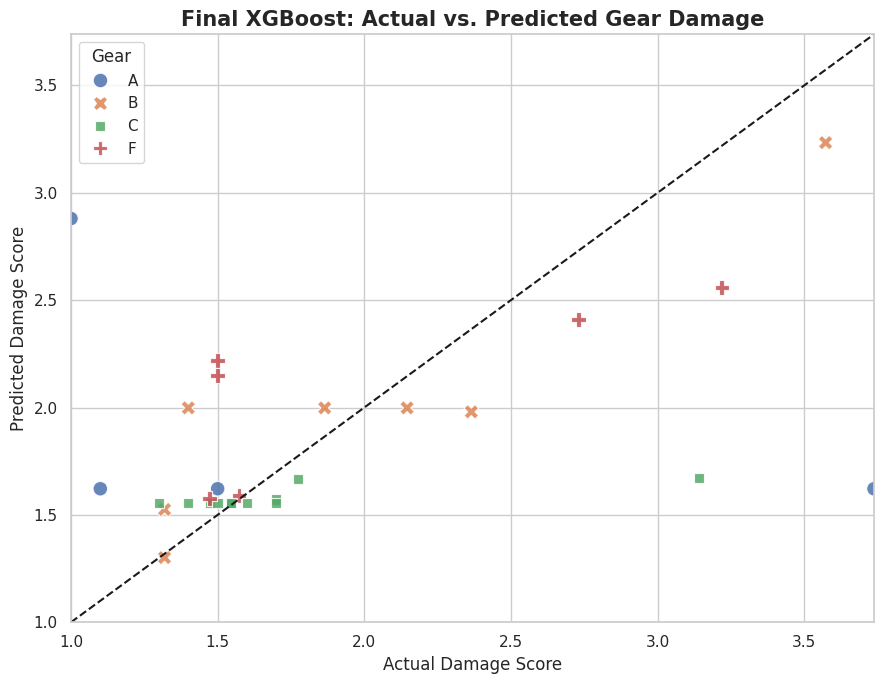

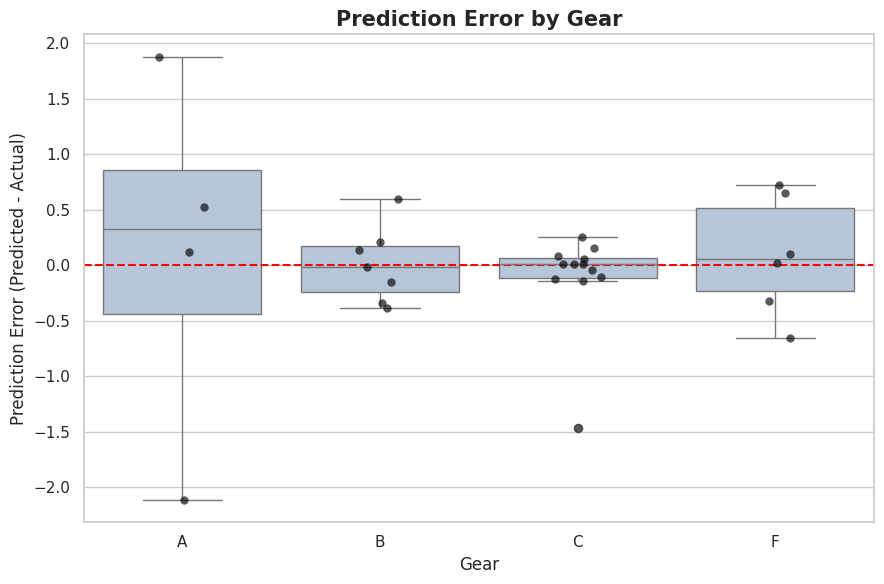

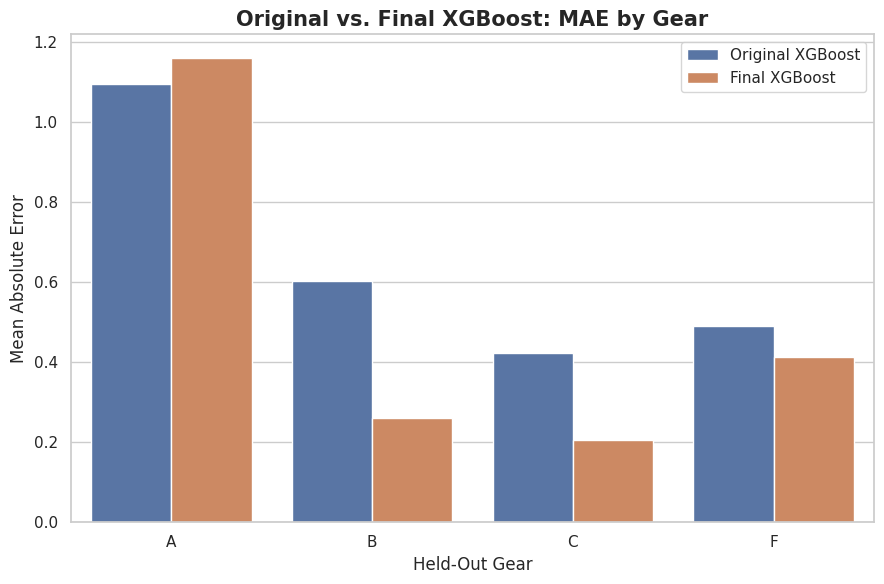

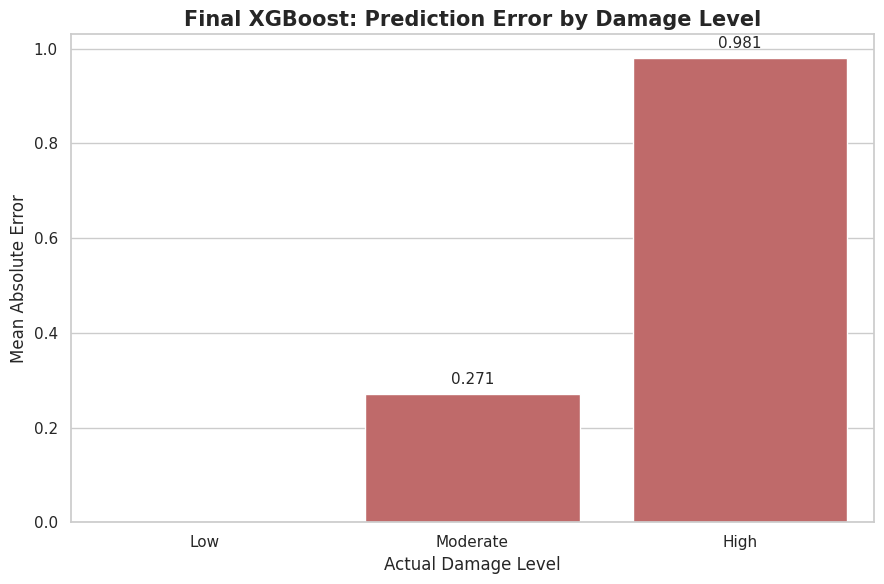

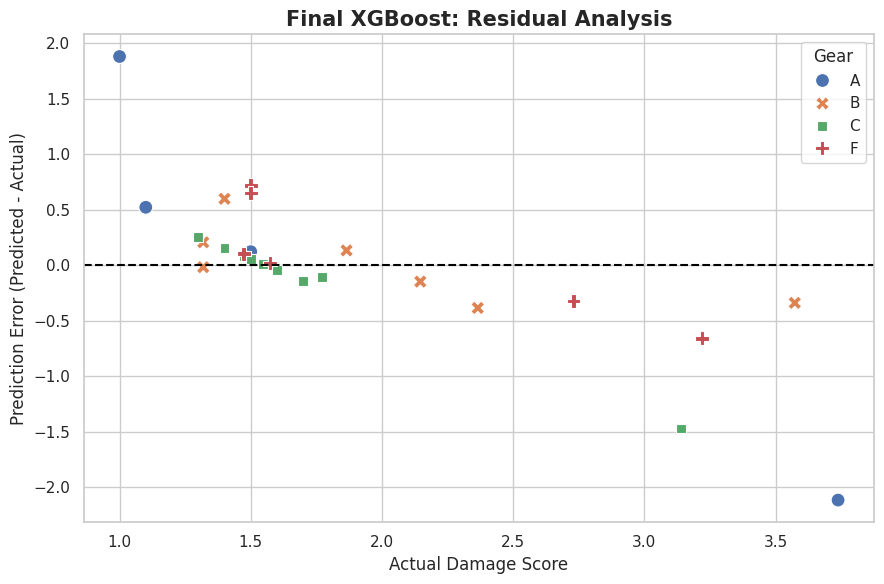

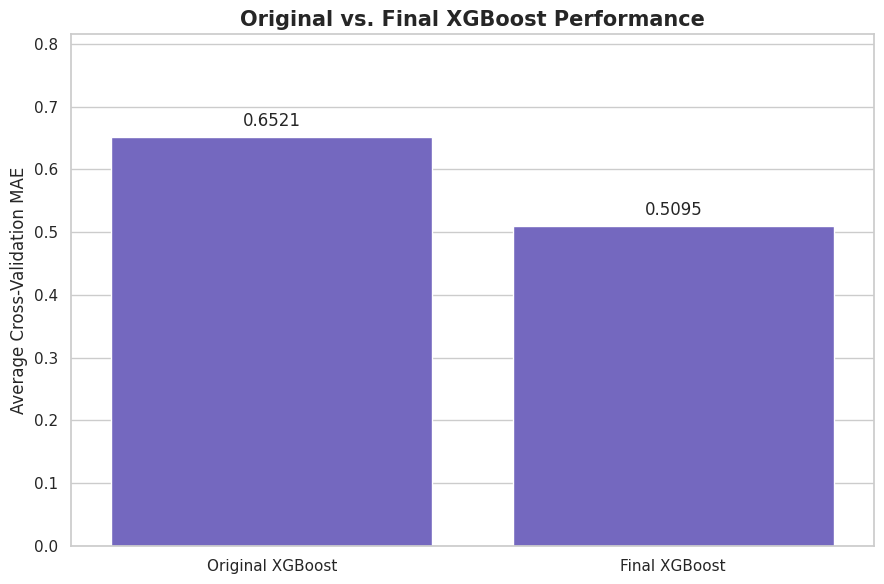

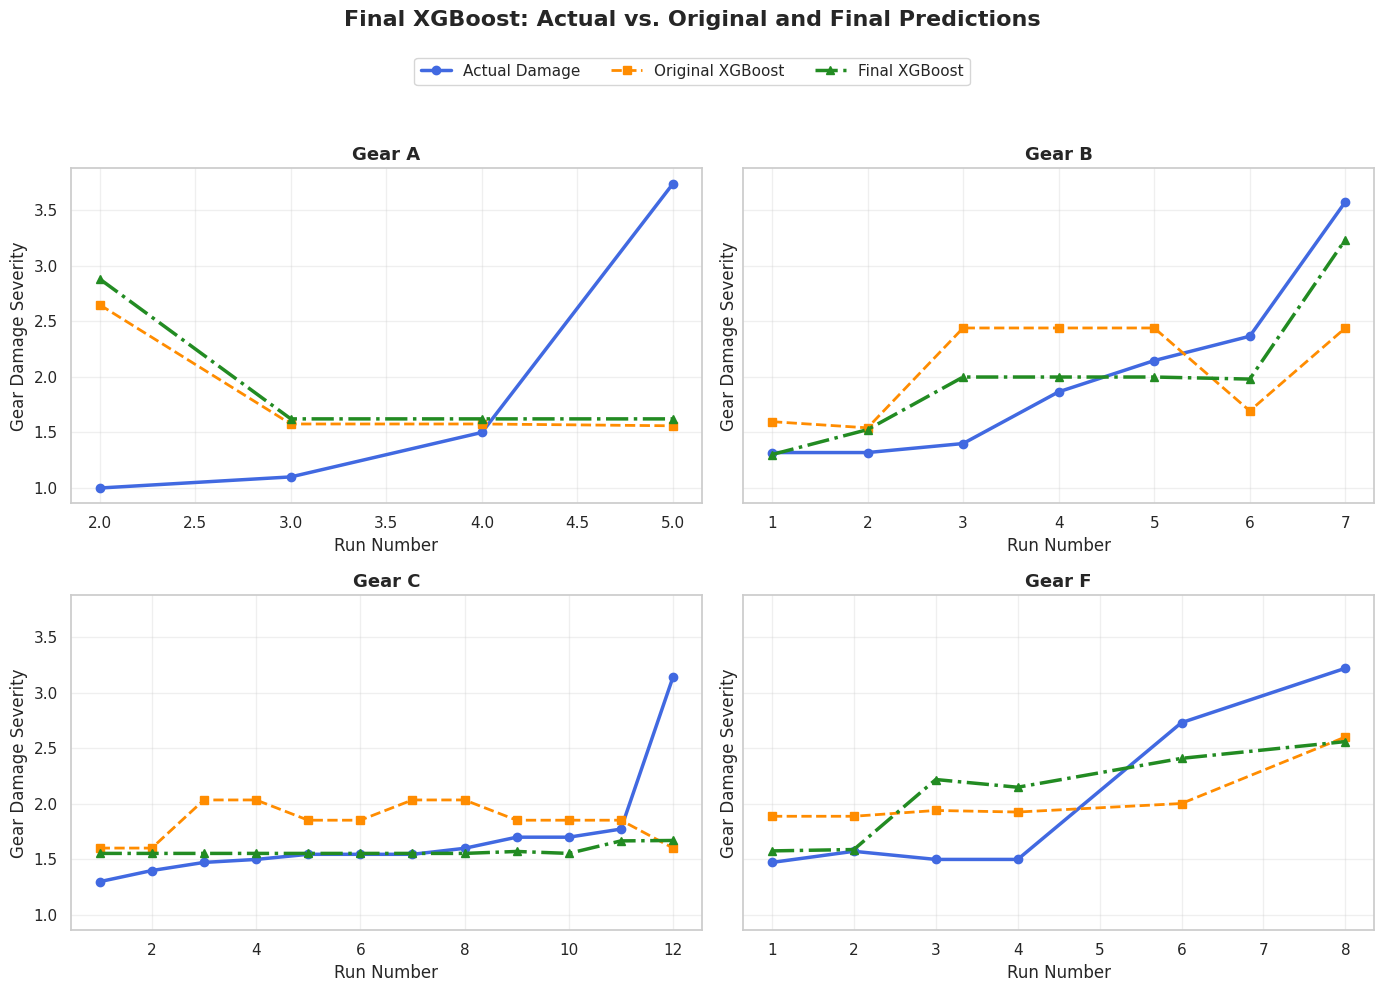

['final_xgboost_gear_damage.pkl']

In [ ]:

# ============================================================
# FINAL XGBOOST MODEL - GEAR TOOTH DAMAGE PREDICTION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from xgboost import XGBRegressor
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

sns.set_theme(style="whitegrid")

# ------------------------------------------------------------
# 1. Select vibration features and prediction target
# ------------------------------------------------------------

FEATURES = [
    "ci_fleet_wtmade_new",
    "ci_fm4star_new",
    "ci_m6astar_new"
]

TARGET = "gt_condition"

GEARS = ["A", "B", "C", "F"]

HIGH_DAMAGE_THRESHOLD = 2.5
HIGH_DAMAGE_WEIGHT = 3.0

# Final hyperparameters selected in Test 7
BEST_PARAMS = {
    "objective": "reg:pseudohubererror",
    "n_estimators": 600,
    "max_depth": 3,
    "learning_rate": 0.15,
    "min_child_weight": 3,
    "reg_alpha": 1,
    "reg_lambda": 5,
    "gamma": 0.1,
    "subsample": 0.9,
    "colsample_bytree": 0.8,
    "random_state": 42,
    "n_jobs": 2,
    "tree_method": "hist"
}

# Original model settings
ORIGINAL_PARAMS = {
    "objective": "reg:squarederror",
    "n_estimators": 100,
    "max_depth": 2,
    "learning_rate": 0.03,
    "min_child_weight": 2,
    "reg_alpha": 0.1,
    "reg_lambda": 5.0,
    "gamma": 0,
    "subsample": 1.0,
    "colsample_bytree": 1.0,
    "random_state": 42,
    "n_jobs": 2
}

# ------------------------------------------------------------
# 2. Prepare the gear data
# ------------------------------------------------------------

gear_data = {
    "A": EXP_A_df_trans.copy(),
    "B": EXP_B_df_trans.copy(),
    "C": EXP_C_df_trans.copy(),
    "F": EXP_F_df_trans.copy()
}

# Match the previous experiments:
# exclude the duplicated Run 1 from Gear A.
gear_data["A"] = gear_data["A"][
    gear_data["A"]["run_num"] != 1
].copy()

for gear in GEARS:

    df = gear_data[gear].copy()

    df = df.replace(
        [np.inf, -np.inf],
        np.nan
    )

    df = df.dropna(
        subset=FEATURES + [TARGET, "run_num"]
    ).copy()

    df["Gear"] = gear

    gear_data[gear] = df.reset_index(drop=True)

print("RUNS AVAILABLE BY GEAR")

for gear in GEARS:
    print(f"Gear {gear}: {len(gear_data[gear])} runs")

# ------------------------------------------------------------
# 3. Train a model using training data only
# ------------------------------------------------------------

def train_model(train_df, params, high_damage_weight=1.0):

    X_train = train_df[FEATURES]
    y_train = train_df[TARGET]

    # Fit the scaler only on training data
    scaler = MinMaxScaler()

    X_train_scaled = scaler.fit_transform(X_train)

    # Give severe damage extra weight when requested
    weights = np.where(
        y_train.to_numpy() >= HIGH_DAMAGE_THRESHOLD,
        high_damage_weight,
        1.0
    )

    model = XGBRegressor(**params)

    model.fit(
        X_train_scaled,
        y_train,
        sample_weight=weights
    )

    return model, scaler


# ------------------------------------------------------------
# 4. Leave-one-gear-out cross-validation
# Compare original and final XGBoost fairly
# ------------------------------------------------------------

all_predictions = []
gear_results = []

for test_gear in GEARS:

    # Train on the other three gears
    train_df = pd.concat(
        [
            gear_data[g]
            for g in GEARS
            if g != test_gear
        ],
        ignore_index=True
    )

    # Evaluate on the held-out gear
    test_df = gear_data[test_gear].copy()

    actual = test_df[TARGET].to_numpy()

    # Original model
    original_model, original_scaler = train_model(
        train_df,
        ORIGINAL_PARAMS,
        high_damage_weight=1.0
    )

    original_predictions = original_model.predict(
        original_scaler.transform(test_df[FEATURES])
    )

    # Final model
    final_model, final_scaler = train_model(
        train_df,
        BEST_PARAMS,
        high_damage_weight=HIGH_DAMAGE_WEIGHT
    )

    final_predictions = final_model.predict(
        final_scaler.transform(test_df[FEATURES])
    )

    # Store predictions from both models
    fold_predictions = pd.DataFrame({
        "Gear": test_gear,
        "Run Number": test_df["run_num"].to_numpy(),
        "Actual": actual,
        "Original XGBoost": original_predictions,
        "Final XGBoost": final_predictions
    })

    all_predictions.append(fold_predictions)

    # Calculate results for both models
    for model_name, predictions in [
        ("Original XGBoost", original_predictions),
        ("Final XGBoost", final_predictions)
    ]:

        high_mask = actual >= HIGH_DAMAGE_THRESHOLD

        high_mae = (
            mean_absolute_error(
                actual[high_mask],
                predictions[high_mask]
            )
            if high_mask.any()
            else np.nan
        )

        gear_results.append({
            "Model": model_name,
            "Gear": test_gear,
            "Runs": len(actual),
            "MAE": mean_absolute_error(
                actual, predictions
            ),
            "RMSE": np.sqrt(
                mean_squared_error(actual, predictions)
            ),
            "R2": r2_score(actual, predictions),
            "High Damage MAE": high_mae
        })

comparison_df = pd.concat(
    all_predictions,
    ignore_index=True
)

results_df = pd.DataFrame(gear_results)

# Keep the final model predictions in a separate dataframe
# for Figures 1 through 5.
predictions_df = comparison_df[
    ["Gear", "Run Number", "Actual", "Final XGBoost"]
].copy()

predictions_df = predictions_df.rename(
    columns={"Final XGBoost": "Predicted"}
)

predictions_df["Error"] = (
    predictions_df["Predicted"] - predictions_df["Actual"]
)

predictions_df["Absolute Error"] = (
    predictions_df["Error"].abs()
)

# ------------------------------------------------------------
# 5. Display results
# ------------------------------------------------------------

print("\nRESULTS BY GEAR")
print(
    results_df.round(4).to_string(index=False)
)

average_results = (
    results_df
    .groupby("Model")
    .agg(
        Average_MAE=("MAE", "mean"),
        Average_RMSE=("RMSE", "mean"),
        Average_R2=("R2", "mean"),
        Average_High_MAE=("High Damage MAE", "mean")
    )
    .reset_index()
)

print("\nAVERAGE RESULTS ACROSS FOUR GEARS")
print(
    average_results.round(4).to_string(index=False)
)

original_mae = average_results.loc[
    average_results["Model"] == "Original XGBoost",
    "Average_MAE"
].iloc[0]

final_mae = average_results.loc[
    average_results["Model"] == "Final XGBoost",
    "Average_MAE"
].iloc[0]

improvement = (
    (original_mae - final_mae) / original_mae
) * 100

print(f"\nOriginal XGBoost MAE: {original_mae:.4f}")
print(f"Final XGBoost MAE:    {final_mae:.4f}")
print(f"MAE Reduction:        {improvement:.2f}%")

# ------------------------------------------------------------
# 6. Evaluate prediction errors by damage level
# ------------------------------------------------------------

def damage_level(score):

    if score < 1:
        return "Low"
    elif score < 2.5:
        return "Moderate"
    else:
        return "High"


predictions_df["Damage Level"] = (
    predictions_df["Actual"].apply(damage_level)
)

damage_results = (
    predictions_df
    .groupby("Damage Level")
    .agg(
        Runs=("Actual", "count"),
        MAE=("Absolute Error", "mean"),
        Mean_Error=("Error", "mean")
    )
    .reindex(["Low", "Moderate", "High"])
    .reset_index()
)

print("\nFINAL MODEL PERFORMANCE BY DAMAGE LEVEL")
print(
    damage_results.round(4).to_string(index=False)
)

# ============================================================
# VISUALIZATIONS
# ============================================================

# ------------------------------------------------------------
# Figure 1: Actual vs. Predicted Damage
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 7))

sns.scatterplot(
    data=predictions_df,
    x="Actual",
    y="Predicted",
    hue="Gear",
    style="Gear",
    hue_order=GEARS,
    s=110,
    alpha=0.85,
    ax=ax
)

limits = [
    min(
        predictions_df["Actual"].min(),
        predictions_df["Predicted"].min()
    ),
    max(
        predictions_df["Actual"].max(),
        predictions_df["Predicted"].max()
    )
]

ax.plot(
    limits,
    limits,
    "k--",
    linewidth=1.5,
    label="Perfect Prediction"
)

ax.set_xlim(limits)
ax.set_ylim(limits)

ax.set_title(
    "Final XGBoost: Actual vs. Predicted Gear Damage",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Actual Damage Score")
ax.set_ylabel("Predicted Damage Score")

plt.tight_layout()
plt.savefig(
    "xgboost_actual_vs_predicted.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# ------------------------------------------------------------
# Figure 2: Prediction Error by Gear
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 6))

sns.boxplot(
    data=predictions_df,
    x="Gear",
    y="Error",
    order=GEARS,
    color="lightsteelblue",
    ax=ax
)

sns.stripplot(
    data=predictions_df,
    x="Gear",
    y="Error",
    order=GEARS,
    color="black",
    alpha=0.65,
    size=6,
    jitter=0.12,
    ax=ax
)

ax.axhline(
    0,
    color="red",
    linestyle="--",
    linewidth=1.5
)

ax.set_title(
    "Prediction Error by Gear",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Gear")
ax.set_ylabel("Prediction Error (Predicted - Actual)")

plt.tight_layout()
plt.savefig(
    "xgboost_error_by_gear.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# ------------------------------------------------------------
# Figure 3: Original vs. Final MAE by Gear
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 6))

sns.barplot(
    data=results_df,
    x="Gear",
    y="MAE",
    hue="Model",
    order=GEARS,
    hue_order=["Original XGBoost", "Final XGBoost"],
    ax=ax
)

ax.set_title(
    "Original vs. Final XGBoost: MAE by Gear",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Held-Out Gear")
ax.set_ylabel("Mean Absolute Error")
ax.legend(title="")

plt.tight_layout()
plt.savefig(
    "xgboost_mae_by_gear.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# ------------------------------------------------------------
# Figure 4: Final Model MAE by Damage Level
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 6))

sns.barplot(
    data=damage_results,
    x="Damage Level",
    y="MAE",
    order=["Low", "Moderate", "High"],
    color="indianred",
    ax=ax
)

for bar in ax.patches:

    height = bar.get_height()

    if np.isfinite(height):
        ax.annotate(
            f"{height:.3f}",
            (
                bar.get_x() + bar.get_width() / 2,
                height
            ),
            ha="center",
            va="bottom",
            fontsize=11,
            xytext=(0, 5),
            textcoords="offset points"
        )

ax.set_title(
    "Final XGBoost: Prediction Error by Damage Level",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Actual Damage Level")
ax.set_ylabel("Mean Absolute Error")

plt.tight_layout()
plt.savefig(
    "xgboost_mae_by_damage_level.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# ------------------------------------------------------------
# Figure 5: Residual Analysis
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 6))

sns.scatterplot(
    data=predictions_df,
    x="Actual",
    y="Error",
    hue="Gear",
    style="Gear",
    hue_order=GEARS,
    s=100,
    ax=ax
)

ax.axhline(
    0,
    color="black",
    linestyle="--",
    linewidth=1.5
)

ax.set_title(
    "Final XGBoost: Residual Analysis",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Actual Damage Score")
ax.set_ylabel("Prediction Error (Predicted - Actual)")

plt.tight_layout()
plt.savefig(
    "xgboost_residual_analysis.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# ------------------------------------------------------------
# Figure 6: Original vs. Final XGBoost MAE
# ------------------------------------------------------------

comparison_mae_df = pd.DataFrame({
    "Model": ["Original XGBoost", "Final XGBoost"],
    "MAE": [original_mae, final_mae]
})

fig, ax = plt.subplots(figsize=(9, 6))

sns.barplot(
    data=comparison_mae_df,
    x="Model",
    y="MAE",
    color="slateblue",
    ax=ax
)

for bar in ax.patches:

    height = bar.get_height()

    ax.annotate(
        f"{height:.4f}",
        (
            bar.get_x() + bar.get_width() / 2,
            height
        ),
        ha="center",
        va="bottom",
        fontsize=12,
        xytext=(0, 5),
        textcoords="offset points"
    )

ax.set_ylim(
    0,
    max(comparison_mae_df["MAE"]) * 1.25
)

ax.set_title(
    "Original vs. Final XGBoost Performance",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("")
ax.set_ylabel("Average Cross-Validation MAE")

plt.tight_layout()
plt.savefig(
    "xgboost_final_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# ------------------------------------------------------------
# Figure 7: Actual vs. Original vs. Final XGBoost
# All four gears, using held-out predictions
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 10),
    sharey=True
)

for ax, gear in zip(axes.flat, GEARS):

    gear_df = comparison_df[
        comparison_df["Gear"] == gear
    ].sort_values("Run Number")

    ax.plot(
        gear_df["Run Number"],
        gear_df["Actual"],
        color="royalblue",
        marker="o",
        linewidth=2.5,
        label="Actual Damage"
    )

    ax.plot(
        gear_df["Run Number"],
        gear_df["Original XGBoost"],
        color="darkorange",
        marker="s",
        linestyle="--",
        linewidth=2,
        label="Original XGBoost"
    )

    ax.plot(
        gear_df["Run Number"],
        gear_df["Final XGBoost"],
        color="forestgreen",
        marker="^",
        linestyle="-.",
        linewidth=2.5,
        label="Final XGBoost"
    )

    ax.set_title(
        f"Gear {gear}",
        fontsize=13,
        fontweight="bold"
    )

    ax.set_xlabel("Run Number")
    ax.set_ylabel("Gear Damage Severity")
    ax.grid(True, alpha=0.3)

handles, labels = axes.flat[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    ncol=3,
    bbox_to_anchor=(0.5, 0.95)
)

fig.suptitle(
    "Final XGBoost: Actual vs. Original and Final Predictions",
    fontsize=16,
    fontweight="bold",
    y=0.99
)

plt.tight_layout(rect=[0, 0, 1, 0.91])

plt.savefig(
    "final_xgboost_prediction_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# ------------------------------------------------------------
# 7. Train and save the final model using all four gears
# ------------------------------------------------------------

full_data = pd.concat(
    [gear_data[g] for g in GEARS],
    ignore_index=True
)

saved_model, saved_scaler = train_model(
    full_data,
    BEST_PARAMS,
    high_damage_weight=HIGH_DAMAGE_WEIGHT
)

joblib.dump(
    {
        "model": saved_model,
        "scaler": saved_scaler,
        "features": FEATURES,
        "high_damage_threshold": HIGH_DAMAGE_THRESHOLD,
        "high_damage_weight": HIGH_DAMAGE_WEIGHT
    },
    "final_xgboost_gear_damage.pkl"
)



The final XGBoost model was created to predict how much damage a gear tooth has based on three vibration measurements: Fleet WTMade, FM4Star, and M6AStar. The model uses 600 decision trees, a maximum depth of 3, and a learning rate of 0.15. It also uses Pseudo-Huber loss to help manage prediction errors and gives more importance to gears with severe damage during training. After testing different settings, the model's average prediction error (MAE) decreased from 0.6521 to 0.5095, an improvement of about 21.9%. The XGBoost Model can overall prediction within 0.5 +/_ overall. The model does better for moderate damage and worse  on high damaged prediction. This maybe due to a lack of high spall damage sensor data.